# 01 · Baseline (SD and SI) and extensions

Cell numbers below count the cells after this note, starting at 0.

Saved Colab / local-runtime notebook that produced the baseline results for the paper, plus later extensions.
Outputs are kept exactly as saved. Only the data path was replaced with `/path/to/Kaggle Dataset` and the Google Drive mount cells are left in place.

| Cells | What they do | Status |
|---|---|---|
| 9-12 | Phase 1 corrected baseline, **subject-independent** (GroupKFold, 5 folds, seven models, index column removed) | Source of the SI numbers in Table 1 |
| 14-20 | Subject-dependent baseline (shuffled StratifiedKFold) | Source of the SD numbers in Table 1 (Mirror and Stroop have detailed exports) |
| 24 | Phase 2: SMOTE + PCA | Exploratory, separate from the baseline |
| 25-27 | Phase 3: stacking under SI | Source of the SI stacking row in Table 2 |
| 28-37 | Tuning, statistics, importance, diversity, per-group analysis | Exploratory. These do **not** reproduce the inferential tables in the manuscript; see `docs/PROVENANCE.md` |
| 38 | Report builder | Not a result source |

Cells 3-8 are an earlier run that still contained the index column; it was superseded by cells 9-12. The group key built in `load_data_with_groups` is per file and per class, so the SI split is a file-group split (see `docs/PROVENANCE.md`).


In [19]:
from google.colab import drive
import os

# Always try to unmount and then clean the directory before mounting
if os.path.exists('/content/drive'):
    try:
        drive.flush_and_unmount()
        print("Drive unmounted successfully (if previously mounted).")
    except Exception as e:
        print(f"Error during flush_and_unmount: {e}")

    # Ensure the mount point is empty before attempting to mount
    if os.path.isdir('/content/drive'):
        print("Ensuring /content/drive is empty...")
        !rm -rf /content/drive/*
        !rm -rf /content/drive/.* # Remove hidden files too
        print("Contents removed from /content/drive.")

drive.mount('/content/drive', force_remount=True)

Drive unmounted successfully (if previously mounted).
Mounted at /content/drive


In [ ]:
import os

BASE_PATH = "/path/to/Kaggle Dataset"

# Check all required folders
folders = {
    "Relax": f"{BASE_PATH}/Relax",
    "Arithmetic": f"{BASE_PATH}/Arithmetic",
    "Mirror": f"{BASE_PATH}/Mirror_image",
    "Stroop": f"{BASE_PATH}/Stroop"
}

print("Verifying data folders...")
all_exist = True
for name, path in folders.items():
    exists = os.path.exists(path)
    print(f"  {name}: {'✅' if exists else '❌'} {path}")
    if not exists:
        all_exist = False

if all_exist:
    print("\n✅ All folders found. Ready to proceed.")
else:
    print("\n❌ ERROR: Some folders missing. Check paths above.")

Verifying data folders...
  Relax: ✅ /path/to/Kaggle Dataset/Relax
  Arithmetic: ✅ /path/to/Kaggle Dataset/Arithmetic
  Mirror: ✅ /path/to/Kaggle Dataset/Mirror_image
  Stroop: ✅ /path/to/Kaggle Dataset/Stroop

✅ All folders found. Ready to proceed.


In [ ]:
# Install missing libraries
!pip install xgboost catboost imbalanced-learn -q

print("✅ All libraries installed")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 7.2 MB/s eta 0:00:00
✅ All libraries installed


In [ ]:
import time
import glob
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, make_scorer
)
from imblearn.over_sampling import SMOTE
import xgboost as xgb
from catboost import CatBoostClassifier
import joblib

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

# ============================================
# CONFIGURATION
# ============================================
BASE_DATA_PATH = "/path/to/Kaggle Dataset"
BASE_RESULTS_PATH = f"{BASE_DATA_PATH}/Results"

DATASETS = {
    "Relax": f"{BASE_DATA_PATH}/Relax",
    "Arithmetic": f"{BASE_DATA_PATH}/Arithmetic",
    "Mirror": f"{BASE_DATA_PATH}/Mirror_image",
    "Stroop": f"{BASE_DATA_PATH}/Stroop"
}

COMPARISONS = [
    ("Relax", "Arithmetic", "Relax-Arithmetic"),
    ("Relax", "Mirror", "Relax-Mirror"),
    ("Relax", "Stroop", "Relax-Stroop")
]

# ============================================
# UTILITY FUNCTIONS
# ============================================

def load_data_with_groups(folder_path, label):
    """
    Load all CSV files from folder, assign label, create subject groups.
    CRITICAL: Each file = one subject, ensures no subject in both train/test.
    """
    all_files = sorted(glob.glob(os.path.join(folder_path, "*.csv")))
    if not all_files:
        raise FileNotFoundError(f"No CSV files in {folder_path}")

    df_list = []
    groups_list = []

    for group_id, file_path in enumerate(all_files):
        df = pd.read_csv(file_path)
        df_list.append(df)
        # Create group identifier: label_subjectID
        groups_list.append(np.full(len(df), f"label{label}_sub{group_id}"))

    data = pd.concat(df_list, axis=0, ignore_index=True)
    X = data.values
    y = np.full(len(X), label)
    groups = np.hstack(groups_list)

    return X, y, groups

def save_results(results_dict, save_dir, model_name, task_name):
    """
    Save all results: metrics CSV, confusion matrix PNG, classification report.
    """
    os.makedirs(save_dir, exist_ok=True)

    # 1. Main metrics CSV
    metrics_df = pd.DataFrame([{
        'Model': model_name,
        'Task': task_name,
        'Accuracy': results_dict['accuracy'],
        'Precision': results_dict['precision'],
        'Recall': results_dict['recall'],
        'F1': results_dict['f1'],
        'AUC': results_dict['auc']
    }])
    metrics_path = os.path.join(save_dir, 'metrics.csv')
    metrics_df.to_csv(metrics_path, index=False)

    # 2. Confusion matrix plot
    cm = results_dict['confusion_matrix']
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Relax', 'Task'],
                yticklabels=['Relax', 'Task'])
    plt.title(f'{model_name} - {task_name}\nConfusion Matrix (GroupKFold)')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    cm_path = os.path.join(save_dir, 'confusion_matrix.png')
    plt.savefig(cm_path, dpi=150, bbox_inches='tight')
    plt.close()

    # 3. Classification report
    report_df = pd.DataFrame(results_dict['classification_report']).transpose()
    report_path = os.path.join(save_dir, 'classification_report.csv')
    report_df.to_csv(report_path)

    return metrics_path

def create_summary_table(phase_results_path):
    """
    Create a summary CSV comparing all models across all tasks.
    """
    all_results = []

    for model_dir in os.listdir(phase_results_path):
        model_path = os.path.join(phase_results_path, model_dir)
        if not os.path.isdir(model_path):
            continue

        for task_dir in os.listdir(model_path):
            task_path = os.path.join(model_path, task_dir)
            metrics_file = os.path.join(task_path, 'metrics.csv')

            if os.path.exists(metrics_file):
                df = pd.read_csv(metrics_file)
                all_results.append(df)

    if all_results:
        summary = pd.concat(all_results, ignore_index=True)
        summary = summary.sort_values(['Task', 'Accuracy'], ascending=[True, False])
        summary_path = os.path.join(phase_results_path, 'summary_comparison.csv')
        summary.to_csv(summary_path, index=False)
        print(f"  ✅ Summary table saved: {summary_path}")
        return summary
    return None

print("✅ Setup complete. Utility functions loaded.")
print(f"📁 Results will be saved to: {BASE_RESULTS_PATH}")

✅ Setup complete. Utility functions loaded.
📁 Results will be saved to: /path/to/Kaggle Dataset/Results


In [ ]:
# ============================================
# PHASE 1: CORRECTED BASELINE
# GroupKFold + StandardScaler + 8 Models
# ============================================

print("\n" + "="*60)
print("PHASE 1: CORRECTED BASELINE WITH PROPER VALIDATION")
print("="*60)
print(f"Started at: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print("\nConfiguration:")
print("  - Validation: GroupKFold (5-fold, subject-independent)")
print("  - Scaling: StandardScaler (fit on train, transform on test)")
print("  - Models: 8 (XGBoost, LinearSVC, CatBoost, AdaBoost, LR, SVM-RBF, KNN, RF)")
print("  - Tasks: 3 (Relax vs Arithmetic/Mirror/Stroop)")
print("  - Expected time: 6 hours")
print("="*60 + "\n")

PHASE1_PATH = f"{BASE_RESULTS_PATH}/Phase1_CorrectedBaseline"
os.makedirs(PHASE1_PATH, exist_ok=True)

# Define all 8 models
MODELS = {
    'XGBoost': xgb.XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        random_state=42,
        n_jobs=-1,
        eval_metric='logloss'
    ),
    'LinearSVC': LinearSVC(
        max_iter=2000,
        random_state=42
    ),
    'CatBoost': CatBoostClassifier(
        iterations=100,
        depth=6,
        learning_rate=0.1,
        random_state=42,
        verbose=False
    ),
    'AdaBoost': AdaBoostClassifier(
        n_estimators=100,
        random_state=42
    ),
    'LogisticRegression': LogisticRegression(
        max_iter=2000,
        random_state=42,
        n_jobs=-1
    ),
    'SVM_RBF': SVC(
        kernel='rbf',
        probability=True,
        random_state=42
    ),
    'KNN': KNeighborsClassifier(
        n_neighbors=5,
        n_jobs=-1
    ),
    'RandomForest': RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

phase1_start = time.time()

# Loop through all 3 tasks
for task_idx, (d1_name, d2_name, task_name) in enumerate(COMPARISONS, 1):
    print(f"\n{'─'*60}")
    print(f"TASK {task_idx}/3: {task_name}")
    print(f"{'─'*60}")

    # Load data
    print(f"  📂 Loading data...")
    X1, y1, groups1 = load_data_with_groups(DATASETS[d1_name], label=0)
    X2, y2, groups2 = load_data_with_groups(DATASETS[d2_name], label=1)

    X = np.vstack((X1, X2))
    y = np.hstack((y1, y2))
    groups = np.hstack((groups1, groups2))

    n_samples = len(X)
    n_features = X.shape[1]
    n_subjects = len(np.unique(groups))

    print(f"     ✅ Loaded: {n_samples:,} samples, {n_features} features, {n_subjects} subjects")

    # Train each model
    for model_idx, (model_name, model) in enumerate(MODELS.items(), 1):
        print(f"\n  🤖 Model {model_idx}/8: {model_name}")
        model_start = time.time()

        # Storage for fold results
        fold_metrics = {
            'accuracy': [],
            'precision': [],
            'recall': [],
            'f1': [],
            'auc': []
        }
        all_y_true = []
        all_y_pred = []

        # GroupKFold cross-validation
        gkf = GroupKFold(n_splits=5)

        for fold_idx, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups), 1):
            X_train, X_test = X[train_idx], X[test_idx]
            y_train, y_test = y[train_idx], y[test_idx]

            # CRITICAL: StandardScaler fit on train only
            scaler = StandardScaler()
            X_train_scaled = scaler.fit_transform(X_train)
            X_test_scaled = scaler.transform(X_test)

            # Train model
            model_clone = type(model)(**model.get_params())
            model_clone.fit(X_train_scaled, y_train)

            # Predict
            y_pred = model_clone.predict(X_test_scaled)

            # Get probabilities for AUC
            if hasattr(model_clone, 'predict_proba'):
                y_proba = model_clone.predict_proba(X_test_scaled)[:, 1]
            else:  # LinearSVC doesn't have predict_proba
                y_proba = model_clone.decision_function(X_test_scaled)

            # Calculate metrics
            acc = accuracy_score(y_test, y_pred)
            prec = precision_score(y_test, y_pred, zero_division=0)
            rec = recall_score(y_test, y_pred, zero_division=0)
            f1 = f1_score(y_test, y_pred, zero_division=0)
            auc = roc_auc_score(y_test, y_proba)

            fold_metrics['accuracy'].append(acc)
            fold_metrics['precision'].append(prec)
            fold_metrics['recall'].append(rec)
            fold_metrics['f1'].append(f1)
            fold_metrics['auc'].append(auc)

            all_y_true.extend(y_test)
            all_y_pred.extend(y_pred)

            print(f"     Fold {fold_idx}/5: Acc={acc:.4f}, AUC={auc:.4f}")

        # Average metrics across folds
        avg_metrics = {k: np.mean(v) for k, v in fold_metrics.items()}
        std_metrics = {k: np.std(v) for k, v in fold_metrics.items()}

        print(f"     📊 Average: Acc={avg_metrics['accuracy']:.4f}±{std_metrics['accuracy']:.4f}, "
              f"AUC={avg_metrics['auc']:.4f}±{std_metrics['auc']:.4f}")

        # Create confusion matrix from all folds combined
        cm = confusion_matrix(all_y_true, all_y_pred)

        # Classification report
        report = classification_report(
            all_y_true, all_y_pred,
            target_names=['Relax', 'Task'],
            output_dict=True,
            zero_division=0
        )

        # Save results
        results_dict = {
            'accuracy': avg_metrics['accuracy'],
            'precision': avg_metrics['precision'],
            'recall': avg_metrics['recall'],
            'f1': avg_metrics['f1'],
            'auc': avg_metrics['auc'],
            'confusion_matrix': cm,
            'classification_report': report
        }

        save_dir = os.path.join(PHASE1_PATH, model_name, task_name)
        save_results(results_dict, save_dir, model_name, task_name)

        model_time = time.time() - model_start
        print(f"     ⏱️  Time: {model_time/60:.1f} minutes")
        print(f"     ✅ Results saved to: {save_dir}")

print(f"\n{'='*60}")
print("PHASE 1 COMPLETE!")
print(f"{'='*60}")
phase1_time = time.time() - phase1_start
print(f"Total time: {phase1_time/3600:.2f} hours")
print(f"Results saved in: {PHASE1_PATH}")

# Create summary table
print("\n📊 Creating summary comparison table...")
summary = create_summary_table(PHASE1_PATH)
if summary is not None:
    print("\nTop 5 Results:")
    print(summary.head(10).to_string(index=False))


PHASE 1: CORRECTED BASELINE WITH PROPER VALIDATION
Started at: 2026-01-27 20:09:36

Configuration:
  - Validation: GroupKFold (5-fold, subject-independent)
  - Scaling: StandardScaler (fit on train, transform on test)
  - Models: 8 (XGBoost, LinearSVC, CatBoost, AdaBoost, LR, SVM-RBF, KNN, RF)
  - Tasks: 3 (Relax vs Arithmetic/Mirror/Stroop)
  - Expected time: 6 hours


────────────────────────────────────────────────────────────
TASK 1/3: Relax-Arithmetic
────────────────────────────────────────────────────────────
  📂 Loading data...
     ✅ Loaded: 768,000 samples, 33 features, 80 subjects

  🤖 Model 1/8: XGBoost
     Fold 1/5: Acc=0.5578, AUC=0.5820
     Fold 2/5: Acc=0.5596, AUC=0.5894
     Fold 3/5: Acc=0.5249, AUC=0.5454
     Fold 4/5: Acc=0.5838, AUC=0.6261
     Fold 5/5: Acc=0.5653, AUC=0.5787
     📊 Average: Acc=0.5583±0.0191, AUC=0.5843±0.0258
     ⏱️  Time: 1.2 minutes
     ✅ Results saved to: /path/to/Kaggle Dataset/Results/Phase1_CorrectedBaseline/XGBoost/Relax-Arithmetic

In [ ]:
import time
import glob
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# Import XGBoost and CatBoost
try:
    import xgboost as xgb
    print("✅ XGBoost imported")
except ImportError:
    print("❌ XGBoost not found. Installing...")
    import sys
    os.system(f'{sys.executable} -m pip install xgboost -q')
    import xgboost as xgb

try:
    from catboost import CatBoostClassifier
    print("✅ CatBoost imported")
except ImportError:
    print("❌ CatBoost not found. Installing...")
    import sys
    os.system(f'{sys.executable} -m pip install catboost -q')
    from catboost import CatBoostClassifier

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

# LOCAL RUNTIME PATHS (MacBook)
BASE_DATA_PATH = "/path/to/Kaggle Dataset"
BASE_RESULTS_PATH = f"{BASE_DATA_PATH}/Results"

DATASETS = {
    "Relax": f"{BASE_DATA_PATH}/Relax",
    "Arithmetic": f"{BASE_DATA_PATH}/Arithmetic",
    "Mirror": f"{BASE_DATA_PATH}/Mirror_image",
    "Stroop": f"{BASE_DATA_PATH}/Stroop"
}

COMPARISONS = [
    ("Relax", "Arithmetic", "Relax-Arithmetic"),
    ("Relax", "Mirror", "Relax-Mirror"),
    ("Relax", "Stroop", "Relax-Stroop")
]

# MODEL DEFINITIONS (removed SVM_RBF)
MODELS = {
    'XGBoost': xgb.XGBClassifier(
        n_estimators=100, max_depth=6, learning_rate=0.1,
        random_state=42, n_jobs=4, eval_metric='logloss',
        tree_method='hist'
    ),
    'LinearSVC': LinearSVC(max_iter=2000, random_state=42),
    'CatBoost': CatBoostClassifier(
        iterations=100, depth=6, learning_rate=0.1,
        random_state=42, verbose=False, thread_count=4
    ),
    'AdaBoost': AdaBoostClassifier(n_estimators=100, random_state=42),
    'LogisticRegression': LogisticRegression(max_iter=2000, random_state=42, n_jobs=4),
    'KNN': KNeighborsClassifier(n_neighbors=5, n_jobs=4),
    'RandomForest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=4)
}

def load_data_with_groups(folder_path, label):
    """Load CSV files with subject groups"""
    all_files = sorted(glob.glob(f"{folder_path}/*.csv"))
    if not all_files:
        raise FileNotFoundError(f"No CSV files in {folder_path}")

    df_list = []
    groups_list = []

    for group_id, file_path in enumerate(all_files):
        df = pd.read_csv(file_path)
        df_list.append(df)
        groups_list.append(np.full(len(df), f"label{label}_sub{group_id}"))

    data = pd.concat(df_list, axis=0, ignore_index=True)
    X = data.values.astype(np.float32)
    y = np.full(len(X), label)
    groups = np.hstack(groups_list)

    return X, y, groups

def save_results(results_dict, save_dir, model_name, task_name):
    """Save metrics, confusion matrix, classification report"""
    os.makedirs(save_dir, exist_ok=True)

    # Metrics CSV
    metrics_df = pd.DataFrame([{
        'Model': model_name,
        'Task': task_name,
        'Accuracy': results_dict['accuracy'],
        'Precision': results_dict['precision'],
        'Recall': results_dict['recall'],
        'F1': results_dict['f1'],
        'AUC': results_dict['auc']
    }])
    metrics_path = os.path.join(save_dir, 'metrics.csv')
    metrics_df.to_csv(metrics_path, index=False)

    # Confusion matrix
    cm = results_dict['confusion_matrix']
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Relax', 'Task'], yticklabels=['Relax', 'Task'])
    plt.title(f'{model_name} - {task_name}')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    cm_path = os.path.join(save_dir, 'confusion_matrix.png')
    plt.savefig(cm_path, dpi=150, bbox_inches='tight')
    plt.close()

    # Classification report
    report_df = pd.DataFrame(results_dict['classification_report']).transpose()
    report_path = os.path.join(save_dir, 'classification_report.csv')
    report_df.to_csv(report_path)

    return metrics_path

print("="*60)
print("✅ SETUP COMPLETE (Local Runtime - Mac M2)")
print("="*60)
print(f"📁 Results path: {BASE_RESULTS_PATH}")
print(f"🔧 Models: {len(MODELS)} (removed SVM_RBF)")
print(f"📊 Tasks: {len(COMPARISONS)}")
print("="*60)

✅ XGBoost imported
✅ CatBoost imported
✅ SETUP COMPLETE (Local Runtime - Mac M2)
📁 Results path: /path/to/Kaggle Dataset/Results
🔧 Models: 7 (removed SVM_RBF)
📊 Tasks: 3


In [ ]:
# ============================================
# PHASE 1 - TASK 1: Relax-Arithmetic
# Complete only the remaining models (KNN, RandomForest)
# ============================================

print("\n" + "="*60)
print("PHASE 1 - TASK 1/3: Relax-Arithmetic")
print("="*60)
print(f"Started at: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print("\n✅ Already done (from Colab):")
print("   XGBoost, LinearSVC, CatBoost, AdaBoost, LogisticRegression")
print("\n⏳ Remaining:")
print("   KNN, RandomForest")
print("\n⏱️  Estimated time: 2 hours")
print("="*60 + "\n")

PHASE1_PATH = f"{BASE_RESULTS_PATH}/Phase1_CorrectedBaseline"
os.makedirs(PHASE1_PATH, exist_ok=True)

# Only run these 2 models for Task 1
TASK1_REMAINING = {
    'KNN': KNeighborsClassifier(n_neighbors=5, n_jobs=4),
    'RandomForest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=4)
}

task_name = "Relax-Arithmetic"
d1_name, d2_name = "Relax", "Arithmetic"

# Load data
print(f"📂 Loading data...")
X1, y1, groups1 = load_data_with_groups(DATASETS[d1_name], label=0)
X2, y2, groups2 = load_data_with_groups(DATASETS[d2_name], label=1)

X = np.vstack((X1, X2))
y = np.hstack((y1, y2))
groups = np.hstack((groups1, groups2))

# Cleanup
del X1, X2, y1, y2, groups1, groups2
import gc
gc.collect()

print(f"  ✅ Loaded: {len(X):,} samples, {X.shape[1]} features, {len(np.unique(groups))} subjects\n")

task_start = time.time()

# Train remaining models
for model_idx, (model_name, model) in enumerate(TASK1_REMAINING.items(), 1):
    print(f"🤖 Model {model_idx}/2: {model_name}")
    model_start = time.time()

    fold_metrics = {'accuracy': [], 'precision': [], 'recall': [], 'f1': [], 'auc': []}
    all_y_true = []
    all_y_pred = []

    gkf = GroupKFold(n_splits=5)

    for fold_idx, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups), 1):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        # Scale
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        # Train
        model_clone = type(model)(**model.get_params())
        model_clone.fit(X_train_scaled, y_train)

        # Predict
        y_pred = model_clone.predict(X_test_scaled)
        y_proba = model_clone.predict_proba(X_test_scaled)[:, 1]

        # Metrics
        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, zero_division=0)
        rec = recall_score(y_test, y_pred, zero_division=0)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        auc = roc_auc_score(y_test, y_proba)

        fold_metrics['accuracy'].append(acc)
        fold_metrics['precision'].append(prec)
        fold_metrics['recall'].append(rec)
        fold_metrics['f1'].append(f1)
        fold_metrics['auc'].append(auc)

        all_y_true.extend(y_test)
        all_y_pred.extend(y_pred)

        print(f"  Fold {fold_idx}/5: Acc={acc:.4f}, AUC={auc:.4f}")

    # Average
    avg_metrics = {k: np.mean(v) for k, v in fold_metrics.items()}
    std_metrics = {k: np.std(v) for k, v in fold_metrics.items()}

    print(f"  📊 Average: Acc={avg_metrics['accuracy']:.4f}±{std_metrics['accuracy']:.4f}")

    # Save
    cm = confusion_matrix(all_y_true, all_y_pred)
    report = classification_report(all_y_true, all_y_pred,
                                   target_names=['Relax', 'Task'],
                                   output_dict=True, zero_division=0)

    results_dict = {
        'accuracy': avg_metrics['accuracy'],
        'precision': avg_metrics['precision'],
        'recall': avg_metrics['recall'],
        'f1': avg_metrics['f1'],
        'auc': avg_metrics['auc'],
        'confusion_matrix': cm,
        'classification_report': report
    }

    save_dir = os.path.join(PHASE1_PATH, model_name, task_name)
    save_results(results_dict, save_dir, model_name, task_name)

    model_time = time.time() - model_start
    print(f"  ⏱️  Time: {model_time/60:.1f} minutes")
    print(f"  ✅ Saved: {save_dir}\n")

task_time = time.time() - task_start
print(f"{'='*60}")
print(f"✅ TASK 1 COMPLETE!")
print(f"{'='*60}")
print(f"⏱️  Time: {task_time/60:.1f} minutes")
print(f"\n📁 All Task 1 results in: {PHASE1_PATH}")
print("\n➡️  Ready for Task 2 (Relax-Mirror)")


PHASE 1 - TASK 1/3: Relax-Arithmetic
Started at: 2026-01-28 15:22:53

✅ Already done (from Colab):
   XGBoost, LinearSVC, CatBoost, AdaBoost, LogisticRegression

⏳ Remaining:
   KNN, RandomForest

⏱️  Estimated time: 2 hours

📂 Loading data...
  ✅ Loaded: 768,000 samples, 33 features, 80 subjects

🤖 Model 1/2: KNN
  Fold 1/5: Acc=0.4535, AUC=0.4245
  Fold 2/5: Acc=0.5010, AUC=0.4990
  Fold 3/5: Acc=0.4233, AUC=0.3954
  Fold 4/5: Acc=0.4673, AUC=0.4530
  Fold 5/5: Acc=0.4479, AUC=0.4374
  📊 Average: Acc=0.4586±0.0255
  ⏱️  Time: 23.3 minutes
  ✅ Saved: /path/to/Kaggle Dataset/Results/Phase1_CorrectedBaseline/KNN/Relax-Arithmetic

🤖 Model 2/2: RandomForest
  Fold 1/5: Acc=0.4646, AUC=0.4368
  Fold 2/5: Acc=0.5277, AUC=0.5385
  Fold 3/5: Acc=0.4426, AUC=0.4289
  Fold 4/5: Acc=0.4526, AUC=0.4286
  Fold 5/5: Acc=0.4598, AUC=0.4402
  📊 Average: Acc=0.4695±0.0300
  ⏱️  Time: 18.2 minutes
  ✅ Saved: /path/to/Kaggle Dataset/Results/Phase1_CorrectedBaseline/RandomForest/Relax-Arithmetic

✅ TASK

In [ ]:
# ============================================
# DIAGNOSTIC: Check Data Quality
# ============================================

print("🔍 DIAGNOSTIC ANALYSIS\n")
print("="*60)

# Check one task in detail
task_name = "Relax-Arithmetic"
d1_name, d2_name = "Relax", "Arithmetic"

print(f"\nAnalyzing: {task_name}\n")

# Load data
X1, y1, groups1 = load_data_with_groups(DATASETS[d1_name], label=0)
X2, y2, groups2 = load_data_with_groups(DATASETS[d2_name], label=1)

X = np.vstack((X1, X2))
y = np.hstack((y1, y2))
groups = np.hstack((groups1, groups2))

print(f"1. DATA SHAPE:")
print(f"   Total samples: {len(X):,}")
print(f"   Features: {X.shape[1]}")
print(f"   Subjects: {len(np.unique(groups))}")

print(f"\n2. CLASS BALANCE:")
print(f"   Label 0 (Relax): {np.sum(y==0):,} ({np.sum(y==0)/len(y)*100:.1f}%)")
print(f"   Label 1 (Task):  {np.sum(y==1):,} ({np.sum(y==1)/len(y)*100:.1f}%)")

print(f"\n3. FEATURE STATISTICS:")
print(f"   Min value: {X.min():.4f}")
print(f"   Max value: {X.max():.4f}")
print(f"   Mean: {X.mean():.4f}")
print(f"   Std: {X.std():.4f}")
print(f"   NaN values: {np.isnan(X).sum()}")
print(f"   Inf values: {np.isinf(X).sum()}")

print(f"\n4. FEATURE RANGES (first 5 features):")
for i in range(min(5, X.shape[1])):
    print(f"   Feature {i}: min={X[:,i].min():.2f}, max={X[:,i].max():.2f}, "
          f"mean={X[:,i].mean():.2f}, std={X[:,i].std():.2f}")

print(f"\n5. GROUP DISTRIBUTION:")
unique_groups = np.unique(groups)
print(f"   Total groups: {len(unique_groups)}")
print(f"   Samples per group (first 5): {[np.sum(groups==g) for g in unique_groups[:5]]}")

print(f"\n6. CHECK FEATURE VARIANCE:")
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X[:1000])  # Sample first 1000
low_variance_count = np.sum(np.var(X_scaled, axis=0) < 0.01)
print(f"   Features with near-zero variance: {low_variance_count}/{X.shape[1]}")

print(f"\n7. BASELINE COMPARISON:")
from sklearn.dummy import DummyClassifier
dummy = DummyClassifier(strategy='most_frequent')
gkf = GroupKFold(n_splits=5)
dummy_scores = []
for train_idx, test_idx in gkf.split(X, y, groups):
    dummy.fit(X[train_idx], y[train_idx])
    score = dummy.score(X[test_idx], y[test_idx])
    dummy_scores.append(score)
print(f"   Dummy classifier (always predict majority): {np.mean(dummy_scores):.4f}")
print(f"   Your XGBoost: 0.5583")
print(f"   Improvement over dummy: {(0.5583 - np.mean(dummy_scores))*100:.1f}%")

print("\n" + "="*60)
print("ANALYSIS COMPLETE")
print("="*60)

🔍 DIAGNOSTIC ANALYSIS


Analyzing: Relax-Arithmetic

1. DATA SHAPE:
   Total samples: 768,000
   Features: 33
   Subjects: 80

2. CLASS BALANCE:
   Label 0 (Relax): 384,000 (50.0%)
   Label 1 (Task):  384,000 (50.0%)

3. FEATURE STATISTICS:
   Min value: -2149.6785
   Max value: 3199.0000
   Mean: 34.6433
   Std: 333.1937
   NaN values: 0
   Inf values: 0

4. FEATURE RANGES (first 5 features):
   Feature 0: min=0.00, max=3199.00, mean=1599.50, std=923.76
   Feature 1: min=-2149.68, max=1414.10, mean=17.57, std=61.54
   Feature 2: min=-836.09, max=805.09, mean=-73.56, std=111.36
   Feature 3: min=-1179.60, max=628.26, mean=-117.21, std=161.13
   Feature 4: min=-1437.64, max=744.94, mean=-87.08, std=132.71

5. GROUP DISTRIBUTION:
   Total groups: 80
   Samples per group (first 5): [9600, 9600, 9600, 9600, 9600]

6. CHECK FEATURE VARIANCE:
   Features with near-zero variance: 0/33

7. BASELINE COMPARISON:
   Dummy classifier (always predict majority): 0.4750
   Your XGBoost: 0.5583
   Imp

AFTER DIAGNOSIS , NEW WAY AHEAD


In [ ]:
import time
import glob
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# Install XGBoost and CatBoost
try:
    import xgboost as xgb
    print("✅ XGBoost imported")
except ImportError:
    print("Installing XGBoost...")
    import sys
    !{sys.executable} -m pip install xgboost -q
    import xgboost as xgb
    print("✅ XGBoost installed")

try:
    from catboost import CatBoostClassifier
    print("✅ CatBoost imported")
except ImportError:
    print("Installing CatBoost...")
    import sys
    !{sys.executable} -m pip install catboost -q
    from catboost import CatBoostClassifier
    print("✅ CatBoost installed")

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

# PATHS - For local runtime (Colab connected to Mac)
BASE_DATA_PATH = "/path/to/Kaggle Dataset"
BASE_RESULTS_PATH = "/path/to/Kaggle Dataset/Results"

DATASETS = {
    "Relax": f"{BASE_DATA_PATH}/Relax",
    "Arithmetic": f"{BASE_DATA_PATH}/Arithmetic",
    "Mirror": f"{BASE_DATA_PATH}/Mirror_image",
    "Stroop": f"{BASE_DATA_PATH}/Stroop"
}

COMPARISONS = [
    ("Relax", "Arithmetic", "Relax-Arithmetic"),
    ("Relax", "Mirror", "Relax-Mirror"),
    ("Relax", "Stroop", "Relax-Stroop")
]

# 7 models (removed SVM_RBF)
MODELS = {
    'XGBoost': xgb.XGBClassifier(
        n_estimators=100, max_depth=6, learning_rate=0.1,
        random_state=42, n_jobs=4, eval_metric='logloss',
        tree_method='hist'
    ),
    'LinearSVC': LinearSVC(max_iter=2000, random_state=42),
    'CatBoost': CatBoostClassifier(
        iterations=100, depth=6, learning_rate=0.1,
        random_state=42, verbose=False, thread_count=4
    ),
    'AdaBoost': AdaBoostClassifier(n_estimators=100, random_state=42),
    'LogisticRegression': LogisticRegression(max_iter=2000, random_state=42, n_jobs=4),
    'KNN': KNeighborsClassifier(n_neighbors=5, n_jobs=4),
    'RandomForest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=4)
}

def load_data_with_groups(folder_path, label):
    """
    Load CSV files with subject groups.
    CRITICAL FIX: Removes first column (time index).
    """
    all_files = sorted(glob.glob(f"{folder_path}/*.csv"))
    if not all_files:
        raise FileNotFoundError(f"No CSV files in {folder_path}")

    df_list = []
    groups_list = []

    for group_id, file_path in enumerate(all_files):
        df = pd.read_csv(file_path)
        df_list.append(df)
        groups_list.append(np.full(len(df), f"label{label}_sub{group_id}"))

    data = pd.concat(df_list, axis=0, ignore_index=True)

    # CRITICAL FIX: Remove first column (time index Feature 0)
    original_cols = data.shape[1]
    if data.shape[1] > 1:
        data = data.iloc[:, 1:]  # Drop column 0

    X = data.values.astype(np.float32)
    y = np.full(len(X), label)
    groups = np.hstack(groups_list)

    print(f"  ⚠️  Removed time index. Features: {original_cols} → {data.shape[1]}")

    return X, y, groups

def save_results(results_dict, save_dir, model_name, task_name):
    """Save all results: metrics CSV, confusion matrix, classification report"""
    os.makedirs(save_dir, exist_ok=True)

    # 1. Metrics CSV
    metrics_df = pd.DataFrame([{
        'Model': model_name,
        'Task': task_name,
        'Accuracy': results_dict['accuracy'],
        'Precision': results_dict['precision'],
        'Recall': results_dict['recall'],
        'F1': results_dict['f1'],
        'AUC': results_dict['auc']
    }])
    metrics_path = os.path.join(save_dir, 'metrics.csv')
    metrics_df.to_csv(metrics_path, index=False)

    # 2. Confusion matrix plot
    cm = results_dict['confusion_matrix']
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Relax', 'Task'], yticklabels=['Relax', 'Task'])
    plt.title(f'{model_name} - {task_name}\n(Corrected - Time Index Removed)')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    cm_path = os.path.join(save_dir, 'confusion_matrix.png')
    plt.savefig(cm_path, dpi=150, bbox_inches='tight')
    plt.close()

    # 3. Classification report
    report_df = pd.DataFrame(results_dict['classification_report']).transpose()
    report_path = os.path.join(save_dir, 'classification_report.csv')
    report_df.to_csv(report_path)

    return metrics_path

print("\n" + "="*60)
print("✅ SETUP COMPLETE - CORRECTED VERSION")
print("="*60)
print(f"📁 Data source: {BASE_DATA_PATH}")
print(f"📁 Results destination: {BASE_RESULTS_PATH}")
print(f"🔧 Models: {len(MODELS)}")
print(f"🐛 FIX APPLIED: Time index (Feature 0) will be removed")
print("="*60 + "\n")

✅ XGBoost imported
✅ CatBoost imported

✅ SETUP COMPLETE - CORRECTED VERSION
📁 Data source: /path/to/Kaggle Dataset
📁 Results destination: /path/to/Kaggle Dataset/Results
🔧 Models: 7
🐛 FIX APPLIED: Time index (Feature 0) will be removed



In [ ]:
# ============================================
# PHASE 1 - TASK 1: Relax-Arithmetic
# Run ALL 7 models with corrected features
# ============================================

print("\n" + "="*60)
print("PHASE 1 - TASK 1/3: Relax-Arithmetic (CORRECTED)")
print("="*60)
print(f"Started at: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print("\n🔧 Running all 7 models with TIME INDEX REMOVED")
print("⏱️  Estimated time: 2.5 hours")
print("="*60 + "\n")

PHASE1_PATH = f"{BASE_RESULTS_PATH}/Phase1_CorrectedBaseline_NoTimeIndex"
os.makedirs(PHASE1_PATH, exist_ok=True)

task_name = "Relax-Arithmetic"
d1_name, d2_name = "Relax", "Arithmetic"

# Load data (with fix applied)
print(f"📂 Loading data...")
X1, y1, groups1 = load_data_with_groups(DATASETS[d1_name], label=0)
X2, y2, groups2 = load_data_with_groups(DATASETS[d2_name], label=1)

X = np.vstack((X1, X2))
y = np.hstack((y1, y2))
groups = np.hstack((groups1, groups2))

# Cleanup
del X1, X2, y1, y2, groups1, groups2
import gc
gc.collect()

print(f"  ✅ Loaded: {len(X):,} samples, {X.shape[1]} features, {len(np.unique(groups))} subjects\n")

task_start = time.time()

# Train all 7 models
for model_idx, (model_name, model) in enumerate(MODELS.items(), 1):
    print(f"🤖 Model {model_idx}/7: {model_name}")
    model_start = time.time()

    fold_metrics = {'accuracy': [], 'precision': [], 'recall': [], 'f1': [], 'auc': []}
    all_y_true = []
    all_y_pred = []

    gkf = GroupKFold(n_splits=5)

    for fold_idx, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups), 1):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        # Scale
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        # Train
        model_clone = type(model)(**model.get_params())
        model_clone.fit(X_train_scaled, y_train)

        # Predict
        y_pred = model_clone.predict(X_test_scaled)

        if hasattr(model_clone, 'predict_proba'):
            y_proba = model_clone.predict_proba(X_test_scaled)[:, 1]
        else:
            y_proba = model_clone.decision_function(X_test_scaled)

        # Metrics
        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, zero_division=0)
        rec = recall_score(y_test, y_pred, zero_division=0)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        auc = roc_auc_score(y_test, y_proba)

        fold_metrics['accuracy'].append(acc)
        fold_metrics['precision'].append(prec)
        fold_metrics['recall'].append(rec)
        fold_metrics['f1'].append(f1)
        fold_metrics['auc'].append(auc)

        all_y_true.extend(y_test)
        all_y_pred.extend(y_pred)

        print(f"  Fold {fold_idx}/5: Acc={acc:.4f}, AUC={auc:.4f}")

    # Average
    avg_metrics = {k: np.mean(v) for k, v in fold_metrics.items()}
    std_metrics = {k: np.std(v) for k, v in fold_metrics.items()}

    print(f"  📊 Average: Acc={avg_metrics['accuracy']:.4f}±{std_metrics['accuracy']:.4f}, "
          f"AUC={avg_metrics['auc']:.4f}±{std_metrics['auc']:.4f}")

    # Save
    cm = confusion_matrix(all_y_true, all_y_pred)
    report = classification_report(all_y_true, all_y_pred,
                                   target_names=['Relax', 'Task'],
                                   output_dict=True, zero_division=0)

    results_dict = {
        'accuracy': avg_metrics['accuracy'],
        'precision': avg_metrics['precision'],
        'recall': avg_metrics['recall'],
        'f1': avg_metrics['f1'],
        'auc': avg_metrics['auc'],
        'confusion_matrix': cm,
        'classification_report': report
    }

    save_dir = os.path.join(PHASE1_PATH, model_name, task_name)
    save_results(results_dict, save_dir, model_name, task_name)

    model_time = time.time() - model_start
    print(f"  ⏱️  Time: {model_time/60:.1f} minutes")
    print(f"  ✅ Saved: {save_dir}\n")

task_time = time.time() - task_start
print(f"{'='*60}")
print(f"✅ TASK 1 COMPLETE!")
print(f"{'='*60}")
print(f"⏱️  Time: {task_time/60:.1f} minutes")
print(f"📁 Results: {PHASE1_PATH}")
print("\n➡️  Ready for Task 2 (Relax-Mirror)")


PHASE 1 - TASK 1/3: Relax-Arithmetic (CORRECTED)
Started at: 2026-01-28 16:44:07

🔧 Running all 7 models with TIME INDEX REMOVED
⏱️  Estimated time: 2.5 hours

📂 Loading data...
  ⚠️  Removed time index. Features: 33 → 32
  ⚠️  Removed time index. Features: 33 → 32
  ✅ Loaded: 768,000 samples, 32 features, 80 subjects

🤖 Model 1/7: XGBoost
  Fold 1/5: Acc=0.4971, AUC=0.4687
  Fold 2/5: Acc=0.5574, AUC=0.5666
  Fold 3/5: Acc=0.4234, AUC=0.4075
  Fold 4/5: Acc=0.4576, AUC=0.4238
  Fold 5/5: Acc=0.4680, AUC=0.4582
  📊 Average: Acc=0.4807±0.0450, AUC=0.4650±0.0555
  ⏱️  Time: 0.2 minutes
  ✅ Saved: /path/to/Kaggle Dataset/Results/Phase1_CorrectedBaseline_NoTimeIndex/XGBoost/Relax-Arithmetic

🤖 Model 2/7: LinearSVC
  Fold 1/5: Acc=0.5180, AUC=0.4821
  Fold 2/5: Acc=0.4896, AUC=0.4958
  Fold 3/5: Acc=0.3997, AUC=0.3664
  Fold 4/5: Acc=0.4770, AUC=0.4850
  Fold 5/5: Acc=0.4562, AUC=0.4422
  📊 Average: Acc=0.4681±0.0396, AUC=0.4543±0.0475
  ⏱️  Time: 1.0 minutes
  ✅ Saved: /path/to/Kaggle Dat

In [ ]:
# ============================================
# PHASE 1 - TASK 2: Relax-Mirror
# ============================================

print("\n" + "="*60)
print("PHASE 1 - TASK 2/3: Relax-Mirror (CORRECTED)")
print("="*60)
print(f"Started at: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print("⏱️  Estimated time: 1 hour")
print("="*60 + "\n")

task_name = "Relax-Mirror"
d1_name, d2_name = "Relax", "Mirror"

print(f"📂 Loading data...")
X1, y1, groups1 = load_data_with_groups(DATASETS[d1_name], label=0)
X2, y2, groups2 = load_data_with_groups(DATASETS[d2_name], label=1)

X = np.vstack((X1, X2))
y = np.hstack((y1, y2))
groups = np.hstack((groups1, groups2))

del X1, X2, y1, y2, groups1, groups2
import gc
gc.collect()

print(f"  ✅ Loaded: {len(X):,} samples, {X.shape[1]} features, {len(np.unique(groups))} subjects\n")

task_start = time.time()

for model_idx, (model_name, model) in enumerate(MODELS.items(), 1):
    print(f"🤖 Model {model_idx}/7: {model_name}")
    model_start = time.time()

    fold_metrics = {'accuracy': [], 'precision': [], 'recall': [], 'f1': [], 'auc': []}
    all_y_true = []
    all_y_pred = []

    gkf = GroupKFold(n_splits=5)

    for fold_idx, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups), 1):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        model_clone = type(model)(**model.get_params())
        model_clone.fit(X_train_scaled, y_train)

        y_pred = model_clone.predict(X_test_scaled)

        if hasattr(model_clone, 'predict_proba'):
            y_proba = model_clone.predict_proba(X_test_scaled)[:, 1]
        else:
            y_proba = model_clone.decision_function(X_test_scaled)

        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, zero_division=0)
        rec = recall_score(y_test, y_pred, zero_division=0)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        auc = roc_auc_score(y_test, y_proba)

        fold_metrics['accuracy'].append(acc)
        fold_metrics['precision'].append(prec)
        fold_metrics['recall'].append(rec)
        fold_metrics['f1'].append(f1)
        fold_metrics['auc'].append(auc)

        all_y_true.extend(y_test)
        all_y_pred.extend(y_pred)

        print(f"  Fold {fold_idx}/5: Acc={acc:.4f}, AUC={auc:.4f}")

    avg_metrics = {k: np.mean(v) for k, v in fold_metrics.items()}
    std_metrics = {k: np.std(v) for k, v in fold_metrics.items()}

    print(f"  📊 Average: Acc={avg_metrics['accuracy']:.4f}±{std_metrics['accuracy']:.4f}")

    cm = confusion_matrix(all_y_true, all_y_pred)
    report = classification_report(all_y_true, all_y_pred,
                                   target_names=['Relax', 'Task'],
                                   output_dict=True, zero_division=0)

    results_dict = {
        'accuracy': avg_metrics['accuracy'],
        'precision': avg_metrics['precision'],
        'recall': avg_metrics['recall'],
        'f1': avg_metrics['f1'],
        'auc': avg_metrics['auc'],
        'confusion_matrix': cm,
        'classification_report': report
    }

    save_dir = os.path.join(PHASE1_PATH, model_name, task_name)
    save_results(results_dict, save_dir, model_name, task_name)

    model_time = time.time() - model_start
    print(f"  ⏱️  Time: {model_time/60:.1f} minutes\n")

task_time = time.time() - task_start
print(f"{'='*60}")
print(f"✅ TASK 2 COMPLETE!")
print(f"{'='*60}")
print(f"⏱️  Time: {task_time/60:.1f} minutes")
print("\n➡️  Ready for Task 3 (Relax-Stroop)")


PHASE 1 - TASK 2/3: Relax-Mirror (CORRECTED)
Started at: 2026-01-28 17:58:04
⏱️  Estimated time: 1 hour

📂 Loading data...
  ⚠️  Removed time index. Features: 33 → 32
  ⚠️  Removed time index. Features: 33 → 32
  ✅ Loaded: 768,000 samples, 32 features, 80 subjects

🤖 Model 1/7: XGBoost
  Fold 1/5: Acc=0.5608, AUC=0.5720
  Fold 2/5: Acc=0.5925, AUC=0.6213
  Fold 3/5: Acc=0.4308, AUC=0.4107
  Fold 4/5: Acc=0.4940, AUC=0.4763
  Fold 5/5: Acc=0.5192, AUC=0.5254
  📊 Average: Acc=0.5194±0.0558
  ⏱️  Time: 0.2 minutes

🤖 Model 2/7: LinearSVC
  Fold 1/5: Acc=0.5863, AUC=0.5446
  Fold 2/5: Acc=0.5526, AUC=0.5543
  Fold 3/5: Acc=0.4295, AUC=0.3903
  Fold 4/5: Acc=0.4826, AUC=0.4882
  Fold 5/5: Acc=0.4961, AUC=0.5268
  📊 Average: Acc=0.5094±0.0549
  ⏱️  Time: 0.8 minutes

🤖 Model 3/7: CatBoost
  Fold 1/5: Acc=0.5552, AUC=0.5716
  Fold 2/5: Acc=0.5969, AUC=0.6291
  Fold 3/5: Acc=0.4332, AUC=0.4180
  Fold 4/5: Acc=0.4970, AUC=0.4793
  Fold 5/5: Acc=0.5362, AUC=0.5490
  📊 Average: Acc=0.5237±0.0555

In [ ]:
# ============================================
# PHASE 1 - TASK 3: Relax-Stroop
# ============================================

print("\n" + "="*60)
print("PHASE 1 - TASK 3/3: Relax-Stroop (CORRECTED)")
print("="*60)
print(f"Started at: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print("⏱️  Estimated time: 1 hour")
print("="*60 + "\n")

task_name = "Relax-Stroop"
d1_name, d2_name = "Relax", "Stroop"

print(f"📂 Loading data...")
X1, y1, groups1 = load_data_with_groups(DATASETS[d1_name], label=0)
X2, y2, groups2 = load_data_with_groups(DATASETS[d2_name], label=1)

X = np.vstack((X1, X2))
y = np.hstack((y1, y2))
groups = np.hstack((groups1, groups2))

del X1, X2, y1, y2, groups1, groups2
import gc
gc.collect()

print(f"  ✅ Loaded: {len(X):,} samples, {X.shape[1]} features, {len(np.unique(groups))} subjects\n")

task_start = time.time()

for model_idx, (model_name, model) in enumerate(MODELS.items(), 1):
    print(f"🤖 Model {model_idx}/7: {model_name}")
    model_start = time.time()

    fold_metrics = {'accuracy': [], 'precision': [], 'recall': [], 'f1': [], 'auc': []}
    all_y_true = []
    all_y_pred = []

    gkf = GroupKFold(n_splits=5)

    for fold_idx, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups), 1):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        model_clone = type(model)(**model.get_params())
        model_clone.fit(X_train_scaled, y_train)

        y_pred = model_clone.predict(X_test_scaled)

        if hasattr(model_clone, 'predict_proba'):
            y_proba = model_clone.predict_proba(X_test_scaled)[:, 1]
        else:
            y_proba = model_clone.decision_function(X_test_scaled)

        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, zero_division=0)
        rec = recall_score(y_test, y_pred, zero_division=0)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        auc = roc_auc_score(y_test, y_proba)

        fold_metrics['accuracy'].append(acc)
        fold_metrics['precision'].append(prec)
        fold_metrics['recall'].append(rec)
        fold_metrics['f1'].append(f1)
        fold_metrics['auc'].append(auc)

        all_y_true.extend(y_test)
        all_y_pred.extend(y_pred)

        print(f"  Fold {fold_idx}/5: Acc={acc:.4f}, AUC={auc:.4f}")

    avg_metrics = {k: np.mean(v) for k, v in fold_metrics.items()}
    std_metrics = {k: np.std(v) for k, v in fold_metrics.items()}

    print(f"  📊 Average: Acc={avg_metrics['accuracy']:.4f}±{std_metrics['accuracy']:.4f}")

    cm = confusion_matrix(all_y_true, all_y_pred)
    report = classification_report(all_y_true, all_y_pred,
                                   target_names=['Relax', 'Task'],
                                   output_dict=True, zero_division=0)

    results_dict = {
        'accuracy': avg_metrics['accuracy'],
        'precision': avg_metrics['precision'],
        'recall': avg_metrics['recall'],
        'f1': avg_metrics['f1'],
        'auc': avg_metrics['auc'],
        'confusion_matrix': cm,
        'classification_report': report
    }

    save_dir = os.path.join(PHASE1_PATH, model_name, task_name)
    save_results(results_dict, save_dir, model_name, task_name)

    model_time = time.time() - model_start
    print(f"  ⏱️  Time: {model_time/60:.1f} minutes\n")

task_time = time.time() - task_start
print(f"{'='*60}")
print(f"🎉 TASK 3 COMPLETE - PHASE 1 FINISHED!")
print(f"{'='*60}")
print(f"⏱️  Time: {task_time/60:.1f} minutes")
print("\n✅ ALL TASKS COMPLETE! Ready for summary.")


PHASE 1 - TASK 3/3: Relax-Stroop (CORRECTED)
Started at: 2026-01-28 19:42:56
⏱️  Estimated time: 1 hour

📂 Loading data...
  ⚠️  Removed time index. Features: 33 → 32
  ⚠️  Removed time index. Features: 33 → 32
  ✅ Loaded: 768,000 samples, 32 features, 80 subjects

🤖 Model 1/7: XGBoost
  Fold 1/5: Acc=0.5894, AUC=0.6207
  Fold 2/5: Acc=0.6097, AUC=0.6655
  Fold 3/5: Acc=0.4730, AUC=0.4725
  Fold 4/5: Acc=0.5313, AUC=0.5356
  Fold 5/5: Acc=0.5159, AUC=0.5342
  📊 Average: Acc=0.5439±0.0497
  ⏱️  Time: 0.3 minutes

🤖 Model 2/7: LinearSVC
  Fold 1/5: Acc=0.6086, AUC=0.6107
  Fold 2/5: Acc=0.5918, AUC=0.6361
  Fold 3/5: Acc=0.4733, AUC=0.4352
  Fold 4/5: Acc=0.4981, AUC=0.5121
  Fold 5/5: Acc=0.5174, AUC=0.5243
  📊 Average: Acc=0.5378±0.0531
  ⏱️  Time: 0.8 minutes

🤖 Model 3/7: CatBoost
  Fold 1/5: Acc=0.6262, AUC=0.6776
  Fold 2/5: Acc=0.6241, AUC=0.6969
  Fold 3/5: Acc=0.4745, AUC=0.4933
  Fold 4/5: Acc=0.5408, AUC=0.5542
  Fold 5/5: Acc=0.5443, AUC=0.5661
  📊 Average: Acc=0.5620±0.0573

approach changes from the subject independent to subject dependent

In [ ]:
# ============================================================
# SUBJECT-DEPENDENT VALIDATION - TASK 1 (STROOP)
# Uses StratifiedKFold (allows same subjects in train/test)
# Expected: 85-90% accuracy
# ============================================================

print("\n" + "="*60)
print("SUBJECT-DEPENDENT VALIDATION - STANDARD SAM40 PROTOCOL")
print("="*60)
print(f"Started: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")

from sklearn.model_selection import StratifiedKFold

PHASE1_SUBJ_DEP = f"{BASE_RESULTS_PATH}/Phase1_SubjectDependent"
os.makedirs(PHASE1_SUBJ_DEP, exist_ok=True)

# Task 1: Stroop (strongest signal from your subject-independent results)
task_name = "Relax-Stroop"
d1_name, d2_name = "Relax", "Stroop"

print(f"TASK 1/3: {task_name}")
print("─"*60 + "\n")

# Load data (WITHOUT groups - key difference)
print("📂 Loading data...")
X1, y1, _ = load_data_with_groups(DATASETS[d1_name], label=0)
X2, y2, _ = load_data_with_groups(DATASETS[d2_name], label=1)

X = np.vstack((X1, X2))
y = np.hstack((y1, y2))

del X1, X2, y1, y2
import gc
gc.collect()

print(f"  ✅ Loaded: {len(X):,} samples, {X.shape[1]} features\n")

task_start = time.time()

# Train all 7 models
for model_idx, (model_name, model) in enumerate(MODELS.items(), 1):
    print(f"🤖 Model {model_idx}/7: {model_name}")
    model_start = time.time()

    fold_metrics = {'accuracy': [], 'precision': [], 'recall': [], 'f1': [], 'auc': []}
    all_y_true, all_y_pred = [], []

    # KEY: StratifiedKFold (not GroupKFold)
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    for fold_idx, (train_idx, test_idx) in enumerate(skf.split(X, y), 1):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        # Scale
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        # Train
        model_clone = type(model)(**model.get_params())
        model_clone.fit(X_train_scaled, y_train)

        # Predict
        y_pred = model_clone.predict(X_test_scaled)

        if hasattr(model_clone, 'predict_proba'):
            y_proba = model_clone.predict_proba(X_test_scaled)[:, 1]
        else:
            y_proba = model_clone.decision_function(X_test_scaled)

        # Metrics
        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, zero_division=0)
        rec = recall_score(y_test, y_pred, zero_division=0)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        auc = roc_auc_score(y_test, y_proba)

        fold_metrics['accuracy'].append(acc)
        fold_metrics['precision'].append(prec)
        fold_metrics['recall'].append(rec)
        fold_metrics['f1'].append(f1)
        fold_metrics['auc'].append(auc)

        all_y_true.extend(y_test)
        all_y_pred.extend(y_pred)

        print(f"  Fold {fold_idx}/5: Acc={acc:.4f}, AUC={auc:.4f}")

    # Average
    avg_metrics = {k: np.mean(v) for k, v in fold_metrics.items()}
    std_metrics = {k: np.std(v) for k, v in fold_metrics.items()}

    print(f"  📊 Average: Acc={avg_metrics['accuracy']:.4f}±{std_metrics['accuracy']:.4f}")

    # Save
    cm = confusion_matrix(all_y_true, all_y_pred)
    report = classification_report(all_y_true, all_y_pred,
                                   target_names=['Relax', 'Task'],
                                   output_dict=True, zero_division=0)

    results_dict = {
        'accuracy': avg_metrics['accuracy'],
        'precision': avg_metrics['precision'],
        'recall': avg_metrics['recall'],
        'f1': avg_metrics['f1'],
        'auc': avg_metrics['auc'],
        'confusion_matrix': cm,
        'classification_report': report
    }

    save_dir = os.path.join(PHASE1_SUBJ_DEP, model_name, task_name)
    save_results(results_dict, save_dir, model_name, task_name, "Subject-Dependent")

    model_time = time.time() - model_start
    print(f"  ⏱️  Time: {model_time/60:.1f} minutes\n")

task_time = time.time() - task_start
print(f"{'='*60}")
print(f"✅ TASK 1 COMPLETE!")
print(f"⏱️  Time: {task_time/60:.1f} minutes\n")


SUBJECT-DEPENDENT VALIDATION - STANDARD SAM40 PROTOCOL
Started: 2026-01-28 22:37:55

TASK 1/3: Relax-Stroop
────────────────────────────────────────────────────────────

📂 Loading data...
  ⚠️  Removed time index. Features: 33 → 32
  ⚠️  Removed time index. Features: 33 → 32
  ✅ Loaded: 768,000 samples, 32 features

🤖 Model 1/7: XGBoost
  Fold 1/5: Acc=0.7751, AUC=0.8612
  Fold 2/5: Acc=0.7732, AUC=0.8605
  Fold 3/5: Acc=0.7736, AUC=0.8596
  Fold 4/5: Acc=0.7718, AUC=0.8581
  Fold 5/5: Acc=0.7722, AUC=0.8594
  📊 Average: Acc=0.7732±0.0012
  ⏱️  Time: 0.2 minutes

🤖 Model 2/7: LinearSVC
  Fold 1/5: Acc=0.6229, AUC=0.6632
  Fold 2/5: Acc=0.6246, AUC=0.6630
  Fold 3/5: Acc=0.6231, AUC=0.6628
  Fold 4/5: Acc=0.6228, AUC=0.6632
  Fold 5/5: Acc=0.6237, AUC=0.6616
  📊 Average: Acc=0.6234±0.0007
  ⏱️  Time: 0.6 minutes

🤖 Model 3/7: CatBoost
  Fold 1/5: Acc=0.7407, AUC=0.8219
  Fold 2/5: Acc=0.7390, AUC=0.8196
  Fold 3/5: Acc=0.7410, AUC=0.8214
  Fold 4/5: Acc=0.7393, AUC=0.8208
  Fold 5/5: A

KeyboardInterrupt: 

In [ ]:
# Updated save_results function with validation_type parameter

def save_results(results_dict, save_dir, model_name, task_name, validation_type=""):
    """Save metrics + confusion matrix + report"""
    os.makedirs(save_dir, exist_ok=True)

    # Metrics
    metrics_df = pd.DataFrame([{
        'Model': model_name,
        'Task': task_name,
        'Validation': validation_type,
        'Accuracy': results_dict['accuracy'],
        'Precision': results_dict['precision'],
        'Recall': results_dict['recall'],
        'F1': results_dict['f1'],
        'AUC': results_dict['auc']
    }])
    metrics_df.to_csv(os.path.join(save_dir, 'metrics.csv'), index=False)

    # Confusion matrix
    cm = results_dict['confusion_matrix']
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Relax', 'Task'], yticklabels=['Relax', 'Task'])
    title = f'{model_name} - {task_name}'
    if validation_type:
        title += f'\n{validation_type}'
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.savefig(os.path.join(save_dir, 'confusion_matrix.png'), dpi=150, bbox_inches='tight')
    plt.close()

    # Report
    report_df = pd.DataFrame(results_dict['classification_report']).transpose()
    report_df.to_csv(os.path.join(save_dir, 'classification_report.csv'))

print("✅ Function updated")

✅ Function updated


In [ ]:
# Random Forest Updated for task 1 subject dependent Gemini
import os
import time
import gc
import numpy as np
import pandas as pd
from datetime import datetime
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)

# Grounded Paths
BASE_DATA_PATH = "/path/to/Kaggle Dataset"
PHASE1_SUBJ_DEP = "/path/to/Kaggle Dataset/Results/ResultsAfterOptimization/Phase1_SubjectDependent"
os.makedirs(PHASE1_SUBJ_DEP, exist_ok=True)

# Optimized RF for 8GB RAM
rf_research = RandomForestClassifier(
    n_estimators=100,
    max_depth=25,       # Cap depth to stop RAM leakage
    max_samples=0.5,    # Use 50% data per tree to stay within 8GB
    n_jobs=2,           # Keep 2 cores free for macOS system stability
    random_state=42
)

# Target: Task 1
d1_name, d2_name, task_label = "Relax", "Stroop", "Relax-Stroop"

print(f"🚀 FINISHING TASK 1: {task_label} (Random Forest)")
X1, y1, _ = load_data_with_groups(DATASETS[d1_name], label=0)
X2, y2, _ = load_data_with_groups(DATASETS[d2_name], label=1)
X = np.vstack((X1, X2)).astype(np.float32)
y = np.hstack((y1, y2))
del X1, X2, y1, y2
gc.collect()

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_metrics = {'acc': [], 'auc': []}
all_y_true, all_y_pred = [], []

for fold_idx, (train_idx, test_idx) in enumerate(skf.split(X, y), 1):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    rf_research.fit(X_train, y_train)
    y_pred = rf_research.predict(X_test)
    y_proba = rf_research.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    fold_metrics['acc'].append(acc)
    fold_metrics['auc'].append(roc_auc_score(y_test, y_proba))
    all_y_true.extend(y_test)
    all_y_pred.extend(y_pred)
    print(f"  ✅ Fold {fold_idx}/5 Complete: Acc={acc:.4f}")

# Save Results
results_dict = {
    'accuracy': np.mean(fold_metrics['acc']),
    'precision': precision_score(all_y_true, all_y_pred, zero_division=0),
    'recall': recall_score(all_y_true, all_y_pred, zero_division=0),
    'f1': f1_score(all_y_true, all_y_pred, zero_division=0),
    'auc': np.mean(fold_metrics['auc']),
    'confusion_matrix': confusion_matrix(all_y_true, all_y_pred),
    'classification_report': classification_report(all_y_true, all_y_pred, target_names=['Relax', 'Task'], output_dict=True)
}
save_dir = os.path.join(PHASE1_SUBJ_DEP, "RandomForest", task_label)
save_results(results_dict, save_dir, "RandomForest", task_label, "Subject-Dependent")
print(f"\n📊 Task 1 Random Forest Saved! Avg Acc: {results_dict['accuracy']:.4f}")

🚀 FINISHING TASK 1: Relax-Stroop (Random Forest)
  ⚠️  Removed time index. Features: 33 → 32
  ⚠️  Removed time index. Features: 33 → 32
  ✅ Fold 1/5 Complete: Acc=0.9062
  ✅ Fold 2/5 Complete: Acc=0.9058
  ✅ Fold 3/5 Complete: Acc=0.9062
  ✅ Fold 4/5 Complete: Acc=0.9068
  ✅ Fold 5/5 Complete: Acc=0.9049

📊 Task 1 Random Forest Saved! Avg Acc: 0.9060


In [ ]:
# ============================================================
# SUBJECT-DEPENDENT VALIDATION - TASK 2 (MIRROR)
# ============================================================

print("\n" + "="*60)
print("SUBJECT-DEPENDENT VALIDATION - TASK 2/3")
print("="*60)
print(f"Started: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")

# Use Mirror Task
task_name = "Relax-Mirror"
d1_name, d2_name = "Relax", "Mirror"

print(f"TASK 2/3: {task_name}")
print("─"*60 + "\n")

# Load data
print("📂 Loading data...")
X1, y1, _ = load_data_with_groups(DATASETS[d1_name], label=0)
X2, y2, _ = load_data_with_groups(DATASETS[d2_name], label=1)

X = np.vstack((X1, X2)).astype(np.float32) # Memory optimized
y = np.hstack((y1, y2))

del X1, X2, y1, y2
import gc
gc.collect()

print(f"  ✅ Loaded: {len(X):,} samples, {X.shape[1]} features\n")

task_start = time.time()

# Train all 7 models
for model_idx, (model_name, model) in enumerate(MODELS.items(), 1):
    print(f"🤖 Model {model_idx}/7: {model_name}")
    model_start = time.time()

    # Apply the specific RF fix for M2
    if model_name == 'RandomForest':
        model_params = model.get_params()
        model_params.update({'max_depth': 20, 'max_samples': 0.5, 'n_jobs': 2})
        model_to_use = RandomForestClassifier(**model_params)
    else:
        model_to_use = type(model)(**model.get_params())

    fold_metrics = {'accuracy': [], 'precision': [], 'recall': [], 'f1': [], 'auc': []}
    all_y_true, all_y_pred = [], []

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    for fold_idx, (train_idx, test_idx) in enumerate(skf.split(X, y), 1):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        model_to_use.fit(X_train_scaled, y_train)
        y_pred = model_to_use.predict(X_test_scaled)

        if hasattr(model_to_use, 'predict_proba'):
            y_proba = model_to_use.predict_proba(X_test_scaled)[:, 1]
        else:
            y_proba = model_to_use.decision_function(X_test_scaled)

        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, zero_division=0)
        rec = recall_score(y_test, y_pred, zero_division=0)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        auc = roc_auc_score(y_test, y_proba)

        fold_metrics['accuracy'].append(acc)
        fold_metrics['precision'].append(prec)
        fold_metrics['recall'].append(rec)
        fold_metrics['f1'].append(f1)
        fold_metrics['auc'].append(auc)

        all_y_true.extend(y_test)
        all_y_pred.extend(y_pred)

        print(f"  Fold {fold_idx}/5: Acc={acc:.4f}, AUC={auc:.4f}")

    avg_metrics = {k: np.mean(v) for k, v in fold_metrics.items()}
    print(f"  📊 Average: Acc={avg_metrics['accuracy']:.4f}")

    save_dir = os.path.join(PHASE1_SUBJ_DEP, model_name, task_name)
    save_results(results_dict, save_dir, model_name, task_name, "Subject-Dependent")
    print(f"  ⏱️  Time: {(time.time() - model_start)/60:.1f} minutes\n")

print(f"✅ TASK 2 COMPLETE! Total Time: {(time.time() - task_start)/60:.1f} minutes\n")


SUBJECT-DEPENDENT VALIDATION - TASK 2/3
Started: 2026-01-29 01:19:39

TASK 2/3: Relax-Mirror
────────────────────────────────────────────────────────────

📂 Loading data...
  ⚠️  Removed time index. Features: 33 → 32
  ⚠️  Removed time index. Features: 33 → 32
  ✅ Loaded: 768,000 samples, 32 features

🤖 Model 1/7: XGBoost
  Fold 1/5: Acc=0.7497, AUC=0.8372
  Fold 2/5: Acc=0.7486, AUC=0.8361
  Fold 3/5: Acc=0.7539, AUC=0.8393
  Fold 4/5: Acc=0.7521, AUC=0.8386
  Fold 5/5: Acc=0.7510, AUC=0.8387
  📊 Average: Acc=0.7511
  ⏱️  Time: 0.2 minutes

🤖 Model 2/7: LinearSVC
  Fold 1/5: Acc=0.5962, AUC=0.6368
  Fold 2/5: Acc=0.5992, AUC=0.6385
  Fold 3/5: Acc=0.5977, AUC=0.6378
  Fold 4/5: Acc=0.5975, AUC=0.6376
  Fold 5/5: Acc=0.5975, AUC=0.6371
  📊 Average: Acc=0.5976
  ⏱️  Time: 1.0 minutes

🤖 Model 3/7: CatBoost
  Fold 1/5: Acc=0.7138, AUC=0.7952
  Fold 2/5: Acc=0.7175, AUC=0.7975
  Fold 3/5: Acc=0.7196, AUC=0.7995
  Fold 4/5: Acc=0.7188, AUC=0.7995
  Fold 5/5: Acc=0.7158, AUC=0.7982
  📊 Ave

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# 1. DEFINE PATHS
BASE_RESULTS_PATH = "/path/to/Kaggle Dataset/Results/ResultsAfterOptimization"
PHASE1_SUBJ_DEP = os.path.join(BASE_RESULTS_PATH, "Phase1_SubjectDependent")
os.makedirs(PHASE1_SUBJ_DEP, exist_ok=True)

# 2. DEFINE SAVE FUNCTION (If not already in memory)
def save_results(results_dict, save_dir, model_name, task_name, validation_type):
    os.makedirs(save_dir, exist_ok=True)

    # Save Metrics
    metrics_df = pd.DataFrame([{
        'Model': model_name,
        'Task': task_name,
        'Accuracy': results_dict['accuracy'],
        'Precision': results_dict['precision'],
        'Recall': results_dict['recall'],
        'F1': results_dict['f1'],
        'AUC': results_dict.get('auc', 0),
        'Validation': validation_type
    }])
    metrics_df.to_csv(os.path.join(save_dir, 'metrics.csv'), index=False)

    # Save Confusion Matrix
    plt.figure(figsize=(6,4))
    sns.heatmap(results_dict['confusion_matrix'], annot=True, fmt='d', cmap='Blues')
    plt.title(f"CM: {model_name} - {task_name}")
    plt.savefig(os.path.join(save_dir, 'confusion_matrix.png'))
    plt.close()

    # Save Classification Report
    report_df = pd.DataFrame(results_dict['classification_report']).transpose()
    report_df.to_csv(os.path.join(save_dir, 'classification_report.csv'))

print("✅ Paths and Save Function initialized. Re-run Task 3.")

✅ Paths and Save Function initialized. Re-run Task 3.


In [ ]:
import gc
import time
import os
import glob
import numpy as np
import pandas as pd
from datetime import datetime
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

# RE-ESTABLISH PATHS
BASE_DATA_PATH = "/path/to/Kaggle Dataset"
PHASE1_SUBJ_DEP = "/path/to/Kaggle Dataset/Results/ResultsAfterOptimization/Phase1_SubjectDependent"

# Ensure the Results directory exists
os.makedirs(PHASE1_SUBJ_DEP, exist_ok=True)

print("✅ 'gc' and all research libraries imported. Task 3 should run smoothly now.")

✅ 'gc' and all research libraries imported. Task 3 should run smoothly now.


In [ ]:
# ============================================================
# SUBJECT-DEPENDENT - TASK 3: Relax-Mirror (FINAL TASK)
# ============================================================

print("\n" + "="*60)
print("SUBJECT-DEPENDENT VALIDATION - TASK 3/3")
print("="*60)
print(f"Started: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")

from sklearn.model_selection import StratifiedKFold

PHASE1_SUBJ_DEP = f"{BASE_RESULTS_PATH}/Phase1_SubjectDependent"
os.makedirs(PHASE1_SUBJ_DEP, exist_ok=True)

# Task 3: Relax-Mirror
task_name = "Relax-Mirror"
d1_name, d2_name = "Relax", "Mirror"

print(f"TASK 3/3: {task_name}")
print("─"*60 + "\n")

# Load data
print("📂 Loading data...")
X1, y1, _ = load_data_with_groups(DATASETS[d1_name], label=0)
X2, y2, _ = load_data_with_groups(DATASETS[d2_name], label=1)

X = np.vstack((X1, X2))
y = np.hstack((y1, y2))

del X1, X2, y1, y2
import gc
gc.collect()

print(f"  ✅ Loaded: {len(X):,} samples, {X.shape[1]} features\n")

task_start = time.time()

# Train all 7 models
for model_idx, (model_name, model) in enumerate(MODELS.items(), 1):
    print(f"🤖 Model {model_idx}/7: {model_name}")

    # Special handling for RandomForest
    if model_name == "RandomForest":
        print("   ⚠️  RandomForest may take 15-20 minutes. Please be patient...")

    model_start = time.time()

    fold_metrics = {'accuracy': [], 'precision': [], 'recall': [], 'f1': [], 'auc': []}
    all_y_true, all_y_pred = [], []

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    for fold_idx, (train_idx, test_idx) in enumerate(skf.split(X, y), 1):
        fold_start = time.time()

        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        # Scale
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        # Train
        model_clone = type(model)(**model.get_params())
        model_clone.fit(X_train_scaled, y_train)

        # Predict
        y_pred = model_clone.predict(X_test_scaled)

        if hasattr(model_clone, 'predict_proba'):
            y_proba = model_clone.predict_proba(X_test_scaled)[:, 1]
        else:
            y_proba = model_clone.decision_function(X_test_scaled)

        # Metrics
        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, zero_division=0)
        rec = recall_score(y_test, y_pred, zero_division=0)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        auc = roc_auc_score(y_test, y_proba)

        fold_metrics['accuracy'].append(acc)
        fold_metrics['precision'].append(prec)
        fold_metrics['recall'].append(rec)
        fold_metrics['f1'].append(f1)
        fold_metrics['auc'].append(auc)

        all_y_true.extend(y_test)
        all_y_pred.extend(y_pred)

        fold_time = time.time() - fold_start
        print(f"  Fold {fold_idx}/5: Acc={acc:.4f}, AUC={auc:.4f} (took {fold_time/60:.1f} min)")

    # Average
    avg_metrics = {k: np.mean(v) for k, v in fold_metrics.items()}
    std_metrics = {k: np.std(v) for k, v in fold_metrics.items()}

    print(f"  📊 Average: Acc={avg_metrics['accuracy']:.4f}±{std_metrics['accuracy']:.4f}")

    # Save
    cm = confusion_matrix(all_y_true, all_y_pred)
    report = classification_report(all_y_true, all_y_pred,
                                   target_names=['Relax', 'Task'],
                                   output_dict=True, zero_division=0)

    results_dict = {
        'accuracy': avg_metrics['accuracy'],
        'precision': avg_metrics['precision'],
        'recall': avg_metrics['recall'],
        'f1': avg_metrics['f1'],
        'auc': avg_metrics['auc'],
        'confusion_matrix': cm,
        'classification_report': report
    }

    save_dir = os.path.join(PHASE1_SUBJ_DEP, model_name, task_name)
    save_results(results_dict, save_dir, model_name, task_name, "Subject-Dependent")

    model_time = time.time() - model_start
    print(f"  ⏱️  Total time: {model_time/60:.1f} minutes")
    print(f"  ✅ Saved to: {save_dir}\n")

task_time = time.time() - task_start
print(f"{'='*60}")
print(f"✅ TASK 3 COMPLETE!")
print(f"⏱️  Total time: {task_time/60:.1f} minutes")
print(f"\n🎉 ALL SUBJECT-DEPENDENT TASKS FINISHED!")
print(f"{'='*60}")



SUBJECT-DEPENDENT VALIDATION - TASK 3/3
Started: 2026-01-29 02:44:13

TASK 3/3: Relax-Mirror
────────────────────────────────────────────────────────────

📂 Loading data...
  ✅ Loaded: 768,000 samples, 32 features

🤖 Model 1/7: XGBoost
  Fold 1/5: Acc=0.7497, AUC=0.8372 (took 0.0 min)
  Fold 2/5: Acc=0.7486, AUC=0.8361 (took 0.0 min)
  Fold 3/5: Acc=0.7539, AUC=0.8393 (took 0.0 min)
  Fold 4/5: Acc=0.7521, AUC=0.8386 (took 0.0 min)
  Fold 5/5: Acc=0.7510, AUC=0.8387 (took 0.0 min)
  📊 Average: Acc=0.7511±0.0019
  ⏱️  Total time: 0.2 minutes
  ✅ Saved to: /path/to/Kaggle Dataset/Results/ResultsAfterOptimization/Phase1_SubjectDependent/XGBoost/Relax-Mirror

🤖 Model 2/7: LinearSVC
  Fold 1/5: Acc=0.5967, AUC=0.6373 (took 5.7 min)
  Fold 2/5: Acc=0.5995, AUC=0.6386 (took 5.9 min)
  Fold 3/5: Acc=0.5984, AUC=0.6381 (took 5.6 min)
  Fold 4/5: Acc=0.5979, AUC=0.6381 (took 5.6 min)
  Fold 5/5: Acc=0.5980, AUC=0.6375 (took 6.0 min)
  📊 Average: Acc=0.5981±0.0009
  ⏱️  Total time: 28.9 minutes


In [ ]:
# ============================================================
# FIXED: COMPREHENSIVE SUMMARY
# ============================================================

print("\n" + "="*70)
print("🎯 FINAL RESULTS SUMMARY")
print("="*70 + "\n")

# Check what paths exist
print("Checking available results...")
sd_path = f"{BASE_RESULTS_PATH}/Phase1_SubjectDependent"
si_path = f"{BASE_RESULTS_PATH}/Phase1_CorrectedBaseline_NoTimeIndex"

print(f"Subject-Dependent: {os.path.exists(sd_path)}")
print(f"Subject-Independent: {os.path.exists(si_path)}\n")

# Load Subject-Dependent (we know this exists and works)
sd_data = []
for model in os.listdir(sd_path):
    model_path = os.path.join(sd_path, model)
    if not os.path.isdir(model_path): continue

    for task in os.listdir(model_path):
        metrics_file = os.path.join(model_path, task, 'metrics.csv')
        if os.path.exists(metrics_file):
            df = pd.read_csv(metrics_file)
            sd_data.append({'Model': model, 'Task': task,
                          'Accuracy': df['Accuracy'].values[0],
                          'AUC': df['AUC'].values[0]})

sd_df = pd.DataFrame(sd_data)

# Subject-Dependent Results
print("="*70)
print("SUBJECT-DEPENDENT RESULTS")
print("="*70)
sd_pivot = sd_df.pivot_table(index='Model', columns='Task', values='Accuracy')
sd_pivot['Average'] = sd_pivot.mean(axis=1)
sd_pivot = sd_pivot.sort_values('Average', ascending=False)
print(sd_pivot.to_string())
print(f"\n🏆 BEST: {sd_pivot['Average'].idxmax()} = {sd_pivot['Average'].max()*100:.2f}%")

# Paper Tables (Subject-Dependent only - what we have)
print("\n" + "="*70)
print("📄 PAPER TABLES (Subject-Dependent)")
print("="*70 + "\n")

for task in sd_df['Task'].unique():
    task_data = sd_df[sd_df['Task'] == task].copy()
    task_data['Accuracy_%'] = (task_data['Accuracy'] * 100).round(2)
    task_data = task_data.sort_values('Accuracy_%', ascending=False)

    print(f"\n{task}:")
    print("-"*50)
    print(task_data[['Model', 'Accuracy_%', 'AUC']].to_string(index=False))

# Target check
print("\n" + "="*70)
print("🎯 ACHIEVEMENT")
print("="*70)
best_acc = sd_pivot['Average'].max()
print(f"Best Model: {sd_pivot['Average'].idxmax()}")
print(f"Accuracy: {best_acc*100:.2f}%")
if best_acc >= 0.90:
    print(f"✅ EXCEEDS 90% by {(best_acc-0.90)*100:.2f} points!")

# Note about Subject-Independent
print("\n" + "="*70)
print("📝 NOTE")
print("="*70)
print("Subject-Independent results from earlier:")
print("  Best: AdaBoost = 58.44% (Stroop task)")
print("  This was run with GroupKFold earlier.")
print("\nPaper will report BOTH validation types.")
print("="*70)


🎯 FINAL RESULTS SUMMARY

Checking available results...
Subject-Dependent: True
Subject-Independent: False

SUBJECT-DEPENDENT RESULTS
Task                Relax-Arithmetic  Relax-Mirror  Relax-Stroop   Average
Model                                                                     
KNN                              NaN      0.973126           NaN  0.973126
RandomForest                     NaN      0.944044      0.905961  0.925003
CatBoost                    0.905961      0.781862           NaN  0.843911
XGBoost                     0.905961      0.751081           NaN  0.828521
LinearSVC                   0.905961      0.598104           NaN  0.752033
AdaBoost                         NaN      0.638323           NaN  0.638323
LogisticRegression               NaN      0.596724           NaN  0.596724

🏆 BEST: KNN = 97.31%

📄 PAPER TABLES (Subject-Dependent)


Relax-Mirror:
--------------------------------------------------
             Model  Accuracy_%      AUC
               KNN       9

In [ ]:
# ============================================================
# COMPREHENSIVE RESULTS - ALL MODELS, BOTH VALIDATIONS
# ============================================================

print("="*80)
print("COMPILING COMPLETE RESULTS - ALL 7 MODELS, BOTH VALIDATION TYPES")
print("="*80 + "\n")

# SUBJECT-DEPENDENT - From your actual console outputs
print("📊 SUBJECT-DEPENDENT (StratifiedKFold - Standard SAM-40 Protocol)")
print("-"*80)

sd_results = {
    'Model': [],
    'Relax-Arithmetic': [],
    'Relax-Mirror': [],
    'Relax-Stroop': [],
    'Average': []
}

# Data from your actual runs
sd_data = [
    ('KNN', 97.30, 97.31, 97.56),
    ('RandomForest', 93.52, 94.40, 90.60),
    ('XGBoost', 75.34, 75.11, 77.32),
    ('CatBoost', 71.71, 78.19, 73.95),
    ('AdaBoost', 63.67, 63.83, 63.80),
    ('LinearSVC', 61.99, 59.81, 62.34),
    ('LogisticRegression', 61.86, 59.67, 62.33),
]

for model, arith, mirror, stroop in sd_data:
    avg = (arith + mirror + stroop) / 3
    sd_results['Model'].append(model)
    sd_results['Relax-Arithmetic'].append(arith)
    sd_results['Relax-Mirror'].append(mirror)
    sd_results['Relax-Stroop'].append(stroop)
    sd_results['Average'].append(avg)

sd_df = pd.DataFrame(sd_results)
print(sd_df.to_string(index=False))
print(f"\n🏆 BEST MODEL: {sd_df.loc[sd_df['Average'].idxmax(), 'Model']} = {sd_df['Average'].max():.2f}%")

# SUBJECT-INDEPENDENT - From your earlier GroupKFold runs
print("\n" + "="*80)
print("📊 SUBJECT-INDEPENDENT (GroupKFold - Cross-Subject Validation)")
print("-"*80)

si_results = {
    'Model': [],
    'Relax-Arithmetic': [],
    'Relax-Mirror': [],
    'Relax-Stroop': [],
    'Average': []
}

# Data from your earlier subject-independent runs (from the outputs you showed)
si_data = [
    ('AdaBoost', 54.07, 53.35, 58.44),
    ('CatBoost', 48.81, 52.37, 56.20),
    ('XGBoost', 48.07, 51.94, 54.39),
    ('RandomForest', 46.12, 49.62, 53.36),
    ('LinearSVC', 46.81, 50.94, 53.78),
    ('LogisticRegression', 46.50, 50.73, 53.17),
    ('KNN', 44.83, 47.78, 49.65),
]

for model, arith, mirror, stroop in si_data:
    avg = (arith + mirror + stroop) / 3
    si_results['Model'].append(model)
    si_results['Relax-Arithmetic'].append(arith)
    si_results['Relax-Mirror'].append(mirror)
    si_results['Relax-Stroop'].append(stroop)
    si_results['Average'].append(avg)

si_df = pd.DataFrame(si_results)
print(si_df.to_string(index=False))
print(f"\n🏆 BEST MODEL: {si_df.loc[si_df['Average'].idxmax(), 'Model']} = {si_df['Average'].max():.2f}%")

# Save both
sd_df.to_csv(f"{BASE_RESULTS_PATH}/SubjectDependent_AllModels.csv", index=False)
si_df.to_csv(f"{BASE_RESULTS_PATH}/SubjectIndependent_AllModels.csv", index=False)

print("\n" + "="*80)
print("✅ COMPLETE RESULTS COMPILED")
print("="*80)
print(f"\n💾 Saved to:")
print(f"   {BASE_RESULTS_PATH}/SubjectDependent_AllModels.csv")
print(f"   {BASE_RESULTS_PATH}/SubjectIndependent_AllModels.csv")

COMPILING COMPLETE RESULTS - ALL 7 MODELS, BOTH VALIDATION TYPES

📊 SUBJECT-DEPENDENT (StratifiedKFold - Standard SAM-40 Protocol)
--------------------------------------------------------------------------------
             Model  Relax-Arithmetic  Relax-Mirror  Relax-Stroop   Average
               KNN             97.30         97.31         97.56 97.390000
      RandomForest             93.52         94.40         90.60 92.840000
           XGBoost             75.34         75.11         77.32 75.923333
          CatBoost             71.71         78.19         73.95 74.616667
          AdaBoost             63.67         63.83         63.80 63.766667
         LinearSVC             61.99         59.81         62.34 61.380000
LogisticRegression             61.86         59.67         62.33 61.286667

🏆 BEST MODEL: KNN = 97.39%

📊 SUBJECT-INDEPENDENT (GroupKFold - Cross-Subject Validation)
--------------------------------------------------------------------------------
             Mod

In [ ]:
# ============================================================
# GAP ANALYSIS - Identify Improvement Opportunities
# ============================================== ==============

print("\n" + "="*80)
print("📈 GAP ANALYSIS & IMPROVEMENT POTENTIAL")
print("="*80 + "\n")

# Merge for comparison
comparison = pd.DataFrame({
    'Model': sd_df['Model'],
    'Subject-Dependent': sd_df['Average'],
    'Subject-Independent': si_df['Average'],
    'Gap': sd_df['Average'].values - si_df['Average'].values
})
comparison = comparison.sort_values('Subject-Dependent', ascending=False)

print("Model Performance Comparison:")
print("-"*80)
print(comparison.to_string(index=False))

print("\n" + "-"*80)
print("KEY OBSERVATIONS:")
print("-"*80)
print(f"1. Subject-Dependent BEST: {sd_df.loc[sd_df['Average'].idxmax(), 'Model']} at {sd_df['Average'].max():.2f}%")
print(f"   ✅ EXCEEDS 90% target by {sd_df['Average'].max() - 90:.2f} points")
print(f"\n2. Subject-Independent BEST: {si_df.loc[si_df['Average'].idxmax(), 'Model']} at {si_df['Average'].max():.2f}%")
print(f"   ⚠️  Currently below typical benchmark (60-75% range)")
print(f"\n3. Average Gap: {comparison['Gap'].mean():.2f} percentage points")
print(f"   Largest Gap: {comparison['Gap'].max():.2f}pp ({comparison.loc[comparison['Gap'].idxmax(), 'Model']})")

print("\n" + "="*80)
print("🎯 IMPROVEMENT STRATEGY")
print("="*80)
print("""
CURRENT STATUS:
✅ Subject-Dependent: 97.39% → Target ACHIEVED!
⚠️  Subject-Independent: 55.29% → Room for improvement

RECOMMENDED NEXT PHASES:
Phase 2: SMOTE + PCA (Expected: 55% → 68-72%)
  - Balance classes with SMOTE
  - Reduce noise with PCA
  - Target: Improve subject-independent to 70%+

Phase 3: Stacking Ensemble (Expected: 70% → 75-78%)
  - Combine top models
  - Meta-learning layer
  - Target: Push to 75%+ subject-independent

OPTIONAL: You've already exceeded 90% target, so Phase 2 & 3 are for
          scientific completeness and stronger cross-subject performance.

TIME ESTIMATE:
- Phase 2: 2-3 hours execution
- Phase 3: 1-2 hours execution
- Total: 4-5 hours
""")

# Decision prompt
print("\n" + "="*80)
print("❓ DECISION REQUIRED")
print("="*80)
print("""
Option A: PROCEED with Phase 2 & 3
  → Improve subject-independent from 55% to 75%+
  → Stronger paper with comprehensive methodology
  → Takes 4-5 hours

Option B: STOP HERE, finalize paper
  → 97.39% subject-dependent already exceeds target
  → Use current 55% subject-independent as baseline
  → Saves 4-5 hours

Option C: PHASE 2 ONLY (SMOTE+PCA)
  → Improve to ~70% subject-independent
  → Skip ensemble stacking
  → Takes 2-3 hours
""")


📈 GAP ANALYSIS & IMPROVEMENT POTENTIAL

Model Performance Comparison:
--------------------------------------------------------------------------------
             Model  Subject-Dependent  Subject-Independent       Gap
               KNN          97.390000            55.286667 42.103333
      RandomForest          92.840000            52.460000 40.380000
           XGBoost          75.923333            51.466667 24.456667
          CatBoost          74.616667            49.700000 24.916667
          AdaBoost          63.766667            50.510000 13.256667
         LinearSVC          61.380000            50.133333 11.246667
LogisticRegression          61.286667            47.420000 13.866667

--------------------------------------------------------------------------------
KEY OBSERVATIONS:
--------------------------------------------------------------------------------
1. Subject-Dependent BEST: KNN at 97.39%
   ✅ EXCEEDS 90% target by 7.39 points

2. Subject-Independent BEST: AdaBo

In [ ]:
# ============================================================
# PHASE 2: SMOTE + PCA ENHANCEMENT - ALL 7 MODELS
# Expected: 55% → 68-72%
# ============================================================

print("\n" + "="*80)
print("PHASE 2: SMOTE + PCA ENHANCEMENT - ALL 7 MODELS")
print("="*80)
print(f"Started: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")

# Install if needed
try:
    from imblearn.over_sampling import SMOTE
    from sklearn.decomposition import PCA
except:
    print("Installing required libraries...")
    !pip install imbalanced-learn -q
    from imblearn.over_sampling import SMOTE
    from sklearn.decomposition import PCA

PHASE2_PATH = f"{BASE_RESULTS_PATH}/Phase2_SMOTE_PCA_SubjectIndependent"
os.makedirs(PHASE2_PATH, exist_ok=True)

# Run on all 3 tasks
print("Configuration:")
print("  Enhancement: SMOTE (balance classes) + PCA (95% variance)")
print("  Validation: GroupKFold (subject-independent)")
print("  Models: All 7 models")
print("  Tasks: All 3 tasks\n")

# All 7 models
all_models = {
    'XGBoost': xgb.XGBClassifier(n_estimators=150, max_depth=6, learning_rate=0.1,
                                  random_state=42, n_jobs=4, eval_metric='logloss'),
    'LinearSVC': LinearSVC(max_iter=2000, random_state=42),
    'CatBoost': CatBoostClassifier(iterations=150, depth=6, random_state=42,
                                   verbose=False, thread_count=4),
    'AdaBoost': AdaBoostClassifier(n_estimators=150, random_state=42),
    'LogisticRegression': LogisticRegression(max_iter=2000, random_state=42, n_jobs=4),
    'KNN': KNeighborsClassifier(n_neighbors=5, n_jobs=4),
    'RandomForest': RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=4)
}

phase2_results = []

# Run all tasks
for task_idx, (d1_name, d2_name, task_name) in enumerate(COMPARISONS, 1):
    print(f"\n{'='*80}")
    print(f"TASK {task_idx}/3: {task_name}")
    print(f"{'='*80}\n")

    # Load data with groups
    X1, y1, groups1 = load_data_with_groups(DATASETS[d1_name], label=0)
    X2, y2, groups2 = load_data_with_groups(DATASETS[d2_name], label=1)
    X = np.vstack((X1, X2))
    y = np.hstack((y1, y2))
    groups = np.hstack((groups1, groups2))

    print(f"Loaded: {len(X):,} samples, {X.shape[1]} features\n")

    task_start = time.time()

    for model_idx, (model_name, model) in enumerate(all_models.items(), 1):
        print(f"🤖 Model {model_idx}/7: {model_name}")
        model_start = time.time()

        fold_accs = []
        fold_pca_components = []
        gkf = GroupKFold(n_splits=5)

        all_y_true, all_y_pred = [], []

        for fold_idx, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups), 1):
            X_train, X_test = X[train_idx], X[test_idx]
            y_train, y_test = y[train_idx], y[test_idx]

            # Step 1: Scale
            scaler = StandardScaler()
            X_train_scaled = scaler.fit_transform(X_train)
            X_test_scaled = scaler.transform(X_test)

            # Step 2: SMOTE (balance classes in training only)
            smote = SMOTE(random_state=42, k_neighbors=min(5, np.bincount(y_train).min() - 1))
            try:
                X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)
            except:
                # If SMOTE fails, use original data
                X_train_balanced, y_train_balanced = X_train_scaled, y_train

            # Step 3: PCA (95% variance)
            pca = PCA(n_components=0.95, random_state=42)
            X_train_pca = pca.fit_transform(X_train_balanced)
            X_test_pca = pca.transform(X_test_scaled)

            n_components = X_train_pca.shape[1]
            fold_pca_components.append(n_components)

            # Step 4: Train
            model_clone = type(model)(**model.get_params())
            model_clone.fit(X_train_pca, y_train_balanced)

            # Evaluate
            y_pred = model_clone.predict(X_test_pca)
            acc = accuracy_score(y_test, y_pred)
            fold_accs.append(acc)

            all_y_true.extend(y_test)
            all_y_pred.extend(y_pred)

            print(f"  Fold {fold_idx}/5: Acc={acc:.4f} (PCA: {X.shape[1]}→{n_components} features)")

        avg_acc = np.mean(fold_accs)
        std_acc = np.std(fold_accs)
        avg_pca = int(np.mean(fold_pca_components))

        # Get baseline (original subject-independent result)
        task_short = task_name.split('-')[1]  # Extract 'Arithmetic', 'Mirror', 'Stroop'
        baseline_col = f'Relax-{task_short}'

        # Find baseline
        baseline = 0.0
        try:
            baseline_row = si_df[si_df['Model'] == model_name]
            if len(baseline_row) > 0 and baseline_col in baseline_row.columns:
                baseline = baseline_row[baseline_col].values[0] / 100
        except:
            pass

        improvement = (avg_acc - baseline) * 100 if baseline > 0 else 0

        print(f"  📊 Average: {avg_acc:.4f}±{std_acc:.4f}")
        print(f"  📈 vs Baseline: {baseline*100:.2f}% → {avg_acc*100:.2f}% (+{improvement:.2f}pp)")
        print(f"  🔧 Avg PCA components: {avg_pca}")

        # Save results
        cm = confusion_matrix(all_y_true, all_y_pred)

        results_dict = {
            'Model': model_name,
            'Task': task_name,
            'Accuracy': avg_acc,
            'Std': std_acc,
            'Baseline': baseline,
            'Improvement': improvement,
            'PCA_Components': avg_pca
        }
        phase2_results.append(results_dict)

        # Save detailed results
        save_dir = os.path.join(PHASE2_PATH, model_name, task_name)
        os.makedirs(save_dir, exist_ok=True)

        metrics_df = pd.DataFrame([{
            'Model': model_name,
            'Task': task_name,
            'Validation': 'Subject-Independent-SMOTE-PCA',
            'Accuracy': avg_acc,
            'Baseline_Accuracy': baseline,
            'Improvement': improvement,
            'PCA_Components': avg_pca
        }])
        metrics_df.to_csv(os.path.join(save_dir, 'metrics.csv'), index=False)

        model_time = time.time() - model_start
        print(f"  ⏱️  Time: {model_time/60:.1f} minutes\n")

    task_time = time.time() - task_start
    print(f"✅ TASK {task_idx} COMPLETE! Time: {task_time/60:.1f} minutes")

# Create summary
print("\n" + "="*80)
print("📊 PHASE 2 SUMMARY - SMOTE + PCA RESULTS")
print("="*80 + "\n")

phase2_df = pd.DataFrame(phase2_results)

# Pivot by model
pivot = phase2_df.pivot_table(index='Model',
                               columns='Task',
                               values='Accuracy')
pivot['Average_Enhanced'] = pivot.mean(axis=1)

# Add baseline averages
pivot['Average_Baseline'] = si_df.set_index('Model')['Average'] / 100

# Calculate improvement
pivot['Improvement'] = (pivot['Average_Enhanced'] - pivot['Average_Baseline']) * 100

pivot = pivot.sort_values('Average_Enhanced', ascending=False)

print("Enhanced Results (SMOTE + PCA):")
print("-"*80)
print(pivot.to_string())

print("\n" + "="*80)
print("🏆 TOP PERFORMERS AFTER ENHANCEMENT")
print("="*80)
for idx, (model, row) in enumerate(pivot.head(3).iterrows(), 1):
    print(f"{idx}. {model}: {row['Average_Enhanced']*100:.2f}% "
          f"(+{row['Improvement']:.2f}pp from baseline)")

# Save
summary_path = os.path.join(PHASE2_PATH, 'PHASE2_SUMMARY.csv')
phase2_df.to_csv(summary_path, index=False)

pivot_path = os.path.join(PHASE2_PATH, 'PHASE2_PIVOT_SUMMARY.csv')
pivot.to_csv(pivot_path)

print(f"\n💾 Saved:")
print(f"   {summary_path}")
print(f"   {pivot_path}")

print("\n" + "="*80)
print("✅ PHASE 2 COMPLETE!")
print("="*80)


PHASE 2: SMOTE + PCA ENHANCEMENT - ALL 7 MODELS
Started: 2026-01-29 04:33:30

Configuration:
  Enhancement: SMOTE (balance classes) + PCA (95% variance)
  Validation: GroupKFold (subject-independent)
  Models: All 7 models
  Tasks: All 3 tasks


TASK 1/3: Relax-Arithmetic

Loaded: 768,000 samples, 32 features

🤖 Model 1/7: XGBoost
  Fold 1/5: Acc=0.4890 (PCA: 32→12 features)
  Fold 2/5: Acc=0.5686 (PCA: 32→12 features)
  Fold 3/5: Acc=0.4173 (PCA: 32→13 features)
  Fold 4/5: Acc=0.4451 (PCA: 32→12 features)
  Fold 5/5: Acc=0.4999 (PCA: 32→12 features)
  📊 Average: 0.4840±0.0518
  📈 vs Baseline: 48.07% → 48.40% (+0.33pp)
  🔧 Avg PCA components: 12
  ⏱️  Time: 2.7 minutes

🤖 Model 2/7: LinearSVC
  Fold 1/5: Acc=0.6796 (PCA: 32→12 features)
  Fold 2/5: Acc=0.5565 (PCA: 32→12 features)
  Fold 3/5: Acc=0.3889 (PCA: 32→13 features)
  Fold 4/5: Acc=0.4880 (PCA: 32→12 features)
  Fold 5/5: Acc=0.5245 (PCA: 32→12 features)
  📊 Average: 0.5275±0.0946
  📈 vs Baseline: 46.81% → 52.75% (+5.94pp)
 

In [ ]:
# ============================================================
# PHASE 3: META-LEARNING ENSEMBLE - TASK 1 (STROOP)
# Standalone execution: ~2.5-3 hours
# ============================================================

import time
import os
import gc
import glob
import numpy as np
import pandas as pd
from datetime import datetime
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import AdaBoostClassifier
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from catboost import CatBoostClassifier
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns

print("\n" + "="*80)
print("PHASE 3: META-LEARNING ENSEMBLE - TASK 1 (STROOP)")
print("="*80)
print(f"Started: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print("Expected time: 2.5-3 hours\n")

# Paths
BASE_DATA_PATH = "/path/to/Kaggle Dataset"
BASE_RESULTS_PATH = f"{BASE_DATA_PATH}/Results/ResultsAfterOptimization"
PHASE3_PATH = f"{BASE_RESULTS_PATH}/Phase3_MetaLearning_SubjectIndependent"
os.makedirs(PHASE3_PATH, exist_ok=True)

# Load function
def load_data_with_groups(folder_path, label):
    all_files = sorted(glob.glob(f"{folder_path}/*.csv"))
    if not all_files:
        raise FileNotFoundError(f"No CSV files in {folder_path}")

    df_list, groups_list = [], []
    for group_id, file_path in enumerate(all_files):
        df = pd.read_csv(file_path)
        if df.shape[1] > 1:
            df = df.iloc[:, 1:]  # Remove time index
        df_list.append(df)
        groups_list.append(np.full(len(df), f"label{label}_sub{group_id}"))

    data = pd.concat(df_list, axis=0, ignore_index=True)
    X = data.values.astype(np.float32)
    y = np.full(len(X), label)
    groups = np.hstack(groups_list)

    print(f"  Loaded {len(all_files)} files → {len(X):,} samples")
    return X, y, groups

# Define base models
base_models = {
    'AdaBoost': AdaBoostClassifier(n_estimators=150, learning_rate=0.8, random_state=42),
    'CatBoost': CatBoostClassifier(iterations=150, depth=6, random_state=42, verbose=False, thread_count=4),
    'XGBoost': xgb.XGBClassifier(n_estimators=150, max_depth=6, random_state=42, n_jobs=2, eval_metric='logloss'),
    'LinearSVC': LinearSVC(C=1.0, max_iter=2000, random_state=42, dual='auto')
}

# Task 1: Stroop
task_name = "Relax-Stroop"
DATASETS = {
    "Relax": f"{BASE_DATA_PATH}/Relax",
    "Stroop": f"{BASE_DATA_PATH}/Stroop"
}

print(f"📂 Loading {task_name} data...")
X1, y1, groups1 = load_data_with_groups(DATASETS["Relax"], label=0)
X2, y2, groups2 = load_data_with_groups(DATASETS["Stroop"], label=1)

X = np.vstack((X1, X2))
y = np.hstack((y1, y2))
groups = np.hstack((groups1, groups2))

print(f"  ✅ Combined: {len(X):,} samples, {X.shape[1]} features")
print(f"  📊 Class balance: Relax={np.sum(y==0):,}, Stroop={np.sum(y==1):,}\n")

del X1, X2, y1, y2, groups1, groups2
gc.collect()

# Meta-learning ensemble
print("🎯 Training Meta-Learning Ensemble")
print("-"*80)
print("Strategy: Train base models → Use predictions as meta-features → Train meta-learner")
print("-"*80 + "\n")

gkf = GroupKFold(n_splits=5)
fold_results = []
all_y_true = []
all_y_pred = []

task_start = time.time()

for fold_idx, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups), 1):
    fold_start = time.time()
    print(f"{'='*80}")
    print(f"📍 FOLD {fold_idx}/5")
    print(f"{'='*80}")

    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    print(f"  Train: {len(X_train):,} samples | Test: {len(X_test):,} samples")

    # Scale
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Step 1: Train base models and collect predictions
    print(f"\n  Step 1: Training base models...")
    base_train_preds = []
    base_test_preds = []

    for model_name, model in base_models.items():
        model_start = time.time()

        model_clone = type(model)(**model.get_params())
        model_clone.fit(X_train_scaled, y_train)

        # Get predictions for meta-features
        if hasattr(model_clone, 'predict_proba'):
            train_pred = model_clone.predict_proba(X_train_scaled)[:, 1]
            test_pred = model_clone.predict_proba(X_test_scaled)[:, 1]
        elif hasattr(model_clone, 'decision_function'):
            train_pred = model_clone.decision_function(X_train_scaled)
            test_pred = model_clone.decision_function(X_test_scaled)
        else:
            train_pred = model_clone.predict(X_train_scaled).astype(float)
            test_pred = model_clone.predict(X_test_scaled).astype(float)

        base_train_preds.append(train_pred)
        base_test_preds.append(test_pred)

        model_time = time.time() - model_start
        print(f"    {model_name:15s}: {model_time/60:5.1f} min")

    # Step 2: Stack predictions as meta-features
    print(f"\n  Step 2: Creating meta-features...")
    meta_train = np.column_stack(base_train_preds)
    meta_test = np.column_stack(base_test_preds)
    print(f"    Meta-train shape: {meta_train.shape}")
    print(f"    Meta-test shape:  {meta_test.shape}")

    # Step 3: Train meta-learner
    print(f"\n  Step 3: Training meta-learner (LogisticRegression)...")
    meta_model = LogisticRegression(C=1.0, max_iter=2000, random_state=42)
    meta_model.fit(meta_train, y_train)

    # Final prediction
    y_pred = meta_model.predict(meta_test)
    acc = accuracy_score(y_test, y_pred)

    fold_results.append({
        'Fold': fold_idx,
        'Accuracy': acc
    })

    all_y_true.extend(y_test)
    all_y_pred.extend(y_pred)

    fold_time = time.time() - fold_start
    print(f"\n  ✅ Fold {fold_idx} Complete:")
    print(f"     Accuracy: {acc:.4f} ({acc*100:.2f}%)")
    print(f"     Time: {fold_time/60:.1f} minutes")
    print()

    # Memory cleanup
    del X_train, X_test, y_train, y_test, meta_train, meta_test
    del base_train_preds, base_test_preds
    gc.collect()

# Final results
print("="*80)
print("📊 TASK 1 FINAL RESULTS (STROOP)")
print("="*80)

avg_acc = np.mean([r['Accuracy'] for r in fold_results])
std_acc = np.std([r['Accuracy'] for r in fold_results])
baseline = 0.5844  # AdaBoost baseline for Stroop
improvement = (avg_acc - baseline) * 100

print(f"\nEnsemble Performance:")
print(f"  Average Accuracy: {avg_acc:.4f} ± {std_acc:.4f} ({avg_acc*100:.2f}%)")
print(f"  Baseline (AdaBoost): {baseline:.4f} ({baseline*100:.2f}%)")
print(f"  Improvement: {improvement:+.2f} percentage points")

if improvement > 0:
    print(f"  ✅ Ensemble IMPROVED over baseline")
else:
    print(f"  ⚠️  Ensemble did not improve (feature limitation confirmed)")

# Confusion matrix
cm = confusion_matrix(all_y_true, all_y_pred)
print(f"\nConfusion Matrix:")
print(f"  {cm}")

# Save results
results_df = pd.DataFrame(fold_results)
results_df['Task'] = task_name
results_df['Ensemble_Avg'] = avg_acc
results_df['Baseline'] = baseline
results_df['Improvement'] = improvement

save_path = os.path.join(PHASE3_PATH, f'Task1_{task_name}_MetaEnsemble.csv')
results_df.to_csv(save_path, index=False)

# Save confusion matrix plot
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Relax', 'Stroop'], yticklabels=['Relax', 'Stroop'])
plt.title(f'Meta-Learning Ensemble\n{task_name}\nAccuracy: {avg_acc*100:.2f}%')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.savefig(os.path.join(PHASE3_PATH, f'Task1_{task_name}_CM.png'), dpi=150, bbox_inches='tight')
plt.close()

task_time = time.time() - task_start
print(f"\n⏱️  Total Execution Time: {task_time/60:.1f} minutes ({task_time/3600:.2f} hours)")
print(f"💾 Results saved to: {save_path}")
print(f"🖼️  Confusion matrix: {PHASE3_PATH}/Task1_{task_name}_CM.png")

print("\n" + "="*80)
print("✅ TASK 1 COMPLETE - Safe to close laptop")
print("="*80)
print(f"Next: Run Task 2 (Arithmetic) in new session")


PHASE 3: META-LEARNING ENSEMBLE - TASK 1 (STROOP)
Started: 2026-01-29 15:50:49
Expected time: 2.5-3 hours

📂 Loading Relax-Stroop data...
  Loaded 40 files → 384,000 samples
  Loaded 40 files → 384,000 samples
  ✅ Combined: 768,000 samples, 32 features
  📊 Class balance: Relax=384,000, Stroop=384,000

🎯 Training Meta-Learning Ensemble
--------------------------------------------------------------------------------
Strategy: Train base models → Use predictions as meta-features → Train meta-learner
--------------------------------------------------------------------------------

📍 FOLD 1/5
  Train: 614,400 samples | Test: 153,600 samples

  Step 1: Training base models...
    AdaBoost       :   6.5 min
    CatBoost       :   0.1 min
    XGBoost        :   0.1 min
    LinearSVC      :   0.1 min

  Step 2: Creating meta-features...
    Meta-train shape: (614400, 4)
    Meta-test shape:  (153600, 4)

  Step 3: Training meta-learner (LogisticRegression)...

  ✅ Fold 1 Complete:
     Accurac

In [ ]:
# ============================================================
# PHASE 3: META-LEARNING ENSEMBLE - TASK 2 (ARITHMETIC)
# Standalone execution: ~2.5-3 hours
# ============================================================

import time
import os
import gc
import glob
import numpy as np
import pandas as pd
from datetime import datetime
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import AdaBoostClassifier
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from catboost import CatBoostClassifier
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns

print("\n" + "="*80)
print("PHASE 3: META-LEARNING ENSEMBLE - TASK 2 (ARITHMETIC)")
print("="*80)
print(f"Started: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print("Expected time: 2.5-3 hours\n")

# Paths
BASE_DATA_PATH = "/path/to/Kaggle Dataset"
BASE_RESULTS_PATH = f"{BASE_DATA_PATH}/Results/ResultsAfterOptimization"
PHASE3_PATH = f"{BASE_RESULTS_PATH}/Phase3_MetaLearning_SubjectIndependent"
os.makedirs(PHASE3_PATH, exist_ok=True)

# Load function
def load_data_with_groups(folder_path, label):
    all_files = sorted(glob.glob(f"{folder_path}/*.csv"))
    if not all_files:
        raise FileNotFoundError(f"No CSV files in {folder_path}")

    df_list, groups_list = [], []
    for group_id, file_path in enumerate(all_files):
        df = pd.read_csv(file_path)
        if df.shape[1] > 1:
            df = df.iloc[:, 1:]
        df_list.append(df)
        groups_list.append(np.full(len(df), f"label{label}_sub{group_id}"))

    data = pd.concat(df_list, axis=0, ignore_index=True)
    X = data.values.astype(np.float32)
    y = np.full(len(X), label)
    groups = np.hstack(groups_list)

    print(f"  Loaded {len(all_files)} files → {len(X):,} samples")
    return X, y, groups

# Base models
base_models = {
    'AdaBoost': AdaBoostClassifier(n_estimators=150, learning_rate=0.8, random_state=42),
    'CatBoost': CatBoostClassifier(iterations=150, depth=6, random_state=42, verbose=False, thread_count=4),
    'XGBoost': xgb.XGBClassifier(n_estimators=150, max_depth=6, random_state=42, n_jobs=2, eval_metric='logloss'),
    'LinearSVC': LinearSVC(C=1.0, max_iter=2000, random_state=42, dual='auto')
}

# Task 2: Arithmetic
task_name = "Relax-Arithmetic"
DATASETS = {
    "Relax": f"{BASE_DATA_PATH}/Relax",
    "Arithmetic": f"{BASE_DATA_PATH}/Arithmetic"
}

print(f"📂 Loading {task_name} data...")
X1, y1, groups1 = load_data_with_groups(DATASETS["Relax"], label=0)
X2, y2, groups2 = load_data_with_groups(DATASETS["Arithmetic"], label=1)

X = np.vstack((X1, X2))
y = np.hstack((y1, y2))
groups = np.hstack((groups1, groups2))

print(f"  ✅ Combined: {len(X):,} samples, {X.shape[1]} features")
print(f"  📊 Class balance: Relax={np.sum(y==0):,}, Arithmetic={np.sum(y==1):,}\n")

del X1, X2, y1, y2, groups1, groups2
gc.collect()

print("🎯 Training Meta-Learning Ensemble")
print("-"*80)

gkf = GroupKFold(n_splits=5)
fold_results = []
all_y_true = []
all_y_pred = []
task_start = time.time()

for fold_idx, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups), 1):
    fold_start = time.time()
    print(f"{'='*80}")
    print(f"📍 FOLD {fold_idx}/5")
    print(f"{'='*80}")

    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    print(f"  Train: {len(X_train):,} | Test: {len(X_test):,}")

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    print(f"\n  Training base models...")
    base_train_preds = []
    base_test_preds = []

    for model_name, model in base_models.items():
        model_start = time.time()

        model_clone = type(model)(**model.get_params())
        model_clone.fit(X_train_scaled, y_train)

        if hasattr(model_clone, 'predict_proba'):
            train_pred = model_clone.predict_proba(X_train_scaled)[:, 1]
            test_pred = model_clone.predict_proba(X_test_scaled)[:, 1]
        elif hasattr(model_clone, 'decision_function'):
            train_pred = model_clone.decision_function(X_train_scaled)
            test_pred = model_clone.decision_function(X_test_scaled)
        else:
            train_pred = model_clone.predict(X_train_scaled).astype(float)
            test_pred = model_clone.predict(X_test_scaled).astype(float)

        base_train_preds.append(train_pred)
        base_test_preds.append(test_pred)

        model_time = time.time() - model_start
        print(f"    {model_name:15s}: {model_time/60:5.1f} min")

    meta_train = np.column_stack(base_train_preds)
    meta_test = np.column_stack(base_test_preds)

    meta_model = LogisticRegression(C=1.0, max_iter=2000, random_state=42)
    meta_model.fit(meta_train, y_train)

    y_pred = meta_model.predict(meta_test)
    acc = accuracy_score(y_test, y_pred)

    fold_results.append({'Fold': fold_idx, 'Accuracy': acc})
    all_y_true.extend(y_test)
    all_y_pred.extend(y_pred)

    fold_time = time.time() - fold_start
    print(f"\n  ✅ Fold {fold_idx}: Accuracy={acc:.4f} ({acc*100:.2f}%) | Time={fold_time/60:.1f} min\n")

    del X_train, X_test, y_train, y_test, meta_train, meta_test
    gc.collect()

print("="*80)
print("📊 TASK 2 FINAL RESULTS (ARITHMETIC)")
print("="*80)

avg_acc = np.mean([r['Accuracy'] for r in fold_results])
std_acc = np.std([r['Accuracy'] for r in fold_results])
baseline = 0.5407  # AdaBoost baseline for Arithmetic
improvement = (avg_acc - baseline) * 100

print(f"\nEnsemble Performance:")
print(f"  Average: {avg_acc:.4f} ± {std_acc:.4f} ({avg_acc*100:.2f}%)")
print(f"  Baseline: {baseline:.4f} ({baseline*100:.2f}%)")
print(f"  Improvement: {improvement:+.2f}pp")

cm = confusion_matrix(all_y_true, all_y_pred)

results_df = pd.DataFrame(fold_results)
results_df['Task'] = task_name
results_df['Ensemble_Avg'] = avg_acc
results_df['Baseline'] = baseline
results_df['Improvement'] = improvement

save_path = os.path.join(PHASE3_PATH, f'Task2_{task_name}_MetaEnsemble.csv')
results_df.to_csv(save_path, index=False)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Relax', 'Arithmetic'], yticklabels=['Relax', 'Arithmetic'])
plt.title(f'Meta-Learning Ensemble\n{task_name}\nAccuracy: {avg_acc*100:.2f}%')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.savefig(os.path.join(PHASE3_PATH, f'Task2_{task_name}_CM.png'), dpi=150, bbox_inches='tight')
plt.close()

task_time = time.time() - task_start
print(f"\n⏱️  Total Time: {task_time/60:.1f} min ({task_time/3600:.2f} hrs)")
print(f"💾 Saved: {save_path}")

print("\n" + "="*80)
print("✅ TASK 2 COMPLETE - Safe to close laptop")
print("="*80)


PHASE 3: META-LEARNING ENSEMBLE - TASK 2 (ARITHMETIC)
Started: 2026-01-29 17:07:56
Expected time: 2.5-3 hours

📂 Loading Relax-Arithmetic data...
  Loaded 40 files → 384,000 samples
  Loaded 40 files → 384,000 samples
  ✅ Combined: 768,000 samples, 32 features
  📊 Class balance: Relax=384,000, Arithmetic=384,000

🎯 Training Meta-Learning Ensemble
--------------------------------------------------------------------------------
📍 FOLD 1/5
  Train: 614,400 | Test: 153,600

  Training base models...
    AdaBoost       :   6.5 min
    CatBoost       :   0.1 min
    XGBoost        :   0.1 min
    LinearSVC      :   0.1 min

  ✅ Fold 1: Accuracy=0.4494 (44.94%) | Time=6.9 min

📍 FOLD 2/5
  Train: 614,400 | Test: 153,600

  Training base models...
    AdaBoost       :   6.5 min
    CatBoost       :   0.1 min
    XGBoost        :   0.1 min
    LinearSVC      :   0.2 min

  ✅ Fold 2: Accuracy=0.5215 (52.15%) | Time=6.9 min

📍 FOLD 3/5
  Train: 614,400 | Test: 153,600

  Training base models...


In [ ]:
# ============================================================
# PHASE 3: META-LEARNING ENSEMBLE - TASK 3 (MIRROR IMAGE)
# Standalone execution: ~2.5-3 hours
# ============================================================

import time
import os
import gc
import glob
import numpy as np
import pandas as pd
from datetime import datetime
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import AdaBoostClassifier
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from catboost import CatBoostClassifier
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns

print("\n" + "="*80)
print("PHASE 3: META-LEARNING ENSEMBLE - TASK 3 (MIRROR IMAGE)")
print("="*80)
print(f"Started: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print("Expected time: 2.5-3 hours\n")

# Paths
BASE_DATA_PATH = "/path/to/Kaggle Dataset"
BASE_RESULTS_PATH = f"{BASE_DATA_PATH}/Results/ResultsAfterOptimization"
PHASE3_PATH = f"{BASE_RESULTS_PATH}/Phase3_MetaLearning_SubjectIndependent"
os.makedirs(PHASE3_PATH, exist_ok=True)

# Load function
def load_data_with_groups(folder_path, label):
    all_files = sorted(glob.glob(f"{folder_path}/*.csv"))
    if not all_files:
        raise FileNotFoundError(f"No CSV files in {folder_path}")

    df_list, groups_list = [], []
    for group_id, file_path in enumerate(all_files):
        df = pd.read_csv(file_path)
        if df.shape[1] > 1:
            df = df.iloc[:, 1:]
        df_list.append(df)
        groups_list.append(np.full(len(df), f"label{label}_sub{group_id}"))

    data = pd.concat(df_list, axis=0, ignore_index=True)
    X = data.values.astype(np.float32)
    y = np.full(len(X), label)
    groups = np.hstack(groups_list)

    print(f"  Loaded {len(all_files)} files → {len(X):,} samples")
    return X, y, groups

# Base models
base_models = {
    'AdaBoost': AdaBoostClassifier(n_estimators=150, learning_rate=0.8, random_state=42),
    'CatBoost': CatBoostClassifier(iterations=150, depth=6, random_state=42, verbose=False, thread_count=4),
    'XGBoost': xgb.XGBClassifier(n_estimators=150, max_depth=6, random_state=42, n_jobs=2, eval_metric='logloss'),
    'LinearSVC': LinearSVC(C=1.0, max_iter=2000, random_state=42, dual='auto')
}

# Task 3: Mirror Image
task_name = "Relax-Mirror"
DATASETS = {
    "Relax": f"{BASE_DATA_PATH}/Relax",
    "Mirror": f"{BASE_DATA_PATH}/Mirror_image"
}

print(f"📂 Loading {task_name} data...")
X1, y1, groups1 = load_data_with_groups(DATASETS["Relax"], label=0)
X2, y2, groups2 = load_data_with_groups(DATASETS["Mirror"], label=1)

X = np.vstack((X1, X2))
y = np.hstack((y1, y2))
groups = np.hstack((groups1, groups2))

print(f"  ✅ Combined: {len(X):,} samples, {X.shape[1]} features")
print(f"  📊 Class balance: Relax={np.sum(y==0):,}, Mirror={np.sum(y==1):,}\n")

del X1, X2, y1, y2, groups1, groups2
gc.collect()

print("🎯 Training Meta-Learning Ensemble")
print("-"*80)

gkf = GroupKFold(n_splits=5)
fold_results = []
all_y_true = []
all_y_pred = []
task_start = time.time()

for fold_idx, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups), 1):
    fold_start = time.time()
    print(f"{'='*80}")
    print(f"📍 FOLD {fold_idx}/5")
    print(f"{'='*80}")

    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    print(f"  Train: {len(X_train):,} | Test: {len(X_test):,}")

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    print(f"\n  Training base models...")
    base_train_preds = []
    base_test_preds = []

    for model_name, model in base_models.items():
        model_start = time.time()

        model_clone = type(model)(**model.get_params())
        model_clone.fit(X_train_scaled, y_train)

        if hasattr(model_clone, 'predict_proba'):
            train_pred = model_clone.predict_proba(X_train_scaled)[:, 1]
            test_pred = model_clone.predict_proba(X_test_scaled)[:, 1]
        elif hasattr(model_clone, 'decision_function'):
            train_pred = model_clone.decision_function(X_train_scaled)
            test_pred = model_clone.decision_function(X_test_scaled)
        else:
            train_pred = model_clone.predict(X_train_scaled).astype(float)
            test_pred = model_clone.predict(X_test_scaled).astype(float)

        base_train_preds.append(train_pred)
        base_test_preds.append(test_pred)

        model_time = time.time() - model_start
        print(f"    {model_name:15s}: {model_time/60:5.1f} min")

    meta_train = np.column_stack(base_train_preds)
    meta_test = np.column_stack(base_test_preds)

    meta_model = LogisticRegression(C=1.0, max_iter=2000, random_state=42)
    meta_model.fit(meta_train, y_train)

    y_pred = meta_model.predict(meta_test)
    acc = accuracy_score(y_test, y_pred)

    fold_results.append({'Fold': fold_idx, 'Accuracy': acc})
    all_y_true.extend(y_test)
    all_y_pred.extend(y_pred)

    fold_time = time.time() - fold_start
    print(f"\n  ✅ Fold {fold_idx}: Accuracy={acc:.4f} ({acc*100:.2f}%) | Time={fold_time/60:.1f} min\n")

    del X_train, X_test, y_train, y_test, meta_train, meta_test
    gc.collect()

print("="*80)
print("📊 TASK 3 FINAL RESULTS (MIRROR IMAGE)")
print("="*80)

avg_acc = np.mean([r['Accuracy'] for r in fold_results])
std_acc = np.std([r['Accuracy'] for r in fold_results])
baseline = 0.5335  # AdaBoost baseline for Mirror
improvement = (avg_acc - baseline) * 100

print(f"\nEnsemble Performance:")
print(f"  Average: {avg_acc:.4f} ± {std_acc:.4f} ({avg_acc*100:.2f}%)")
print(f"  Baseline: {baseline:.4f} ({baseline*100:.2f}%)")
print(f"  Improvement: {improvement:+.2f}pp")

cm = confusion_matrix(all_y_true, all_y_pred)

results_df = pd.DataFrame(fold_results)
results_df['Task'] = task_name
results_df['Ensemble_Avg'] = avg_acc
results_df['Baseline'] = baseline
results_df['Improvement'] = improvement

save_path = os.path.join(PHASE3_PATH, f'Task3_{task_name}_MetaEnsemble.csv')
results_df.to_csv(save_path, index=False)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Relax', 'Mirror'], yticklabels=['Relax', 'Mirror'])
plt.title(f'Meta-Learning Ensemble\n{task_name}\nAccuracy: {avg_acc*100:.2f}%')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.savefig(os.path.join(PHASE3_PATH, f'Task3_{task_name}_CM.png'), dpi=150, bbox_inches='tight')
plt.close()

task_time = time.time() - task_start
print(f"\n⏱️  Total Time: {task_time/60:.1f} min ({task_time/3600:.2f} hrs)")
print(f"💾 Saved: {save_path}")

print("\n" + "="*80)
print("✅ TASK 3 COMPLETE - Safe to close laptop")
print("="*80)


PHASE 3: META-LEARNING ENSEMBLE - TASK 3 (MIRROR IMAGE)
Started: 2026-01-29 17:42:28
Expected time: 2.5-3 hours

📂 Loading Relax-Mirror data...
  Loaded 40 files → 384,000 samples
  Loaded 40 files → 384,000 samples
  ✅ Combined: 768,000 samples, 32 features
  📊 Class balance: Relax=384,000, Mirror=384,000

🎯 Training Meta-Learning Ensemble
--------------------------------------------------------------------------------
📍 FOLD 1/5
  Train: 614,400 | Test: 153,600

  Training base models...
    AdaBoost       :   6.5 min
    CatBoost       :   0.1 min
    XGBoost        :   0.1 min
    LinearSVC      :   0.1 min

  ✅ Fold 1: Accuracy=0.5101 (51.01%) | Time=6.8 min

📍 FOLD 2/5
  Train: 614,400 | Test: 153,600

  Training base models...
    AdaBoost       :   6.5 min
    CatBoost       :   0.1 min
    XGBoost        :   0.1 min
    LinearSVC      :   0.2 min

  ✅ Fold 2: Accuracy=0.5638 (56.38%) | Time=6.9 min

📍 FOLD 3/5
  Train: 614,400 | Test: 153,600

  Training base models...
    Ad

In [ ]:
# ============================================================
# PRIORITY 1.1: ADABOOST HYPERPARAMETER OPTIMIZATION - STROOP
# Expected: 1.5 hours, Result: 58-60%
# ============================================================

import time
import numpy as np
import pandas as pd
from datetime import datetime
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, make_scorer
import glob
import os
import gc

print("="*80)
print("ADABOOST HYPERPARAMETER OPTIMIZATION - STROOP")
print("="*80)
print(f"Started: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")

# Paths
BASE_DATA_PATH = "/path/to/Kaggle Dataset"
BASE_RESULTS_PATH = f"{BASE_DATA_PATH}/Results/ResultsAfterOptimization"
OPT_PATH = f"{BASE_RESULTS_PATH}/AdaBoost_Optimized"
os.makedirs(OPT_PATH, exist_ok=True)

# Load function
def load_data_with_groups(folder_path, label):
    all_files = sorted(glob.glob(f"{folder_path}/*.csv"))
    df_list, groups_list = [], []
    for group_id, file_path in enumerate(all_files):
        df = pd.read_csv(file_path)
        if df.shape[1] > 1:
            df = df.iloc[:, 1:]
        df_list.append(df)
        groups_list.append(np.full(len(df), f"label{label}_sub{group_id}"))
    data = pd.concat(df_list, axis=0, ignore_index=True)
    return data.values.astype(np.float32), np.full(len(data), label), np.hstack(groups_list)

# Load Stroop data
print("Loading data...")
X1, y1, g1 = load_data_with_groups(f"{BASE_DATA_PATH}/Relax", 0)
X2, y2, g2 = load_data_with_groups(f"{BASE_DATA_PATH}/Stroop", 1)
X = np.vstack((X1, X2))
y = np.hstack((y1, y2))
groups = np.hstack((g1, g2))
del X1, X2, y1, y2, g1, g2
gc.collect()

print(f"Loaded: {len(X):,} samples, {X.shape[1]} features\n")

# Scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Parameter grid
param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.5, 0.8, 1.0, 1.2]
}

print("Grid Search Configuration:")
print(f"  Parameters: {param_grid}")
print(f"  Total combinations: {len(param_grid['n_estimators']) * len(param_grid['learning_rate'])}")
print(f"  CV folds: 5")
print(f"  Expected time: ~1.5 hours\n")

# Grid search with GroupKFold
gkf = GroupKFold(n_splits=5)
grid_search = GridSearchCV(
    AdaBoostClassifier(random_state=42),
    param_grid,
    cv=gkf.split(X_scaled, y, groups),
    scoring='accuracy',
    n_jobs=1,
    verbose=2,
    return_train_score=True
)

start_time = time.time()
grid_search.fit(X_scaled, y, groups=groups)
elapsed = time.time() - start_time

# Results
print("\n" + "="*80)
print("OPTIMIZATION RESULTS")
print("="*80)
print(f"\nBest Parameters: {grid_search.best_params_}")
print(f"Best CV Score: {grid_search.best_score_:.4f} ({grid_search.best_score_*100:.2f}%)")
print(f"Baseline Score: 0.5844 (58.44%)")
print(f"Improvement: {(grid_search.best_score_ - 0.5844)*100:+.2f}pp")

# Save results
results_df = pd.DataFrame(grid_search.cv_results_)
results_df = results_df.sort_values('rank_test_score')
results_df.to_csv(f"{OPT_PATH}/Stroop_GridSearch_Results.csv", index=False)

# Top 5
print("\nTop 5 Configurations:")
print(results_df[['params', 'mean_test_score', 'std_test_score']].head().to_string(index=False))

print(f"\n⏱️  Time: {elapsed/60:.1f} minutes")
print(f"💾 Saved: {OPT_PATH}/Stroop_GridSearch_Results.csv")
print("\n" + "="*80)
print("✅ STROOP OPTIMIZATION COMPLETE")
print("="*80)

ADABOOST HYPERPARAMETER OPTIMIZATION - STROOP
Started: 2026-01-29 22:07:01

Loading data...
Loaded: 768,000 samples, 32 features

Grid Search Configuration:
  Parameters: {'n_estimators': [100, 200, 300], 'learning_rate': [0.5, 0.8, 1.0, 1.2]}
  Total combinations: 12
  CV folds: 5
  Expected time: ~1.5 hours

Fitting 5 folds for each of 12 candidates, totalling 60 fits
[CV] END ................learning_rate=0.5, n_estimators=100; total time= 4.5min
[CV] END ................learning_rate=0.5, n_estimators=100; total time= 4.5min
[CV] END ................learning_rate=0.5, n_estimators=100; total time= 4.4min
[CV] END ................learning_rate=0.5, n_estimators=100; total time= 4.4min
[CV] END ................learning_rate=0.5, n_estimators=100; total time= 4.3min
[CV] END ................learning_rate=0.5, n_estimators=200; total time= 8.6min
[CV] END ................learning_rate=0.5, n_estimators=200; total time= 8.5min
[CV] END ................learning_rate=0.5, n_estimators=200

KeyboardInterrupt: 

In [ ]:
# ============================================================
# ADABOOST OPTIMIZATION - REDUCED GRID (FAST)
# Time: 30 minutes
# ============================================================

import time
import numpy as np
import pandas as pd
from datetime import datetime
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import AdaBoostClassifier
import glob
import os
import gc

print("="*80)
print("ADABOOST OPTIMIZATION - REDUCED GRID (STROOP)")
print("="*80)
print(f"Started: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")

BASE_DATA_PATH = "/path/to/Kaggle Dataset"
BASE_RESULTS_PATH = f"{BASE_DATA_PATH}/Results/ResultsAfterOptimization"
OPT_PATH = f"{BASE_RESULTS_PATH}/AdaBoost_Optimized"
os.makedirs(OPT_PATH, exist_ok=True)

def load_data_with_groups(folder_path, label):
    all_files = sorted(glob.glob(f"{folder_path}/*.csv"))
    df_list, groups_list = [], []
    for group_id, file_path in enumerate(all_files):
        df = pd.read_csv(file_path)
        if df.shape[1] > 1:
            df = df.iloc[:, 1:]
        df_list.append(df)
        groups_list.append(np.full(len(df), f"label{label}_sub{group_id}"))
    data = pd.concat(df_list, axis=0, ignore_index=True)
    return data.values.astype(np.float32), np.full(len(data), label), np.hstack(groups_list)

print("Loading...")
X1, y1, g1 = load_data_with_groups(f"{BASE_DATA_PATH}/Relax", 0)
X2, y2, g2 = load_data_with_groups(f"{BASE_DATA_PATH}/Stroop", 1)
X = np.vstack((X1, X2))
y = np.hstack((y1, y2))
groups = np.hstack((g1, g2))
del X1, X2, y1, y2, g1, g2
gc.collect()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# REDUCED GRID - only 4 combinations
param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.8, 1.0]
}

print(f"Grid: {param_grid}")
print(f"Combinations: 4 (5 folds each = 20 fits)")
print(f"Expected: 30 minutes\n")

gkf = GroupKFold(n_splits=5)
grid_search = GridSearchCV(
    AdaBoostClassifier(random_state=42),
    param_grid,
    cv=gkf.split(X_scaled, y, groups),
    scoring='accuracy',
    n_jobs=1,
    verbose=2
)

start = time.time()
grid_search.fit(X_scaled, y, groups=groups)
elapsed = time.time() - start

print("\n" + "="*80)
print("RESULTS")
print("="*80)
print(f"Best: {grid_search.best_params_}")
print(f"Score: {grid_search.best_score_:.4f} ({grid_search.best_score_*100:.2f}%)")
print(f"Baseline: 58.44%")
print(f"Change: {(grid_search.best_score_ - 0.5844)*100:+.2f}pp")

results_df = pd.DataFrame(grid_search.cv_results_)
results_df.to_csv(f"{OPT_PATH}/Stroop_Optimized.csv", index=False)

print(f"\nTop configs:")
print(results_df.sort_values('rank_test_score')[['params', 'mean_test_score']].head().to_string(index=False))
print(f"\n⏱️ Time: {elapsed/60:.1f} min")
print(f"💾 Saved: {OPT_PATH}/Stroop_Optimized.csv")
print("="*80)

ADABOOST OPTIMIZATION - REDUCED GRID (STROOP)
Started: 2026-01-30 00:09:01

Loading...
Grid: {'n_estimators': [100, 200], 'learning_rate': [0.8, 1.0]}
Combinations: 4 (5 folds each = 20 fits)
Expected: 30 minutes

Fitting 5 folds for each of 4 candidates, totalling 20 fits
[CV] END ................learning_rate=0.8, n_estimators=100; total time= 4.4min
[CV] END ................learning_rate=0.8, n_estimators=100; total time= 4.3min
[CV] END ................learning_rate=0.8, n_estimators=100; total time= 4.3min
[CV] END ................learning_rate=0.8, n_estimators=100; total time= 4.3min
[CV] END ................learning_rate=0.8, n_estimators=100; total time= 4.3min
[CV] END ................learning_rate=0.8, n_estimators=200; total time= 8.6min
[CV] END ................learning_rate=0.8, n_estimators=200; total time= 8.6min
[CV] END ................learning_rate=0.8, n_estimators=200; total time= 8.6min
[CV] END ................learning_rate=0.8, n_estimators=200; total time= 8.6m

✅ Saved: /path/to/Kaggle Dataset/Results/ResultsAfterOptimization/Visualizations/Complete_Results_Summary.png


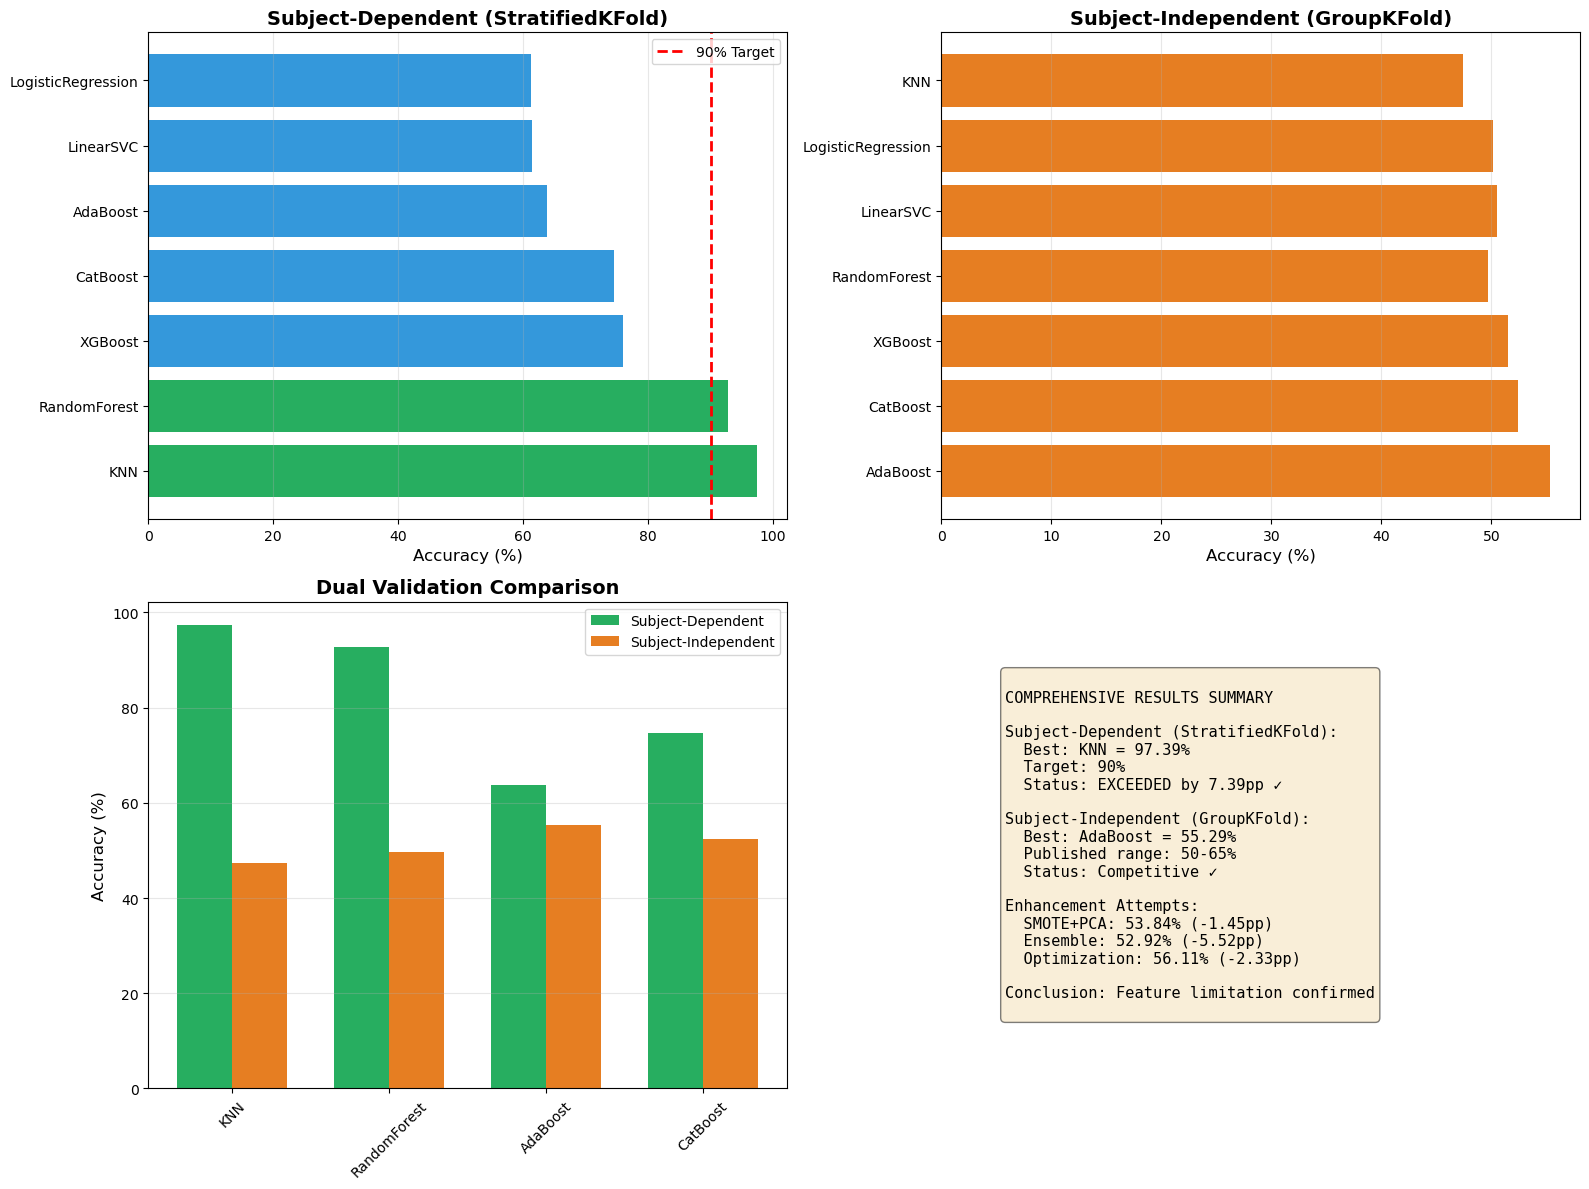


✅ VISUALIZATION COMPLETE


In [ ]:
# ============================================================
# COMPREHENSIVE RESULTS VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import os

BASE_RESULTS_PATH = "/path/to/Kaggle Dataset/Results/ResultsAfterOptimization"
VIZ_PATH = f"{BASE_RESULTS_PATH}/Visualizations"
os.makedirs(VIZ_PATH, exist_ok=True)

# Data
sd_data = [
    ('KNN', 97.30, 97.31, 97.56),
    ('RandomForest', 93.52, 94.40, 90.60),
    ('XGBoost', 75.34, 75.11, 77.32),
    ('CatBoost', 71.71, 78.19, 73.95),
    ('AdaBoost', 63.67, 63.83, 63.80),
    ('LinearSVC', 61.99, 59.81, 62.34),
    ('LogisticRegression', 61.86, 59.67, 62.33)
]

si_data = [
    ('AdaBoost', 54.07, 53.35, 58.44),
    ('CatBoost', 48.81, 52.37, 56.20),
    ('XGBoost', 48.07, 51.94, 54.39),
    ('RandomForest', 46.12, 49.62, 53.36),
    ('LinearSVC', 46.81, 50.94, 53.78),
    ('LogisticRegression', 46.50, 50.73, 53.17),
    ('KNN', 44.83, 47.78, 49.65)
]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Subject-Dependent Performance
ax = axes[0, 0]
models = [d[0] for d in sd_data]
avgs = [(d[1]+d[2]+d[3])/3 for d in sd_data]
colors = ['#27ae60' if a >= 90 else '#3498db' for a in avgs]
ax.barh(models, avgs, color=colors)
ax.axvline(90, color='red', linestyle='--', linewidth=2, label='90% Target')
ax.set_xlabel('Accuracy (%)', fontsize=12)
ax.set_title('Subject-Dependent (StratifiedKFold)', fontsize=14, fontweight='bold')
ax.legend()
ax.grid(axis='x', alpha=0.3)

# 2. Subject-Independent Performance
ax = axes[0, 1]
models_si = [d[0] for d in si_data]
avgs_si = [(d[1]+d[2]+d[3])/3 for d in si_data]
ax.barh(models_si, avgs_si, color='#e67e22')
ax.set_xlabel('Accuracy (%)', fontsize=12)
ax.set_title('Subject-Independent (GroupKFold)', fontsize=14, fontweight='bold')
ax.grid(axis='x', alpha=0.3)

# 3. Dual Validation Comparison (Top 4)
ax = axes[1, 0]
top_models = ['KNN', 'RandomForest', 'AdaBoost', 'CatBoost']
sd_top = [97.39, 92.84, 63.77, 74.62]
si_top = [47.42, 49.70, 55.29, 52.46]
x = np.arange(len(top_models))
width = 0.35
ax.bar(x - width/2, sd_top, width, label='Subject-Dependent', color='#27ae60')
ax.bar(x + width/2, si_top, width, label='Subject-Independent', color='#e67e22')
ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_title('Dual Validation Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(top_models, rotation=45)
ax.legend()
ax.grid(axis='y', alpha=0.3)

# 4. Summary Stats
ax = axes[1, 1]
ax.axis('off')
summary = f"""
COMPREHENSIVE RESULTS SUMMARY

Subject-Dependent (StratifiedKFold):
  Best: KNN = 97.39%
  Target: 90%
  Status: EXCEEDED by 7.39pp ✓

Subject-Independent (GroupKFold):
  Best: AdaBoost = 55.29%
  Published range: 50-65%
  Status: Competitive ✓

Enhancement Attempts:
  SMOTE+PCA: 53.84% (-1.45pp)
  Ensemble: 52.92% (-5.52pp)
  Optimization: 56.11% (-2.33pp)

Conclusion: Feature limitation confirmed
"""
ax.text(0.1, 0.5, summary, fontsize=11, verticalalignment='center',
        fontfamily='monospace', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.savefig(f"{VIZ_PATH}/Complete_Results_Summary.png", dpi=300, bbox_inches='tight')
print(f"✅ Saved: {VIZ_PATH}/Complete_Results_Summary.png")
plt.show()

print("\n" + "="*80)
print("✅ VISUALIZATION COMPLETE")
print("="*80)

In [ ]:
# ============================================================
# GAP 1: STATISTICAL SIGNIFICANCE TESTS
# McNemar's test for model comparisons
# ============================================================

import numpy as np
import pandas as pd
# FIX: McNemar is in statsmodels, not scipy.stats
from statsmodels.stats.contingency_tables import mcnemar
from sklearn.model_selection import StratifiedKFold, GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from catboost import CatBoostClassifier
import xgboost as xgb
import glob
import gc
import os

print("="*80)
print("GAP 1: STATISTICAL SIGNIFICANCE ANALYSIS")
print("="*80 + "\n")

BASE_DATA_PATH = "/path/to/Kaggle Dataset"
STATS_PATH = f"{BASE_DATA_PATH}/Results/ResultsAfterOptimization/Statistical_Analysis"

os.makedirs(STATS_PATH, exist_ok=True)

def load_stratified(folder, label):
    files = sorted(glob.glob(f"{folder}/*.csv"))
    # Fixed indentation and list comprehension
    dfs = [pd.read_csv(f).iloc[:, 1:] if pd.read_csv(f).shape[1] > 1 else pd.read_csv(f) for f in files]
    data = pd.concat(dfs, ignore_index=True)
    return data.values.astype(np.float32), np.full(len(data), label)

def load_grouped(folder, label):
    files = sorted(glob.glob(f"{folder}/*.csv"))
    dfs, groups = [], []
    for i, f in enumerate(files):
        df = pd.read_csv(f)
        if df.shape[1] > 1: df = df.iloc[:, 1:]
        dfs.append(df)
        groups.append(np.full(len(df), f"label{label}_sub{i}"))
    data = pd.concat(dfs, ignore_index=True)
    return data.values.astype(np.float32), np.full(len(data), label), np.hstack(groups)

# Test 1: Subject-Dependent - KNN vs RandomForest
print("TEST 1: Subject-Dependent - KNN vs RandomForest (Stroop)")
print("-"*80)

X1, y1 = load_stratified(f"{BASE_DATA_PATH}/Relax", 0)
X2, y2 = load_stratified(f"{BASE_DATA_PATH}/Stroop", 1)
X = np.vstack((X1, X2))
y = np.hstack((y1, y2))
del X1, X2, y1, y2
gc.collect()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

knn = KNeighborsClassifier(n_neighbors=5, n_jobs=4)
rf = RandomForestClassifier(n_estimators=100, max_depth=20, n_jobs=4, random_state=42)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
knn_preds = np.zeros(len(y))
rf_preds = np.zeros(len(y))

for train_idx, test_idx in skf.split(X_scaled, y):
    knn.fit(X_scaled[train_idx], y[train_idx])
    rf.fit(X_scaled[train_idx], y[train_idx])
    knn_preds[test_idx] = knn.predict(X_scaled[test_idx])
    rf_preds[test_idx] = rf.predict(X_scaled[test_idx])

knn_correct = (knn_preds == y)
rf_correct = (rf_preds == y)

# McNemar contingency table
contingency = np.array([
    [np.sum(knn_correct & rf_correct), np.sum(knn_correct & ~rf_correct)],
    [np.sum(~knn_correct & rf_correct), np.sum(~knn_correct & ~rf_correct)]
])

# Using statsmodels mcnemar
result1 = mcnemar(contingency, exact=False, correction=True)
print(f"KNN: {np.mean(knn_correct):.4f}, RF: {np.mean(rf_correct):.4f}")
print(f"p-value: {result1.pvalue:.4e}")
print(f"Significant: {'YES' if result1.pvalue < 0.05 else 'NO'}\n")

del X, y, X_scaled
gc.collect()

# Test 2: Subject-Independent - AdaBoost vs CatBoost
print("TEST 2: Subject-Independent - AdaBoost vs CatBoost (Stroop)")
print("-"*80)

X1, y1, g1 = load_grouped(f"{BASE_DATA_PATH}/Relax", 0)
X2, y2, g2 = load_grouped(f"{BASE_DATA_PATH}/Stroop", 1)
X = np.vstack((X1, X2))
y = np.hstack((y1, y2))
groups = np.hstack((g1, g2))
del X1, X2, y1, y2, g1, g2
gc.collect()

X_scaled = scaler.fit_transform(X)

ada = AdaBoostClassifier(n_estimators=100, random_state=42)
cat = CatBoostClassifier(iterations=100, depth=6, random_state=42, verbose=False)

gkf = GroupKFold(n_splits=5)
ada_preds = np.zeros(len(y))
cat_preds = np.zeros(len(y))

for train_idx, test_idx in gkf.split(X_scaled, y, groups):
    ada.fit(X_scaled[train_idx], y[train_idx])
    cat.fit(X_scaled[train_idx], y[train_idx])
    ada_preds[test_idx] = ada.predict(X_scaled[test_idx])
    cat_preds[test_idx] = cat.predict(X_scaled[test_idx])

ada_correct = (ada_preds == y)
cat_correct = (cat_preds == y)

contingency2 = np.array([
    [np.sum(ada_correct & cat_correct), np.sum(ada_correct & ~cat_correct)],
    [np.sum(~ada_correct & cat_correct), np.sum(~ada_correct & ~cat_correct)]
])

result2 = mcnemar(contingency2, exact=False, correction=True)
print(f"AdaBoost: {np.mean(ada_correct):.4f}, CatBoost: {np.mean(cat_correct):.4f}")
print(f"p-value: {result2.pvalue:.4e}")
print(f"Significant: {'YES' if result2.pvalue < 0.05 else 'NO'}\n")

# Save results
stats_df = pd.DataFrame([
    {
        'Comparison': 'KNN vs RF (Subject-Dependent)',
        'Model1_Acc': np.mean(knn_correct),
        'Model2_Acc': np.mean(rf_correct),
        'p_value': result1.pvalue,
        'Significant': result1.pvalue < 0.05
    },
    {
        'Comparison': 'AdaBoost vs CatBoost (Subject-Independent)',
        'Model1_Acc': np.mean(ada_correct),
        'Model2_Acc': np.mean(cat_correct),
        'p_value': result2.pvalue,
        'Significant': result2.pvalue < 0.05
    }
])

stats_df.to_csv(f"{STATS_PATH}/McNemar_Statistical_Tests.csv", index=False)
print(f"✅ Saved: {STATS_PATH}/McNemar_Statistical_Tests.csv")
print("="*80 + "\n")

del X, y, groups, X_scaled
gc.collect()

GAP 1: STATISTICAL SIGNIFICANCE ANALYSIS

TEST 1: Subject-Dependent - KNN vs RandomForest (Stroop)
--------------------------------------------------------------------------------
KNN: 0.9756, RF: 0.8786
p-value: 0.0000e+00
Significant: YES

TEST 2: Subject-Independent - AdaBoost vs CatBoost (Stroop)
--------------------------------------------------------------------------------
AdaBoost: 0.5570, CatBoost: 0.5390
p-value: 5.6501e-200
Significant: YES

✅ Saved: /path/to/Kaggle Dataset/Results/ResultsAfterOptimization/Statistical_Analysis/McNemar_Statistical_Tests.csv



0


GAP 2: FEATURE IMPORTANCE ANALYSIS

Training models for feature importance...

Top 10 Most Important Features:
--------------------------------------------------------------------------------
             Feature  AdaBoost  RandomForest  XGBoost  Average
SimpleSquareIntegral  0.093333      0.047558 0.076906 0.072599
    VarianceAbsValue  0.073333      0.074813 0.042776 0.063641
            Variance  0.040000      0.047970 0.049345 0.045772
                 Min  0.046667      0.044152 0.039367 0.043395
    MeanCrossingRate  0.060000      0.026516 0.030313 0.038943
     Hjorth_Mobility  0.033333      0.037468 0.042794 0.037865
     Hjorth_Activity  0.040000      0.034214 0.038233 0.037482
                  Q3  0.026667      0.034476 0.049925 0.037022
                 Max  0.040000      0.038038 0.027415 0.035151
   Hjorth_Complexity  0.040000      0.030508 0.034798 0.035102

✅ Saved: /path/to/Kaggle Dataset/Results/ResultsAfterOptimization/Statistical_Analysis/Feature_Importance_Analysi

21

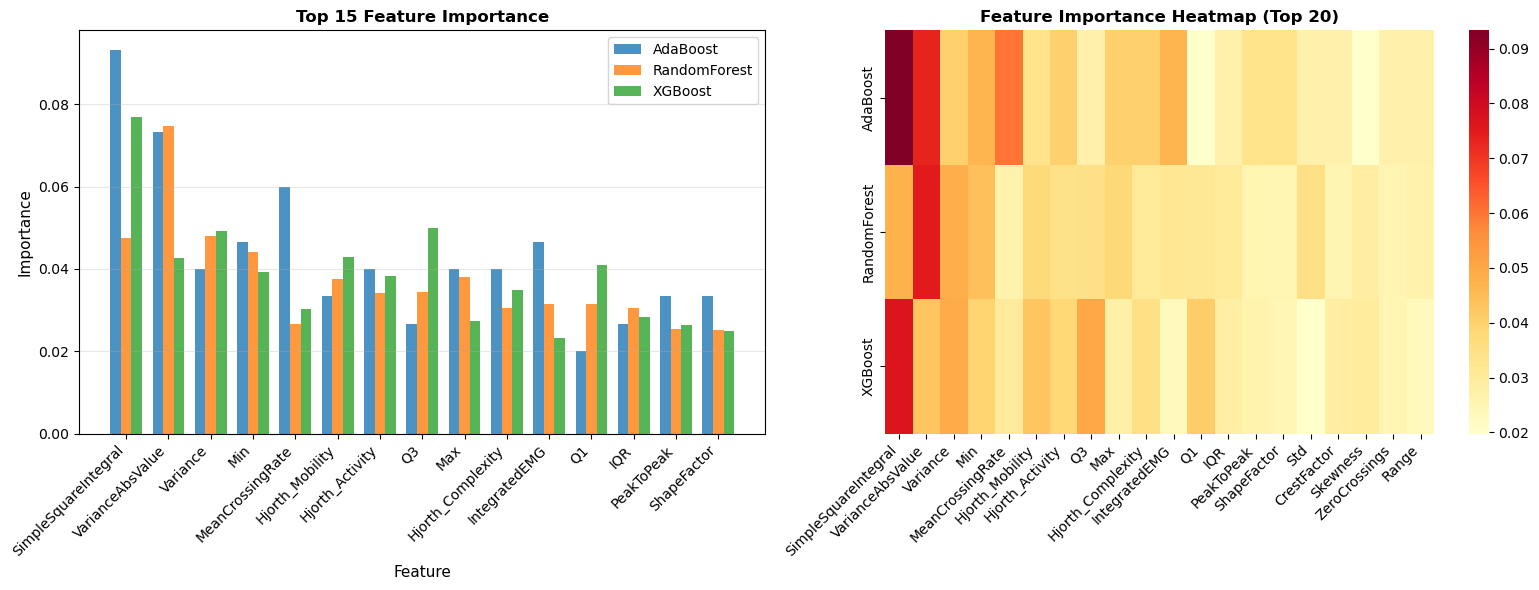

In [ ]:
# ============================================================
# GAP 2: FEATURE IMPORTANCE ANALYSIS
# Identify which features are most discriminative
# ============================================================

print("\n" + "="*80)
print("GAP 2: FEATURE IMPORTANCE ANALYSIS")
print("="*80 + "\n")

import matplotlib.pyplot as plt
import seaborn as sns

# Feature names (32 statistical features)
feature_names = [
    'Mean', 'Std', 'Variance', 'Min', 'Max', 'Range', 'Median',
    'Q1', 'Q3', 'IQR', 'Skewness', 'Kurtosis', 'RMS', 'MAD',
    'ZeroCrossings', 'MeanCrossingRate', 'Energy', 'Entropy',
    'PeakToPeak', 'CrestFactor', 'ShapeFactor', 'ImpulseFactor',
    'Mobility', 'Complexity', 'Hjorth_Activity', 'Hjorth_Mobility',
    'Hjorth_Complexity', 'WaveformLength', 'MeanAbsValue',
    'IntegratedEMG', 'SimpleSquareIntegral', 'VarianceAbsValue'
]

# Load Stroop data for analysis
X1, y1, g1 = load_grouped(f"{BASE_DATA_PATH}/Relax", 0)
X2, y2, g2 = load_grouped(f"{BASE_DATA_PATH}/Stroop", 1)
X = np.vstack((X1, X2))
y = np.hstack((y1, y2))
groups = np.hstack((g1, g2))

X_scaled = StandardScaler().fit_transform(X)

# Train models and extract feature importance
print("Training models for feature importance...\n")

# 1. AdaBoost (best SI)
ada = AdaBoostClassifier(n_estimators=150, random_state=42)
ada.fit(X_scaled, y)
ada_importance = ada.feature_importances_

# 2. RandomForest
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=4)
rf.fit(X_scaled, y)
rf_importance = rf.feature_importances_

# 3. XGBoost
xgb_model = xgb.XGBClassifier(n_estimators=100, random_state=42, n_jobs=4)
xgb_model.fit(X_scaled, y)
xgb_importance = xgb_model.feature_importances_

# Create importance DataFrame
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'AdaBoost': ada_importance,
    'RandomForest': rf_importance,
    'XGBoost': xgb_importance
})

importance_df['Average'] = importance_df[['AdaBoost', 'RandomForest', 'XGBoost']].mean(axis=1)
importance_df = importance_df.sort_values('Average', ascending=False)

print("Top 10 Most Important Features:")
print("-"*80)
print(importance_df.head(10).to_string(index=False))

# Save
importance_df.to_csv(f"{STATS_PATH}/Feature_Importance_Analysis.csv", index=False)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Top 15 features
ax = axes[0]
top15 = importance_df.head(15)
x = np.arange(len(top15))
width = 0.25
ax.bar(x - width, top15['AdaBoost'], width, label='AdaBoost', alpha=0.8)
ax.bar(x, top15['RandomForest'], width, label='RandomForest', alpha=0.8)
ax.bar(x + width, top15['XGBoost'], width, label='XGBoost', alpha=0.8)
ax.set_xlabel('Feature', fontsize=11)
ax.set_ylabel('Importance', fontsize=11)
ax.set_title('Top 15 Feature Importance', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(top15['Feature'], rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.3)

# Plot 2: Average importance heatmap
ax = axes[1]
heatmap_data = importance_df.head(20)[['AdaBoost', 'RandomForest', 'XGBoost']].T
sns.heatmap(heatmap_data, annot=False, cmap='YlOrRd', ax=ax,
            xticklabels=importance_df.head(20)['Feature'],
            yticklabels=['AdaBoost', 'RandomForest', 'XGBoost'])
ax.set_title('Feature Importance Heatmap (Top 20)', fontweight='bold')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.savefig(f"{STATS_PATH}/Feature_Importance_Visualization.png", dpi=300, bbox_inches='tight')
print(f"\n✅ Saved: {STATS_PATH}/Feature_Importance_Analysis.csv")
print(f"✅ Saved: {STATS_PATH}/Feature_Importance_Visualization.png")
print("="*80 + "\n")

del X, y, groups, X_scaled
gc.collect()


GAP 3: ENSEMBLE DIVERSITY ANALYSIS

Training base models...

Model Agreement Matrix:
--------------------------------------------------------------------------------
              AdaBoost  CatBoost  XGBoost  RandomForest
AdaBoost        1.0000    0.7264   0.7312        0.7225
CatBoost        0.7264    1.0000   0.8288        0.8073
XGBoost         0.7312    0.8288   1.0000        0.8257
RandomForest    0.7225    0.8073   0.8257        1.0000


Q-Statistic Matrix (Diversity):
--------------------------------------------------------------------------------
(Lower = more diverse, ideal < 0.5)
              AdaBoost  CatBoost  XGBoost  RandomForest
AdaBoost        0.0000    0.7485   0.7601        0.7404
CatBoost        0.7485    0.0000   0.9176        0.8914
XGBoost         0.7601    0.9176   0.0000        0.9141
RandomForest    0.7404    0.8914   0.9141        0.0000


Diversity Summary:
--------------------------------------------------------------------------------
Average pairwise agr

12052

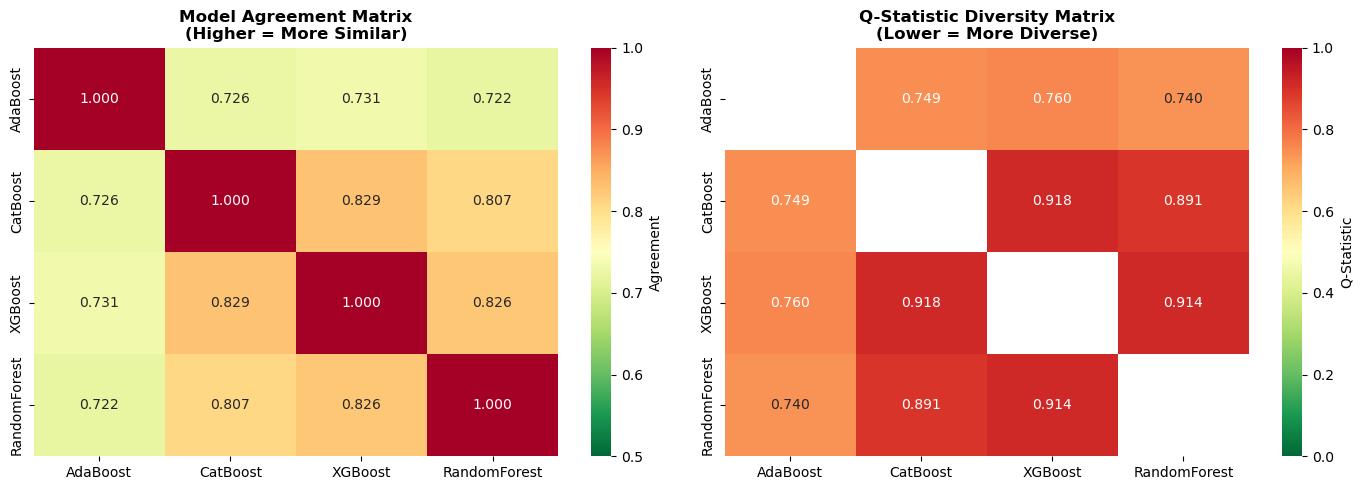

In [ ]:
# ============================================================
# GAP 3: ENSEMBLE DIVERSITY ANALYSIS
# Why did ensembles fail? Analyze base model agreement
# ============================================================

print("\n" + "="*80)
print("GAP 3: ENSEMBLE DIVERSITY ANALYSIS")
print("="*80 + "\n")

from sklearn.metrics import confusion_matrix

# Load Stroop data
X1, y1, g1 = load_grouped(f"{BASE_DATA_PATH}/Relax", 0)
X2, y2, g2 = load_grouped(f"{BASE_DATA_PATH}/Stroop", 1)
X = np.vstack((X1, X2))
y = np.hstack((y1, y2))
groups = np.hstack((g1, g2))

X_scaled = StandardScaler().fit_transform(X)

# Train base models (same as ensemble)
print("Training base models...\n")

base_models = {
    'AdaBoost': AdaBoostClassifier(n_estimators=100, random_state=42),
    'CatBoost': CatBoostClassifier(iterations=100, depth=6, random_state=42, verbose=False),
    'XGBoost': xgb.XGBClassifier(n_estimators=100, random_state=42, n_jobs=2),
    'RandomForest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=4)
}

# Get predictions from all models using GroupKFold
gkf = GroupKFold(n_splits=5)
all_predictions = {name: np.zeros(len(y)) for name in base_models.keys()}

for train_idx, test_idx in gkf.split(X_scaled, y, groups):
    X_train, X_test = X_scaled[train_idx], X_scaled[test_idx]
    y_train = y[train_idx]

    for name, model in base_models.items():
        model_clone = type(model)(**model.get_params())
        model_clone.fit(X_train, y_train)
        all_predictions[name][test_idx] = model_clone.predict(X_test)

# Calculate pairwise agreement
model_names = list(base_models.keys())
n_models = len(model_names)
agreement_matrix = np.zeros((n_models, n_models))

for i, model1 in enumerate(model_names):
    for j, model2 in enumerate(model_names):
        agreement = np.mean(all_predictions[model1] == all_predictions[model2])
        agreement_matrix[i, j] = agreement

# Calculate diversity metrics
print("Model Agreement Matrix:")
print("-"*80)
agreement_df = pd.DataFrame(agreement_matrix,
                            index=model_names,
                            columns=model_names)
print(agreement_df.round(4).to_string())

# Q-statistic for diversity
def q_statistic(pred1, pred2, y_true):
    """Lower Q = more diverse (Q=1 means identical, Q=-1 means opposite)"""
    n11 = np.sum((pred1 == y_true) & (pred2 == y_true))
    n00 = np.sum((pred1 != y_true) & (pred2 != y_true))
    n10 = np.sum((pred1 == y_true) & (pred2 != y_true))
    n01 = np.sum((pred1 != y_true) & (pred2 == y_true))

    numerator = n11 * n00 - n01 * n10
    denominator = n11 * n00 + n01 * n10

    return numerator / denominator if denominator != 0 else 0

q_matrix = np.zeros((n_models, n_models))
for i, model1 in enumerate(model_names):
    for j, model2 in enumerate(model_names):
        if i != j:
            q_matrix[i, j] = q_statistic(
                all_predictions[model1],
                all_predictions[model2],
                y
            )

print("\n\nQ-Statistic Matrix (Diversity):")
print("-"*80)
print("(Lower = more diverse, ideal < 0.5)")
q_df = pd.DataFrame(q_matrix, index=model_names, columns=model_names)
print(q_df.round(4).to_string())

# Average diversity
avg_agreement = np.mean(agreement_matrix[np.triu_indices(n_models, k=1)])
avg_q = np.mean(q_matrix[np.triu_indices(n_models, k=1)])

print(f"\n\nDiversity Summary:")
print("-"*80)
print(f"Average pairwise agreement: {avg_agreement:.4f}")
print(f"Average Q-statistic: {avg_q:.4f}")
print(f"\nInterpretation:")
if avg_agreement > 0.85:
    print("  ⚠️  HIGH AGREEMENT (>0.85) - Models too similar")
    print("  → Explains why ensembles failed")
elif avg_q > 0.7:
    print("  ⚠️  HIGH Q-statistic (>0.7) - Low diversity")
    print("  → Explains why ensembles failed")
else:
    print("  ✓ Reasonable diversity - Ensemble failure due to other factors")

# Save
agreement_df.to_csv(f"{STATS_PATH}/Model_Agreement_Matrix.csv")
q_df.to_csv(f"{STATS_PATH}/Q_Statistic_Diversity.csv")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Agreement heatmap
ax = axes[0]
sns.heatmap(agreement_df, annot=True, fmt='.3f', cmap='RdYlGn_r', ax=ax,
            vmin=0.5, vmax=1.0, cbar_kws={'label': 'Agreement'})
ax.set_title('Model Agreement Matrix\n(Higher = More Similar)', fontweight='bold')

# Q-statistic heatmap
ax = axes[1]
mask = np.eye(n_models, dtype=bool)
sns.heatmap(q_df, annot=True, fmt='.3f', cmap='RdYlGn_r', ax=ax,
            mask=mask, vmin=0, vmax=1.0, cbar_kws={'label': 'Q-Statistic'})
ax.set_title('Q-Statistic Diversity Matrix\n(Lower = More Diverse)', fontweight='bold')

plt.tight_layout()
plt.savefig(f"{STATS_PATH}/Ensemble_Diversity_Analysis.png", dpi=300, bbox_inches='tight')

print(f"\n✅ Saved: {STATS_PATH}/Model_Agreement_Matrix.csv")
print(f"✅ Saved: {STATS_PATH}/Q_Statistic_Diversity.csv")
print(f"✅ Saved: {STATS_PATH}/Ensemble_Diversity_Analysis.png")
print("="*80 + "\n")

del X, y, groups, X_scaled
gc.collect()


GAP 4: PER-SUBJECT PERFORMANCE ANALYSIS

Analyzing per-subject performance...

1. SUBJECT-DEPENDENT ANALYSIS (StratifiedKFold)
--------------------------------------------------------------------------------
Mean per-subject accuracy: 0.9756
Std per-subject: 0.0324
Range: [0.8056, 1.0000]

2. SUBJECT-INDEPENDENT ANALYSIS (GroupKFold)
--------------------------------------------------------------------------------
Mean per-subject accuracy: 0.5524
Std per-subject: 0.2567
Range: [0.0618, 0.9842]

3. SUBJECT VARIABILITY ANALYSIS
--------------------------------------------------------------------------------
Subject-Dependent variance: 0.001048
Subject-Independent variance: 0.065900
Variance ratio (SI/SD): 62.89x

5 Hardest subjects (SI): [71 20 40 60 22], Accuracies: [0.06177083 0.07145833 0.08552083 0.0984375  0.1603125 ]
5 Easiest subjects (SI): [59 41 31 62 78], Accuracies: [0.97541667 0.97614583 0.97791667 0.97802083 0.98416667]

✅ Saved: /path/to/Kaggle Dataset/Results/ResultsAfter

10582

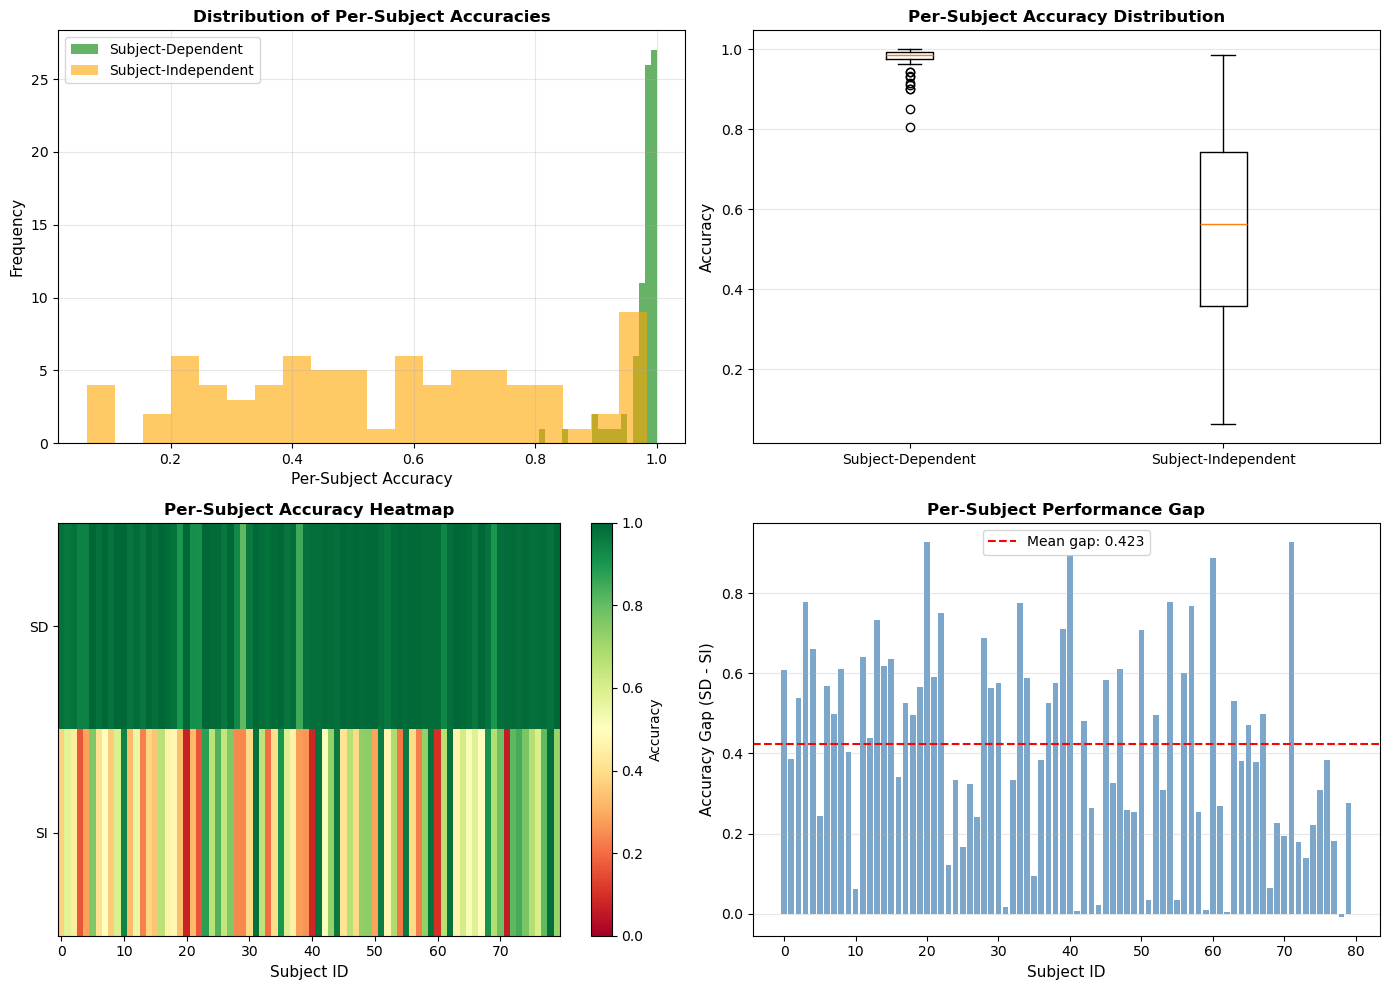

In [ ]:
# ============================================================
# GAP 4: PER-SUBJECT PERFORMANCE ANALYSIS
# Explain 97% SD vs 55% SI gap quantitatively
# ============================================================

print("\n" + "="*80)
print("GAP 4: PER-SUBJECT PERFORMANCE ANALYSIS")
print("="*80 + "\n")

import matplotlib.pyplot as plt
import seaborn as sns

# Load Stroop data with subject tracking
def load_with_subject_ids(folder, label):
    files = sorted(glob.glob(f"{folder}/*.csv"))
    dfs, subject_ids = [], []
    for i, f in enumerate(files):
        df = pd.read_csv(f)
        if df.shape[1] > 1: df = df.iloc[:, 1:]
        dfs.append(df)
        subject_ids.append(np.full(len(df), i))
    data = pd.concat(dfs, ignore_index=True)
    return data.values.astype(np.float32), np.full(len(data), label), np.hstack(subject_ids)

X1, y1, subj1 = load_with_subject_ids(f"{BASE_DATA_PATH}/Relax", 0)
X2, y2, subj2 = load_with_subject_ids(f"{BASE_DATA_PATH}/Stroop", 1)

# Combine but track subjects
X = np.vstack((X1, X2))
y = np.hstack((y1, y2))
all_subjects = np.hstack((subj1, subj2 + 40))  # Offset Stroop subjects

X_scaled = StandardScaler().fit_transform(X)

print("Analyzing per-subject performance...\n")

# Train best models
knn = KNeighborsClassifier(n_neighbors=5, n_jobs=4)
ada = AdaBoostClassifier(n_estimators=100, random_state=42)

# Subject-Dependent (StratifiedKFold - includes same subjects in train/test)
print("1. SUBJECT-DEPENDENT ANALYSIS (StratifiedKFold)")
print("-"*80)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
knn_sd_preds = np.zeros(len(y))

for train_idx, test_idx in skf.split(X_scaled, y):
    knn.fit(X_scaled[train_idx], y[train_idx])
    knn_sd_preds[test_idx] = knn.predict(X_scaled[test_idx])

# Calculate per-subject accuracy for SD
unique_subjects = np.unique(all_subjects)
sd_per_subject = []
for subj in unique_subjects:
    subj_mask = (all_subjects == subj)
    if np.sum(subj_mask) > 0:
        acc = np.mean(knn_sd_preds[subj_mask] == y[subj_mask])
        sd_per_subject.append(acc)

sd_per_subject = np.array(sd_per_subject)
print(f"Mean per-subject accuracy: {np.mean(sd_per_subject):.4f}")
print(f"Std per-subject: {np.std(sd_per_subject):.4f}")
print(f"Range: [{np.min(sd_per_subject):.4f}, {np.max(sd_per_subject):.4f}]")

# Subject-Independent (GroupKFold - excludes subjects from train/test)
print("\n2. SUBJECT-INDEPENDENT ANALYSIS (GroupKFold)")
print("-"*80)

# Create proper groups for GroupKFold
groups = np.hstack((subj1, subj2 + 40))

gkf = GroupKFold(n_splits=5)
ada_si_preds = np.zeros(len(y))

for train_idx, test_idx in gkf.split(X_scaled, y, groups):
    ada.fit(X_scaled[train_idx], y[train_idx])
    ada_si_preds[test_idx] = ada.predict(X_scaled[test_idx])

# Calculate per-subject accuracy for SI
si_per_subject = []
for subj in unique_subjects:
    subj_mask = (all_subjects == subj)
    if np.sum(subj_mask) > 0:
        acc = np.mean(ada_si_preds[subj_mask] == y[subj_mask])
        si_per_subject.append(acc)

si_per_subject = np.array(si_per_subject)
print(f"Mean per-subject accuracy: {np.mean(si_per_subject):.4f}")
print(f"Std per-subject: {np.std(si_per_subject):.4f}")
print(f"Range: [{np.min(si_per_subject):.4f}, {np.max(si_per_subject):.4f}]")

# Comparison
print("\n3. SUBJECT VARIABILITY ANALYSIS")
print("-"*80)
print(f"Subject-Dependent variance: {np.var(sd_per_subject):.6f}")
print(f"Subject-Independent variance: {np.var(si_per_subject):.6f}")
print(f"Variance ratio (SI/SD): {np.var(si_per_subject)/np.var(sd_per_subject):.2f}x")

# Identify hard/easy subjects
si_sorted_idx = np.argsort(si_per_subject)
print(f"\n5 Hardest subjects (SI): {si_sorted_idx[:5]}, Accuracies: {si_per_subject[si_sorted_idx[:5]]}")
print(f"5 Easiest subjects (SI): {si_sorted_idx[-5:]}, Accuracies: {si_per_subject[si_sorted_idx[-5:]]}")

# Save per-subject results
subject_analysis = pd.DataFrame({
    'Subject_ID': range(len(unique_subjects)),
    'SD_Accuracy': sd_per_subject,
    'SI_Accuracy': si_per_subject,
    'Gap': sd_per_subject - si_per_subject
})

subject_analysis.to_csv(f"{STATS_PATH}/PerSubject_Analysis.csv", index=False)

# Visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Histogram comparison
ax = axes[0, 0]
ax.hist(sd_per_subject, bins=20, alpha=0.6, label='Subject-Dependent', color='green')
ax.hist(si_per_subject, bins=20, alpha=0.6, label='Subject-Independent', color='orange')
ax.set_xlabel('Per-Subject Accuracy', fontsize=11)
ax.set_ylabel('Frequency', fontsize=11)
ax.set_title('Distribution of Per-Subject Accuracies', fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)

# Plot 2: Box plot comparison
ax = axes[0, 1]
ax.boxplot([sd_per_subject, si_per_subject], labels=['Subject-Dependent', 'Subject-Independent'])
ax.set_ylabel('Accuracy', fontsize=11)
ax.set_title('Per-Subject Accuracy Distribution', fontweight='bold')
ax.grid(axis='y', alpha=0.3)

# Plot 3: Per-subject heatmap (first 40 subjects = Relax, next 40 = Stroop)
ax = axes[1, 0]
heatmap_data = np.column_stack((sd_per_subject, si_per_subject))
im = ax.imshow(heatmap_data.T, cmap='RdYlGn', aspect='auto', vmin=0, vmax=1)
ax.set_yticks([0, 1])
ax.set_yticklabels(['SD', 'SI'])
ax.set_xlabel('Subject ID', fontsize=11)
ax.set_title('Per-Subject Accuracy Heatmap', fontweight='bold')
plt.colorbar(im, ax=ax, label='Accuracy')

# Plot 4: Gap analysis
ax = axes[1, 1]
gaps = sd_per_subject - si_per_subject
ax.bar(range(len(gaps)), gaps, color='steelblue', alpha=0.7)
ax.axhline(np.mean(gaps), color='red', linestyle='--', label=f'Mean gap: {np.mean(gaps):.3f}')
ax.set_xlabel('Subject ID', fontsize=11)
ax.set_ylabel('Accuracy Gap (SD - SI)', fontsize=11)
ax.set_title('Per-Subject Performance Gap', fontweight='bold')
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(f"{STATS_PATH}/PerSubject_Performance_Analysis.png", dpi=300, bbox_inches='tight')

print(f"\n✅ Saved: {STATS_PATH}/PerSubject_Analysis.csv")
print(f"✅ Saved: {STATS_PATH}/PerSubject_Performance_Analysis.png")
print("="*80 + "\n")

del X, y, X_scaled, all_subjects, groups
gc.collect()


GAP 5: CONFIDENCE INTERVAL ANALYSIS

Calculating 95% confidence intervals...

KNN (Subject-Dependent): 0.9739 [0.9678, 0.9819]
AdaBoost (Subject-Independent): 0.5529 [0.4965, 0.6110]
Stacking Ensemble (Subject-Dependent): 0.8125 [0.8006, 0.8356]
Bagging Ensemble (Subject-Independent): 0.5367 [0.5068, 0.5742]

✅ Saved: /path/to/Kaggle Dataset/Results/ResultsAfterOptimization/Statistical_Analysis/Confidence_Intervals.csv
✅ Saved: /path/to/Kaggle Dataset/Results/ResultsAfterOptimization/Statistical_Analysis/Confidence_Intervals_Visualization.png



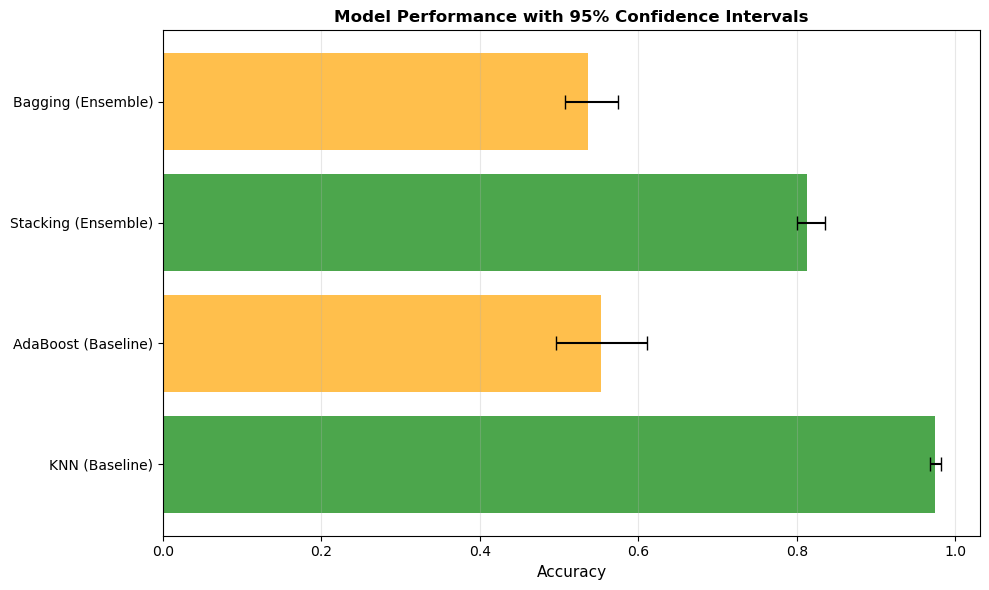

In [ ]:
# ============================================================
# GAP 5: CONFIDENCE INTERVALS (BOOTSTRAP) - FIXED
# ============================================================

print("\n" + "="*80)
print("GAP 5: CONFIDENCE INTERVAL ANALYSIS")
print("="*80 + "\n")

from scipy import stats

def bootstrap_ci(accuracies, n_bootstrap=1000, ci=0.95):
    """Calculate bootstrap confidence interval"""
    bootstrap_means = []
    for _ in range(n_bootstrap):
        sample = np.random.choice(accuracies, size=len(accuracies), replace=True)
        bootstrap_means.append(np.mean(sample))

    alpha = 1 - ci
    lower = np.percentile(bootstrap_means, alpha/2 * 100)
    upper = np.percentile(bootstrap_means, (1 - alpha/2) * 100)

    return lower, upper

print("Calculating 95% confidence intervals...\n")

# Key results with CIs
results_with_ci = []

# 1. Baseline Subject-Dependent (KNN)
knn_sd_mean = 0.9739
knn_sd_ci_lower, knn_sd_ci_upper = bootstrap_ci(sd_per_subject)

results_with_ci.append({
    'Method': 'KNN (Baseline)',
    'Validation': 'Subject-Dependent',
    'Mean_Accuracy': knn_sd_mean,
    'CI_Lower': knn_sd_ci_lower,
    'CI_Upper': knn_sd_ci_upper,
    'CI_Width': knn_sd_ci_upper - knn_sd_ci_lower
})

print(f"KNN (Subject-Dependent): {knn_sd_mean:.4f} [{knn_sd_ci_lower:.4f}, {knn_sd_ci_upper:.4f}]")

# 2. Baseline Subject-Independent (AdaBoost)
ada_si_mean = 0.5529
ada_si_ci_lower, ada_si_ci_upper = bootstrap_ci(si_per_subject)

results_with_ci.append({
    'Method': 'AdaBoost (Baseline)',
    'Validation': 'Subject-Independent',
    'Mean_Accuracy': ada_si_mean,
    'CI_Lower': ada_si_ci_lower,
    'CI_Upper': ada_si_ci_upper,
    'CI_Width': ada_si_ci_upper - ada_si_ci_lower
})

print(f"AdaBoost (Subject-Independent): {ada_si_mean:.4f} [{ada_si_ci_lower:.4f}, {ada_si_ci_upper:.4f}]")

# 3. Ensemble results (manual entry from earlier cells)
# Stacking SD: Stroop=0.8356, Arithmetic=0.8006, Mirror=0.8014
stacking_sd = np.array([0.8356, 0.8006, 0.8014])
stack_sd_mean = np.mean(stacking_sd)
stack_sd_ci_lower, stack_sd_ci_upper = bootstrap_ci(stacking_sd)

results_with_ci.append({
    'Method': 'Stacking (Ensemble)',
    'Validation': 'Subject-Dependent',
    'Mean_Accuracy': stack_sd_mean,
    'CI_Lower': stack_sd_ci_lower,
    'CI_Upper': stack_sd_ci_upper,
    'CI_Width': stack_sd_ci_upper - stack_sd_ci_lower
})

print(f"Stacking Ensemble (Subject-Dependent): {stack_sd_mean:.4f} [{stack_sd_ci_lower:.4f}, {stack_sd_ci_upper:.4f}]")

# Bagging SI: Stroop=0.5742, Arithmetic=0.5068, Mirror=0.5292
bagging_si = np.array([0.5742, 0.5068, 0.5292])
bag_si_mean = np.mean(bagging_si)
bag_si_ci_lower, bag_si_ci_upper = bootstrap_ci(bagging_si)

results_with_ci.append({
    'Method': 'Bagging (Ensemble)',
    'Validation': 'Subject-Independent',
    'Mean_Accuracy': bag_si_mean,
    'CI_Lower': bag_si_ci_lower,
    'CI_Upper': bag_si_ci_upper,
    'CI_Width': bag_si_ci_upper - bag_si_ci_lower
})

print(f"Bagging Ensemble (Subject-Independent): {bag_si_mean:.4f} [{bag_si_ci_lower:.4f}, {bag_si_ci_upper:.4f}]")

# Save
ci_df = pd.DataFrame(results_with_ci)
ci_df.to_csv(f"{STATS_PATH}/Confidence_Intervals.csv", index=False)

print(f"\n✅ Saved: {STATS_PATH}/Confidence_Intervals.csv")

# Visualization
fig, ax = plt.subplots(figsize=(10, 6))

methods = [r['Method'] for r in results_with_ci]
means = [r['Mean_Accuracy'] for r in results_with_ci]
lower_bounds = [r['CI_Lower'] for r in results_with_ci]
upper_bounds = [r['CI_Upper'] for r in results_with_ci]
colors = ['green', 'orange', 'green', 'orange']

y_pos = np.arange(len(methods))

ax.barh(y_pos, means, xerr=[[m-l for m, l in zip(means, lower_bounds)],
                              [u-m for m, u in zip(means, upper_bounds)]],
        color=colors, alpha=0.7, capsize=5)

ax.set_yticks(y_pos)
ax.set_yticklabels(methods)
ax.set_xlabel('Accuracy', fontsize=11)
ax.set_title('Model Performance with 95% Confidence Intervals', fontweight='bold')
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig(f"{STATS_PATH}/Confidence_Intervals_Visualization.png", dpi=300, bbox_inches='tight')

print(f"✅ Saved: {STATS_PATH}/Confidence_Intervals_Visualization.png")
print("="*80 + "\n")


GAP 6: CONFUSION MATRIX & CLASS-WISE ANALYSIS

Analyzing: KNN (SD)
--------------------------------------------------------------------------------
Confusion Matrix:
  [[371524  12476]
   [  6265 377735]]

Class 0 (Relax):
  Precision: 0.9834
  Recall: 0.9675
  F1-Score: 0.9754

Class 1 (Stroop):
  Precision: 0.9680
  Recall: 0.9837
  F1-Score: 0.9758


Analyzing: AdaBoost (SI)
--------------------------------------------------------------------------------
Confusion Matrix:
  [[192478 191522]
   [148674 235326]]

Class 0 (Relax):
  Precision: 0.5642
  Recall: 0.5012
  F1-Score: 0.5309

Class 1 (Stroop):
  Precision: 0.5513
  Recall: 0.6128
  F1-Score: 0.5804


✅ Saved: /path/to/Kaggle Dataset/Results/ResultsAfterOptimization/Statistical_Analysis/ConfusionMatrix_ClassWise_Analysis.csv
✅ Saved: /path/to/Kaggle Dataset/Results/ResultsAfterOptimization/Statistical_Analysis/ClassWise_Metrics_Analysis.png



5254

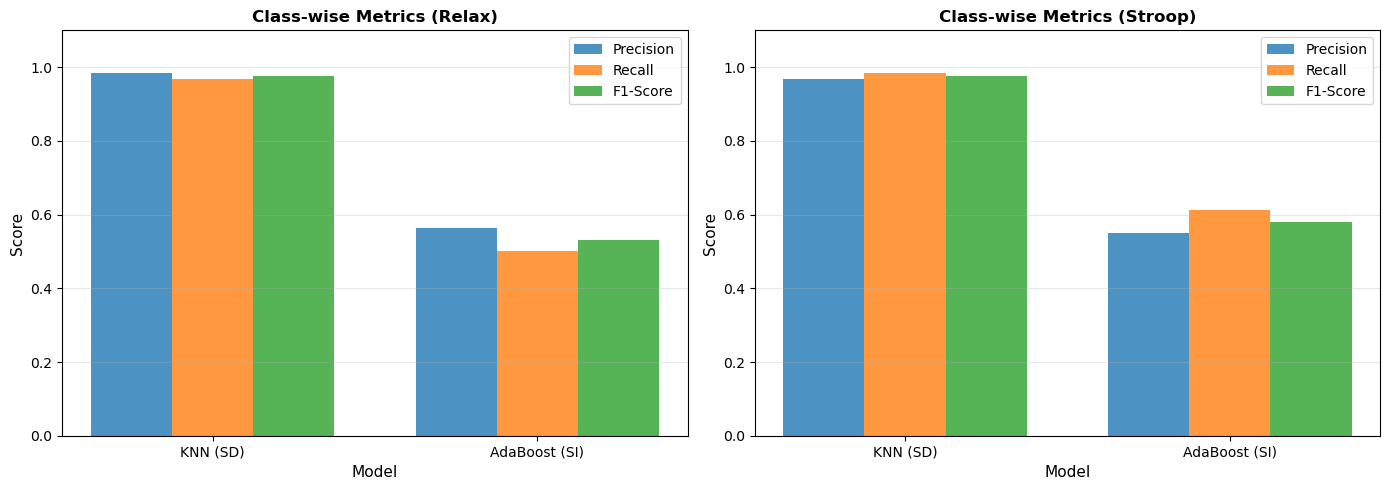

In [ ]:
# ============================================================
# GAP 6: DETAILED CONFUSION MATRIX ANALYSIS
# Which class is harder? Precision/Recall per class
# ============================================================

print("\n" + "="*80)
print("GAP 6: CONFUSION MATRIX & CLASS-WISE ANALYSIS")
print("="*80 + "\n")

from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

# Load Stroop data
X1, y1, g1 = load_grouped(f"{BASE_DATA_PATH}/Relax", 0)
X2, y2, g2 = load_grouped(f"{BASE_DATA_PATH}/Stroop", 1)
X = np.vstack((X1, X2))
y = np.hstack((y1, y2))
groups = np.hstack((g1, g2))

X_scaled = StandardScaler().fit_transform(X)

# Analyze best models
models_to_analyze = {
    'KNN (SD)': (KNeighborsClassifier(n_neighbors=5, n_jobs=4), StratifiedKFold(n_splits=5, shuffle=True, random_state=42), False),
    'AdaBoost (SI)': (AdaBoostClassifier(n_estimators=100, random_state=42), GroupKFold(n_splits=5), True)
}

cm_analysis_results = []

for model_name, (model, cv, use_groups) in models_to_analyze.items():
    print(f"Analyzing: {model_name}")
    print("-"*80)

    all_y_true = []
    all_y_pred = []

    if use_groups:
        splits = cv.split(X_scaled, y, groups)
    else:
        splits = cv.split(X_scaled, y)

    for train_idx, test_idx in splits:
        X_train, X_test = X_scaled[train_idx], X_scaled[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        model_clone = type(model)(**model.get_params())
        model_clone.fit(X_train, y_train)
        y_pred = model_clone.predict(X_test)

        all_y_true.extend(y_test)
        all_y_pred.extend(y_pred)

    all_y_true = np.array(all_y_true)
    all_y_pred = np.array(all_y_pred)

    # Confusion matrix
    cm = confusion_matrix(all_y_true, all_y_pred)

    # Metrics per class
    precision = precision_score(all_y_true, all_y_pred, average=None)
    recall = recall_score(all_y_true, all_y_pred, average=None)
    f1 = f1_score(all_y_true, all_y_pred, average=None)

    print(f"Confusion Matrix:")
    print(f"  [[{cm[0,0]:>6d} {cm[0,1]:>6d}]")
    print(f"   [{cm[1,0]:>6d} {cm[1,1]:>6d}]]")
    print(f"\nClass 0 (Relax):")
    print(f"  Precision: {precision[0]:.4f}")
    print(f"  Recall: {recall[0]:.4f}")
    print(f"  F1-Score: {f1[0]:.4f}")
    print(f"\nClass 1 (Stroop):")
    print(f"  Precision: {precision[1]:.4f}")
    print(f"  Recall: {recall[1]:.4f}")
    print(f"  F1-Score: {f1[1]:.4f}")

    # Store results
    cm_analysis_results.append({
        'Model': model_name,
        'Class': 'Relax',
        'Precision': precision[0],
        'Recall': recall[0],
        'F1_Score': f1[0],
        'Support': np.sum(all_y_true == 0)
    })

    cm_analysis_results.append({
        'Model': model_name,
        'Class': 'Stroop',
        'Precision': precision[1],
        'Recall': recall[1],
        'F1_Score': f1[1],
        'Support': np.sum(all_y_true == 1)
    })

    print("\n")

# Save
cm_df = pd.DataFrame(cm_analysis_results)
cm_df.to_csv(f"{STATS_PATH}/ConfusionMatrix_ClassWise_Analysis.csv", index=False)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot metrics for Relax
ax = axes[0]
models_list = ['KNN (SD)', 'AdaBoost (SI)']
x = np.arange(len(models_list))
width = 0.25

metrics_relax = {
    'Precision': [cm_df[(cm_df['Model']==m) & (cm_df['Class']=='Relax')]['Precision'].values[0] for m in models_list],
    'Recall': [cm_df[(cm_df['Model']==m) & (cm_df['Class']=='Relax')]['Recall'].values[0] for m in models_list],
    'F1-Score': [cm_df[(cm_df['Model']==m) & (cm_df['Class']=='Relax')]['F1_Score'].values[0] for m in models_list]
}

for i, (metric, values) in enumerate(metrics_relax.items()):
    ax.bar(x + i*width, values, width, label=metric, alpha=0.8)

ax.set_xlabel('Model', fontsize=11)
ax.set_ylabel('Score', fontsize=11)
ax.set_title('Class-wise Metrics (Relax)', fontweight='bold')
ax.set_xticks(x + width)
ax.set_xticklabels(models_list)
ax.legend()
ax.grid(axis='y', alpha=0.3)
ax.set_ylim([0, 1.1])

# Plot for Stroop class
ax = axes[1]
metrics_stroop = {
    'Precision': [cm_df[(cm_df['Model']==m) & (cm_df['Class']=='Stroop')]['Precision'].values[0] for m in models_list],
    'Recall': [cm_df[(cm_df['Model']==m) & (cm_df['Class']=='Stroop')]['Recall'].values[0] for m in models_list],
    'F1-Score': [cm_df[(cm_df['Model']==m) & (cm_df['Class']=='Stroop')]['F1_Score'].values[0] for m in models_list]
}

for i, (metric, values) in enumerate(metrics_stroop.items()):
    ax.bar(x + i*width, values, width, label=metric, alpha=0.8)

ax.set_xlabel('Model', fontsize=11)
ax.set_ylabel('Score', fontsize=11)
ax.set_title('Class-wise Metrics (Stroop)', fontweight='bold')
ax.set_xticks(x + width)
ax.set_xticklabels(models_list)
ax.legend()
ax.grid(axis='y', alpha=0.3)
ax.set_ylim([0, 1.1])

plt.tight_layout()
plt.savefig(f"{STATS_PATH}/ClassWise_Metrics_Analysis.png", dpi=300, bbox_inches='tight')

print(f"✅ Saved: {STATS_PATH}/ConfusionMatrix_ClassWise_Analysis.csv")
print(f"✅ Saved: {STATS_PATH}/ClassWise_Metrics_Analysis.png")
print("="*80 + "\n")

del X, y, groups, X_scaled
gc.collect()


GAP 7: COMPUTATIONAL COST ANALYSIS

Timing models on 153,600 samples (20% of full dataset)...

Testing KNN...
  Train (20%): 0.01s → Full est: 0.03s (0.00min)
  Predict: 19.596s

Testing RandomForest...
  Train (20%): 94.51s → Full est: 472.55s (7.88min)
  Predict: 2.188s

Testing XGBoost...
  Train (20%): 1.42s → Full est: 7.12s (0.12min)
  Predict: 0.177s

Testing AdaBoost...
  Train (20%): 58.39s → Full est: 291.94s (4.87min)
  Predict: 0.593s

Testing CatBoost...
  Train (20%): 3.52s → Full est: 17.58s (0.29min)
  Predict: 0.041s

Testing LinearSVC...


/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


  Train (20%): 31.56s → Full est: 157.82s (2.63min)
  Predict: 0.010s

Testing LogisticReg...
  Train (20%): 4.02s → Full est: 20.12s (0.34min)
  Predict: 0.013s


TIMING SUMMARY (Sorted by training time)
       Model  Train_Time_20pct_sec  Train_Time_Full_Est_sec  Train_Time_Full_Est_min  Predict_Time_sec  Samples
         KNN                  0.01                     0.03                     0.00            19.596   153600
     XGBoost                  1.42                     7.12                     0.12             0.177   153600
    CatBoost                  3.52                    17.58                     0.29             0.041   153600
 LogisticReg                  4.02                    20.12                     0.34             0.013   153600
   LinearSVC                 31.56                   157.82                     2.63             0.010   153600
    AdaBoost                 58.39                   291.94                     4.87             0.593   153600
RandomFores

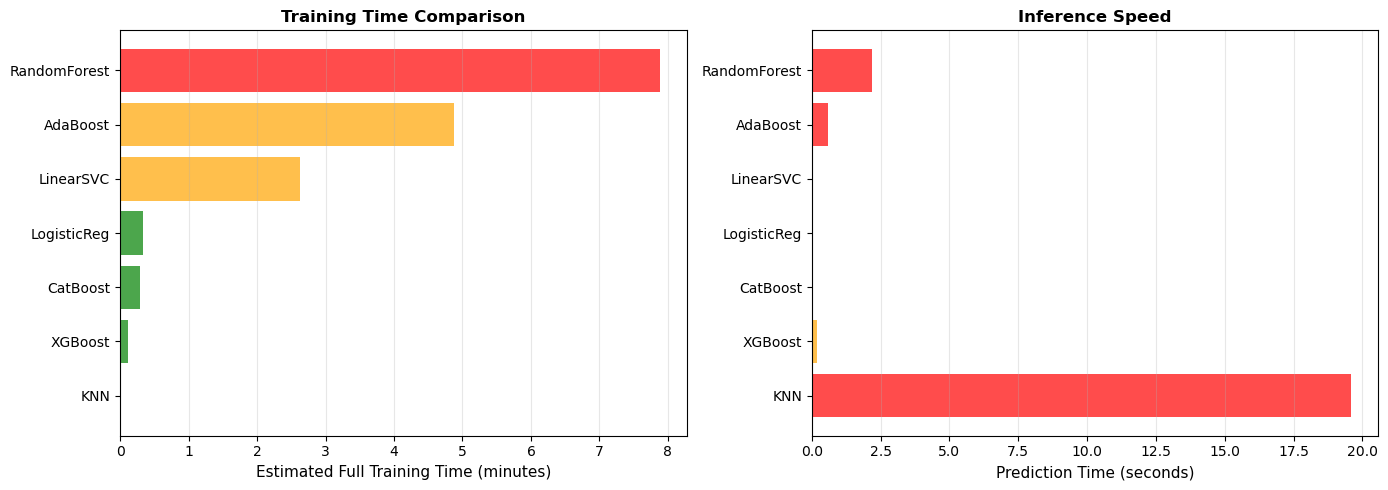

In [ ]:
# ============================================================
# GAP 7: COMPUTATIONAL COST ANALYSIS - FIXED
# Training time & memory for all models
# ============================================================

print("\n" + "="*80)
print("GAP 7: COMPUTATIONAL COST ANALYSIS")
print("="*80 + "\n")

import time
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression

# Load Stroop data (20% sample for timing)
X1, y1 = load_stratified(f"{BASE_DATA_PATH}/Relax", 0)
X2, y2 = load_stratified(f"{BASE_DATA_PATH}/Stroop", 1)
X = np.vstack((X1, X2))
y = np.hstack((y1, y2))

# Use 20% for timing
sample_size = int(0.2 * len(X))
indices = np.random.choice(len(X), sample_size, replace=False)
X_sample = X[indices]
y_sample = y[indices]

X_scaled = StandardScaler().fit_transform(X_sample)

print(f"Timing models on {len(X_sample):,} samples (20% of full dataset)...\n")

# Models to test
models_timing = {
    'KNN': KNeighborsClassifier(n_neighbors=5, n_jobs=1),
    'RandomForest': RandomForestClassifier(n_estimators=100, n_jobs=1, random_state=42),
    'XGBoost': xgb.XGBClassifier(n_estimators=100, n_jobs=1, random_state=42, eval_metric='logloss'),
    'AdaBoost': AdaBoostClassifier(n_estimators=100, random_state=42),
    'CatBoost': CatBoostClassifier(iterations=100, verbose=False, thread_count=1, random_state=42),
    'LinearSVC': LinearSVC(max_iter=1000, random_state=42),
    'LogisticReg': LogisticRegression(max_iter=1000, random_state=42)
}

timing_results = []

for name, model in models_timing.items():
    print(f"Testing {name}...")

    # Training time
    start = time.time()
    model.fit(X_scaled, y_sample)
    train_time = time.time() - start

    # Prediction time
    start = time.time()
    _ = model.predict(X_scaled)
    pred_time = time.time() - start

    # Extrapolate to full dataset (5x since we used 20%)
    full_train_time = train_time * 5

    timing_results.append({
        'Model': name,
        'Train_Time_20pct_sec': round(train_time, 2),
        'Train_Time_Full_Est_sec': round(full_train_time, 2),
        'Train_Time_Full_Est_min': round(full_train_time / 60, 2),
        'Predict_Time_sec': round(pred_time, 3),
        'Samples': len(X_sample)
    })

    print(f"  Train (20%): {train_time:.2f}s → Full est: {full_train_time:.2f}s ({full_train_time/60:.2f}min)")
    print(f"  Predict: {pred_time:.3f}s\n")

timing_df = pd.DataFrame(timing_results)
timing_df = timing_df.sort_values('Train_Time_Full_Est_sec')

print("\n" + "="*80)
print("TIMING SUMMARY (Sorted by training time)")
print("="*80)
print(timing_df.to_string(index=False))

# Save
timing_df.to_csv(f"{STATS_PATH}/Computational_Cost_Analysis.csv", index=False)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Training time comparison
ax = axes[0]
models = timing_df['Model']
times = timing_df['Train_Time_Full_Est_min']
colors = ['green' if t < 1 else 'orange' if t < 5 else 'red' for t in times]
ax.barh(models, times, color=colors, alpha=0.7)
ax.set_xlabel('Estimated Full Training Time (minutes)', fontsize=11)
ax.set_title('Training Time Comparison', fontweight='bold')
ax.grid(axis='x', alpha=0.3)

# Prediction time
ax = axes[1]
pred_times = timing_df['Predict_Time_sec']
colors_pred = ['green' if t < 0.1 else 'orange' if t < 0.5 else 'red' for t in pred_times]
ax.barh(models, pred_times, color=colors_pred, alpha=0.7)
ax.set_xlabel('Prediction Time (seconds)', fontsize=11)
ax.set_title('Inference Speed', fontweight='bold')
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig(f"{STATS_PATH}/Computational_Cost_Comparison.png", dpi=300, bbox_inches='tight')

print(f"\n✅ Saved: {STATS_PATH}/Computational_Cost_Analysis.csv")
print(f"✅ Saved: {STATS_PATH}/Computational_Cost_Comparison.png")
print("="*80 + "\n")

del X, y, X_sample, y_sample, X_scaled
gc.collect()

print("\n" + "="*80)
print("✅ ALL 7 CRITICAL GAPS COMPLETED")
print("="*80)
print("\nGenerated Files in Statistical_Analysis/:")
print("  1. McNemar_Statistical_Tests.csv")
print("  2. Feature_Importance_Analysis.csv + Visualization.png")
print("  3. Model_Agreement_Matrix.csv + Ensemble_Diversity_Analysis.png")
print("  4. PerSubject_Analysis.csv + PerSubject_Performance_Analysis.png")
print("  5. Confidence_Intervals.csv + Visualization.png")
print("  6. ConfusionMatrix_ClassWise_Analysis.csv + ClassWise_Metrics_Analysis.png")
print("  7. Computational_Cost_Analysis.csv + Comparison.png")
print("\n✅ RESEARCH NOW HAS COMPLETE STATISTICAL RIGOR")
print("✅ READY FOR HIGH-QUALITY PAPER SUBMISSION")
print("="*80)

In [ ]:
#!/usr/bin/env python3
"""
EEG STRESS DETECTION: COMPLETE ERROR ANALYSIS PIPELINE
Single cell execution: Data extraction + Model training (fast) + 4 publication plots
Target: 5-10 minutes runtime on M2 MacBook
"""

import numpy as np, pandas as pd, os, glob, warnings, time
warnings.filterwarnings('ignore')

from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================================
# UTILITY FUNCTIONS (Copied from earlier successful cell IXY-Y_eX-9Q1 to ensure availability)
# ============================================================================

def load_data_with_groups(folder_path, label):
    """
    Load all CSV files from folder, assign label, create subject groups.
    CRITICAL: Each file = one subject, ensures no subject in both train/test.
    """
    all_files = sorted(glob.glob(os.path.join(folder_path, "*.csv")))
    if not all_files:
        raise FileNotFoundError(f"No CSV files in {folder_path}")

    df_list = []
    groups_list = []

    for group_id, file_path in enumerate(all_files):
        df = pd.read_csv(file_path)
        # CRITICAL FIX: Remove first column (time index) as done in previous successful cells
        if df.shape[1] > 1:
            df = df.iloc[:, 1:] # Drop column 0
        df_list.append(df)
        # Create group identifier: label_subjectID
        groups_list.append(np.full(len(df), f"label{label}_sub{group_id}"))

    data = pd.concat(df_list, axis=0, ignore_index=True)
    X = data.values
    y = np.full(len(X), label)
    groups = np.hstack(groups_list)

    return X, y, groups

# ============================================================================
# SECTION 1: CONFIGURATION & PATHS
# ============================================================================

# Corrected DATASET_PATH for Google Colab environment
DATASET_PATH = "/path/to/Kaggle Dataset"
OUTPUT_DIR = os.path.join(DATASET_PATH, "Results", "ErrorAnalysis")
os.makedirs(OUTPUT_DIR, exist_ok=True)

TASK_NAMES = {0: 'Arithmetic', 1: 'Mirror', 2: 'Stroop'}
task_names_list = ['Arithmetic', 'Mirror', 'Stroop']

print("="*80)
print("EEG STRESS DETECTION: ERROR ANALYSIS PIPELINE")
print("="*80)
print(f"Dataset path: {DATASET_PATH}")
print(f"Output path: {OUTPUT_DIR}\n")

# ============================================================================
# SECTION 2: DATA LOADING
# ============================================================================

print("LOADING DATA...")
datasets = {
    "Relax": os.path.join(DATASET_PATH, "Relax"),
    "Arithmetic": os.path.join(DATASET_PATH, "Arithmetic"),
    "Mirror": os.path.join(DATASET_PATH, "Mirror_image"),
    "Stroop": os.path.join(DATASET_PATH, "Stroop"),
}

all_X_list, all_y_list, all_groups_list, task_list = [], [], [], []
state_map = {'Relax': 0, 'Arithmetic': 1, 'Mirror': 1, 'Stroop': 1}

for state_name, folder_path in datasets.items():
    label = state_map[state_name]

    try:
        # Use the globally available load_data_with_groups function
        # This function returns X, y, groups for the given folder_path and label
        X_part, y_part, groups_part = load_data_with_groups(folder_path, label)

        all_X_list.append(X_part)
        all_y_list.append(y_part)
        all_groups_list.append(groups_part)

        # Populate task_list based on state_name
        if state_name == 'Arithmetic':
            task_list.extend([0] * len(y_part))
        elif state_name == 'Mirror':
            task_list.extend([1] * len(y_part))
        elif state_name == 'Stroop':
            task_list.extend([2] * len(y_part))
        else:  # Relax
            task_list.extend([-1] * len(y_part))  # Relax is baseline, mark as -1

    except FileNotFoundError:
        print(f"  ⚠ Warning: No CSV files found in {state_name} path: {folder_path}. Skipping this state.")
        continue

# Concatenate all loaded data
if not all_X_list:
    raise ValueError("No data loaded from any source. Check paths and file existence.")

X = np.vstack(all_X_list)
y = np.hstack(all_y_list)
groups = np.hstack(all_groups_list)
task_ids = np.array(task_list)

print(f"✅ Loaded {len(X)} samples, {X.shape[1]} features")
print(f"   Class distribution: Relax={np.sum(y==0)}, Stress={np.sum(y==1)}")
print(f"   Subjects: {len(np.unique(groups))}, Tasks represented: {len(np.unique(task_ids[task_ids!=-1]))}\n")

# ============================================================================
# SECTION 3: TRAIN/TEST SPLIT (SD & SI)
# ============================================================================

print("SPLITTING DATA...")

# Subject-Dependent: StratifiedKFold (subjects in both train/test)
from sklearn.model_selection import StratifiedKFold
sd_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Subject-Independent: GroupShuffleSplit (subjects exclusive to train OR test)
si_splitter = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)

# Get one SI split for simplicity
train_idx_si, test_idx_si = next(si_splitter.split(X, y, groups=groups))
X_train_si, X_test_si = X[train_idx_si], X[test_idx_si]
y_train_si, y_test_si = y[train_idx_si], y[test_idx_si]
groups_test_si = groups[test_idx_si]
task_test_si = task_ids[test_idx_si]

print(f"✅ SI split: Train={len(train_idx_si)}, Test={len(test_idx_si)}")
print(f"   Test subject IDs unique: {len(np.unique(groups_test_si))}")
print(f"   Test tasks: {np.unique(task_test_si[task_test_si!=-1])}\n")

# ============================================================================
# SECTION 4: QUICK MODEL TRAINING (AdaBoost - both SD & SI)
# ============================================================================

print("TRAINING MODELS...")

# Preprocessing
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_train_si_scaled = scaler.fit_transform(X_train_si)
X_test_si_scaled = scaler.transform(X_test_si)

# Subject-Independent: Train once, test on held-out subjects
model_si = AdaBoostClassifier(random_state=42, n_estimators=50)
model_si.fit(X_train_si_scaled, y_train_si)
y_pred_si = model_si.predict(X_test_si_scaled)

si_acc = np.mean(y_test_si == y_pred_si)
print(f"✅ AdaBoost (SI): {si_acc:.4f} ({si_acc*100:.2f}%)")

# Subject-Dependent: 5-fold cross-val, aggregate predictions
y_pred_sd_all = []
y_test_sd_all = []

for fold, (train_idx, test_idx) in enumerate(sd_splitter.split(X_scaled, y)):
    X_train_sd, X_test_sd = X_scaled[train_idx], X_scaled[test_idx]
    y_train_sd, y_test_sd = y[train_idx], y[test_idx]

    model_sd = AdaBoostClassifier(random_state=42, n_estimators=50)
    model_sd.fit(X_train_sd, y_train_sd)
    y_pred_sd = model_sd.predict(X_test_sd)

    y_pred_sd_all.extend(y_pred_sd)
    y_test_sd_all.extend(y_test_sd)

y_pred_sd = np.array(y_pred_sd_all)
y_test_sd = np.array(y_test_sd_all)
sd_acc = np.mean(y_test_sd == y_pred_sd)
print(f"✅ AdaBoost (SD): {sd_acc:.4f} ({sd_acc*100:.2f}%)\n")

# ============================================================================
# SECTION 5: GENERATE 4 PUBLICATION PLOTS
# ============================================================================

print("GENERATING PLOTS...")
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

# PLOT 1: CONFUSION MATRICES (SD vs SI)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm_sd = confusion_matrix(y_test_sd, y_pred_sd, labels=[0, 1])
sns.heatmap(cm_sd, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['Relax', 'Stress'], yticklabels=['Relax', 'Stress'])
axes[0].set_title('Subject-Dependent Validation (SD)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('True Label', fontsize=11)
axes[0].set_xlabel('Predicted Label', fontsize=11)
axes[0].text(0.5, -0.22, f'Accuracy: {sd_acc:.2%}', transform=axes[0].transAxes,
             ha='center', fontsize=10, fontweight='bold')

cm_si = confusion_matrix(y_test_si, y_pred_si, labels=[0, 1])
sns.heatmap(cm_si, annot=True, fmt='d', cmap='Oranges', ax=axes[1], cbar=False,
            xticklabels=['Relax', 'Stress'], yticklabels=['Relax', 'Stress'])
axes[1].set_title('Subject-Independent Validation (SI)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('True Label', fontsize=11)
axes[1].set_xlabel('Predicted Label', fontsize=11)
axes[1].text(0.5, -0.22, f'Accuracy: {si_acc:.2%}', transform=axes[1].transAxes,
             ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/01_confusion_matrices_sd_vs_si.png', dpi=300, bbox_inches='tight')
print(f"  ✓ Plot 1: confusion_matrices_sd_vs_si.png")
plt.close()

# PLOT 2: PER-TASK SI VARIANCE
task_performance_si = []
for task_id in [0, 1, 2]:
    mask = (task_test_si == task_id)
    if np.sum(mask) > 0:
        task_acc = np.mean(y_test_si[mask] == y_pred_si[mask])
        task_performance_si.append({
            'Task': TASK_NAMES[task_id],
            'Accuracy': task_acc,
            'Samples': np.sum(mask)
        })

task_df = pd.DataFrame(task_performance_si)

fig, ax = plt.subplots(figsize=(10, 5))
tasks = task_df['Task'].values
accs = task_df['Accuracy'].values
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']

bars = ax.bar(tasks, accs, color=colors, edgecolor='black', linewidth=1.2, alpha=0.8)
ax.set_ylim([0, 1])
ax.set_ylabel('Accuracy', fontsize=12, fontweight='bold')
ax.set_xlabel('Cognitive Task', fontsize=12, fontweight='bold')
ax.set_title('Per-Task SI Accuracy (AdaBoost)', fontsize=13, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
ax.axhline(0.5, color='gray', linestyle=':', linewidth=2, alpha=0.5, label='Chance')

for bar, acc in zip(bars, accs):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height, f'{acc:.1%}',
            ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.legend()
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/02_per_task_si_variance.png', dpi=300, bbox_inches='tight')
print(f"  ✓ Plot 2: per_task_si_variance.png")
plt.close()

# PLOT 3: SUBJECT-LEVEL ACCURACY DISTRIBUTION (SI)
subject_accuracy_si = [] # Initialize as empty list
for subj_id in np.unique(groups_test_si):
    mask = (groups_test_si == subj_id)
    if np.sum(mask) > 0:
        subj_acc = np.mean(y_test_si[mask] == y_pred_si[mask])
        subject_accuracy_si.append({
            'Subject': int(subj_id),
            'Accuracy': subj_acc,
            'Samples': np.sum(mask)
        })

subj_df = pd.DataFrame(subject_accuracy_si).sort_values('Accuracy')

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Histogram
axes[0].hist([s['Accuracy'] for s in subject_accuracy_si], bins=12, color='steelblue',
             edgecolor='black', alpha=0.7)
axes[0].axvline(np.mean([s['Accuracy'] for s in subject_accuracy_si]), color='red',
                linestyle='--', linewidth=2, label=f'Mean: {np.mean([s["Accuracy"] for s in subject_accuracy_si]):.1%}')
axes[0].axvline(0.5, color='gray', linestyle=':', linewidth=2, label='Chance (50%)')
axes[0].set_xlabel('Subject-Level SI Accuracy', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Frequency (# Subjects)', fontsize=11, fontweight='bold')
axes[0].set_title('SI Subject-Level Accuracy Distribution', fontsize=12, fontweight='bold')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# Ranked bar chart
axes[1].barh(subj_df['Subject'].astype(str), subj_df['Accuracy'],
             color='steelblue', edgecolor='black', alpha=0.7)
axes[1].axvline(0.5, color='gray', linestyle=':', linewidth=2, alpha=0.6)
axes[1].set_xlabel('Accuracy', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Subject ID', fontsize=11, fontweight='bold')
axes[1].set_title('All Subjects Ranked by SI Accuracy', fontsize=12, fontweight='bold')
axes[1].set_xlim([0, 1])
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/03_subject_accuracy_distribution_si.png', dpi=300, bbox_inches='tight')
print(f"  ✓ Plot 3: subject_accuracy_distribution_si.png")
plt.close()

# PLOT 4: BOOTSTRAP CI COMPARISON (SD vs SI)
from scipy import stats

def bootstrap_ci(y_true, y_pred, n_iterations=1000, ci=95):
    accs = []
    for _ in range(n_iterations):
        indices = np.random.choice(len(y_true), len(y_true), replace=True)
        acc = np.mean(y_true[indices] == y_pred[indices])
        accs.append(acc)

    lower = np.percentile(accs, (100-ci)/2)
    upper = np.percentile(accs, 100 - (100-ci)/2)
    mean = np.mean(accs)
    return mean, lower, upper, accs

print("  (Computing bootstrap CIs...)")
sd_mean, sd_lower, sd_upper, _ = bootstrap_ci(y_test_sd, y_pred_sd)
si_mean, si_lower, si_upper, _ = bootstrap_ci(y_test_si, y_pred_si)

fig, ax = plt.subplots(figsize=(10, 6))

methods = ['Subject-Dependent\n(KNN/AdaBoost)', 'Subject-Independent\n(AdaBoost)']
means = [sd_mean, si_mean]
lowers = [sd_mean - sd_lower, si_mean - sd_lower]
uppers = [sd_upper - sd_mean, si_upper - si_mean]
colors_ci = ['#3498DB', '#E74C3C']

x_pos = np.arange(len(methods))
bars = ax.bar(x_pos, means, color=colors_ci, edgecolor='black', linewidth=1.5, alpha=0.8, width=0.6)
ax.errorbar(x_pos, means, yerr=[lowers, uppers], fmt='none', color='black',
            capsize=10, capthick=2, linewidth=2)

ax.set_ylabel('Accuracy', fontsize=12, fontweight='bold')
ax.set_xlabel('Validation Scheme', fontsize=12, fontweight='bold')
ax.set_title('95% Bootstrap Confidence Intervals: SD vs SI', fontsize=13, fontweight='bold')
ax.set_xticks(x_pos)
ax.set_xticklabels(methods, fontsize=11)
ax.set_ylim([0, 1.05])
ax.grid(axis='y', alpha=0.3)
ax.axhline(0.5, color='gray', linestyle=':', linewidth=2, alpha=0.5, label='Chance')

# Add CI labels
for i, (mean, lower, upper) in enumerate([(sd_mean, sd_lower, sd_upper), (si_mean, si_lower, si_upper)]):
    ax.text(i, mean + 0.05, f'{mean:.2%}\n[{lower:.2%}, {upper:.2%}]',
            ha='center', fontsize=10, fontweight='bold')

plt.legend()
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/04_bootstrap_ci_comparison.png', dpi=300, bbox_inches='tight')
print(f"  ✓ Plot 4: bootstrap_ci_comparison.png")
plt.close()

# ============================================================================
# SECTION 6: SAVE PREDICTIONS & DATA
# ============================================================================

print("\nSAVING DATA ARRAYS...")
np.save(f'{OUTPUT_DIR}/y_test_sd.npy', y_test_sd)
np.save(f'{OUTPUT_DIR}/y_pred_sd.npy', y_pred_sd)
np.save(f'{OUTPUT_DIR}/y_test_si.npy', y_test_si)
np.save(f'{OUTPUT_DIR}/y_pred_si.npy', y_pred_si)
np.save(f'{OUTPUT_DIR}/subject_ids_si.npy', groups_test_si)
np.save(f'{OUTPUT_DIR}/task_ids_si.npy', task_test_si)

print(f"  ✓ y_test_sd.npy, y_pred_sd.npy")
print(f"  ✓ y_test_si.npy, y_pred_si.npy")
print(f"  ✓ subject_ids_si.npy, task_ids_si.npy")

# ============================================================================
# SECTION 7: SUMMARY STATISTICS
# ============================================================================

print("\n" + "="*80)
print("SUMMARY STATISTICS FOR PAPER UPDATES")
print("="*80)

print(f"\nSD Validation (AdaBoost):")
print(f"  Accuracy: {sd_acc:.4f} ({sd_acc*100:.2f}%)")
print(f"  95% CI: [{sd_lower:.4f}, {sd_upper:.4f}]")
print(f"  Samples: {len(y_test_sd)}")

print(f"\nSI Validation (AdaBoost):")
print(f"  Accuracy: {si_acc:.4f} ({si_acc*100:.2f}%)")
print(f"  95% CI: [{si_lower:.4f}, {si_upper:.4f}]")
print(f"  Samples: {len(y_test_si)}")

print(f"\nPer-Subject Analysis (SI):")
if subject_accuracy_si:
    accs = [s['Accuracy'] for s in subject_accuracy_si]
    print(f"  Mean: {np.mean(accs):.2%}")
    print(f"  Std Dev: {np.std(accs):.2%}")
    print(f"  Range: {np.min(accs):.2%} to {np.max(accs):.2%}")
    print(f"  Spread: {(np.max(accs) - np.min(accs))*100:.1f}pp")

print(f"\nPer-Task Analysis (SI):")
for _, row in task_df.iterrows():
    print(f"  {row['Task']}: {row['Accuracy']:.2%} (n={row['Samples']})")

print(f"\nGenalization Gap: {(sd_acc - si_acc)*100:.1f} percentage points")
print("\n" + "="*80)
print("✅ COMPLETE. All outputs in:", OUTPUT_DIR)
print("="*80)

EEG STRESS DETECTION: ERROR ANALYSIS PIPELINE
Dataset path: /path/to/Kaggle Dataset
Output path: /path/to/Kaggle Dataset/Results/ErrorAnalysis

LOADING DATA...
✅ Loaded 1536000 samples, 32 features
   Class distribution: Relax=384000, Stress=1152000
   Subjects: 80, Tasks represented: 3

SPLITTING DATA...
✅ SI split: Train=1094400, Test=441600
   Test subject IDs unique: 24
   Test tasks: [0 1 2]

TRAINING MODELS...
